# Staple Paths: Weighting, Reversed Pieces, Cut at M and Piece Length

Fits the committor (`CommittorNE`, CuPy, NPNEq) to one staple simulation under several data preparations and compares the results, against the exact committor when one is available. Every configuration uses the same paths, the same fit settings and the same random seed; only the preparation of the data differs. The simulation is chosen with a preset (`SYSTEM`): the 1D flat Brownian run or the 2D Brownian Z run, or one you add.

**What is varied** (one entry of `CONFIGS` per fit):

| Key | Values | Meaning |
|---|---|---|
| `weights` | `rejections`, `staple`, `none` | MC path weights from tistools (`tis_data.read_path_info`): `rejections` counts a path once per cycle it stays the current path; `staple` also applies the high-acceptance factor for shot LML/RMR paths; `none` counts every accepted path once |
| `reversed` | `False`, `True` | also use every path's mirrored piece (from its start to its last M crossing, read backwards); needs time-reversible dynamics at equilibrium |
| `cut` | `True`, `False` | cut every path at its first frame past M. Without the cut, the frames before that crossing are conditioned on crossing M later (biased; for comparison only, and not combinable with `reversed`) |
| `max_length` | `None` or N frames | limit every piece (after the cut) to N frames |
| `long_pieces` | `truncate`, `discard` | what to do with longer pieces: keep their first N frames, or drop them |

**Piece length.** Truncating a piece a fixed number of frames after its start is a stopping rule (stop at whichever comes first: the path's own end or frame N). A truncated piece is therefore still a valid stopped segment and should not bias the committor; it only removes data, and with it the longest lags of the stopped Z_q. Discarding long pieces instead selects pieces on how they continue: the long ones are those that linger between the interfaces. That biases the data, and it is in the list to show by how much. The limit applies to each piece separately, so with `reversed` the forward and mirrored piece of a path are truncated or dropped independently.

**Yardstick.** Each fit's stopped Z_q (`zqs_z`, the worst |Z_q / standard error|) is computed on its own data, so a biased data set can still pass its own test. The common yardstick is the exact committor (`q_exact_of`): fit − exact along λ (and per (λ, CV 1) bin for 2D data), and the RMS over frames with 0.05 < q_exact < 0.95, weighted by the path weights.

Each configuration's results are cached in `<OUT>/<name>/summary.npz`, together with its `plots_tis` and metrics figures. A configuration that already has a summary is not fitted again unless `RERUN = True`, so the comparison in section 5 can be redrawn, and configurations added, without repeating earlier fits. `OUT` contains the simulation's name, so the two systems do not share a cache.

## 1. Imports

In [1]:
import argparse
import json
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cupy as cp
from scipy.interpolate import RegularGridInterpolator

plt.rc('font', size=10)
plt.rc('axes', titlesize=12)
plt.rc('axes', labelsize=12)
plt.rc('legend', fontsize=9)

# Custom optimal-RC / committor package (CuPy) and the path-data loader of the examples
REPO = '/home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs'
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs
import tis_data
FIG = f'{REPO}/examples/figures_by_potential'

## 2. Settings

**System.** `SYSTEM` picks a preset; each preset sets:

| Name | Meaning |
|---|---|
| `TIS_DIR`, `LAMBDA_A`, `LAMBDA_B` | the run and its states A and B (`None`: first and last interface) |
| `PATHS_PER_ENSEMBLE`, `PATH_SEED` | random subset of accepted paths per ensemble (`None` = all) |
| `WARMUP_ITER`, `MAX_ITER` | iterations of the warm-up (wide envelope) and of the main run |
| `MAX_LENGTH` | piece-length limit of the truncate/discard configurations, in frames |
| `q_exact_of(X_all)` | exact committor per frame from the CVs, or `None` (the fits are then compared to `BASELINE`) |
| `EDGES`, `LABELS` | bins and axis labels: one entry for a profile along λ only (1D), two for (λ, CV 1) maps as well (`EDGES = None`: chosen from the first loaded data) |
| `CONTOURS` | `(g1, g2, V, levels)`: grey potential contours on the maps, or `None` |

Presets: `1d_flat` (`sim_istar0br10intf`, flat 1D overdamped; exact committor linear) and `2d_z` (`sim_istarz_br_g10`, 2D Brownian Z potential; exact committor on a grid). For another simulation, add a branch with the same names.

**Paths.** The subset draw only depends on the seed and on which paths have a nonzero weight, so every configuration gets the same paths (as long as its weighting gives every accepted path a nonzero weight, which is true for `rejections`, `staple` and `none`).

**Fit.** The same for every configuration: random CV per iteration, seed `FIT_SEED`. Rough cost: about 0.4 s per iteration on 20M frames, so a `2d_z` configuration takes about 2 hours, a `1d_flat` one (7.6M frames, 3000 iterations) well under one.

In [6]:
SYSTEM = '1d_flat'                 # '1d_flat' or '2d_z'; add a preset below for another simulation
SIMS = '/home/staff7/fbsskr/Notebooks/Students/elias/data/simulations'

if SYSTEM == '1d_flat':
    # 1D flat potential, overdamped: gamma = 1, kT = 1, dt = 2e-4. Median piece about 60 frames.
    TIS_DIR = f'{SIMS}/sim_istar0br10intf'
    LAMBDA_A, LAMBDA_B = -0.1, 0.8
    PATHS_PER_ENSEMBLE = 1000     # 7.6M frames; all 33M do not fit the GPU for the stopped Z_q
    PATH_SEED = 0
    WARMUP_ITER, MAX_ITER = 1000, 4000
    CHUNK = 1000                   # iterations between shown and saved plots
    MAX_LENGTH = 200               # frames, for the piece-length configurations
    EDGES = (np.linspace(LAMBDA_A, LAMBDA_B, 91),)
    LABELS = ('order parameter $\\lambda$',)
    CONTOURS = None

    # Exact committor: linear, with the boundaries shifted out by the mean overshoot of a
    # discrete Brownian step (0.5826 step sizes; absorption is checked every step).
    _shift = 0.5826 * np.sqrt(2 * 1.0 * 2e-4 / 1.0)   # sqrt(2 kT dt / gamma)
    def q_exact_of(X):
        return np.clip((X[:, 0] - LAMBDA_A + _shift) / (LAMBDA_B - LAMBDA_A + 2 * _shift), 0, 1)

elif SYSTEM == '2d_z':
    # 2D Brownian Z potential sjoelbak_angle(Lx=0.3, angle=45): gamma = 10, kT = 0.05, dt = 0.002.
    TIS_DIR = f'{SIMS}/sim_istarz_br_g10'
    LAMBDA_A, LAMBDA_B = 0.05, 0.85
    PATHS_PER_ENSEMBLE = 1000
    PATH_SEED = 12
    WARMUP_ITER, MAX_ITER = 1000, 15000
    CHUNK = 5000
    MAX_LENGTH = 200
    EDGES = (np.linspace(0.05, 0.85, 81), np.linspace(-0.01, 0.31, 33))
    LABELS = ('order parameter $y$', '$x$')

    # Exact committor: finite-volume solution on a (y, x) grid (figures_by_potential/2d_zpot/brownian_g10/reference_and_analyses/committor_reference.py)
    _ref = np.load(f'{FIG}/z_brownian/committor_reference_h0.001.npz')
    _f_ref = RegularGridInterpolator((_ref['y'], _ref['x']), _ref['q'], bounds_error=False, fill_value=None)
    def q_exact_of(X):
        return np.clip(_f_ref(X[:, :2]), 0, 1)
    _in = (_ref['y'] >= -0.01) & (_ref['y'] <= 0.91)
    _V = _ref['V_eff'][_in]
    CONTOURS = (_ref['y'][_in], _ref['x'], _V, np.linspace(np.percentile(_V, 1), np.percentile(_V, 92), 14))

else:
    raise ValueError(f'unknown SYSTEM {SYSTEM!r}')

# --- shared by both systems ---
N_CVS = None                       # train on the first N CVs (None = all in order.txt)
FIT_SEED = 0                       # CV and envelope-centre draws
WARMUP_ENVELOPE, ENVELOPE = 1000000, 0.01
GAMMA = 0.
FIT_KW = dict(ny=6, print_step=500, min_delta_x=1e-6, lazy_basis=True, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
# Plots after the warm-up and after every chunk, shown here and saved as <OUT>/<name>/seed<FIT_SEED>/it<N>_<plot>.png.
# All of the library's plots; feps and obs_pred are the standard (unstopped) versions, biased for path segments.
PLOTS = ('metrics', 'tis', 'feps', 'obs_pred', 'obs_pred_log')
METRICS_PLOTTED = ['delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x']
MIN_COUNT = 20                     # frames a bin needs to be shown
_sim = os.path.basename(TIS_DIR.rstrip('/'))
STAPLE_COMPARE_DIRS = {'sim_istar0br10intf': '1d_flat/brownian_staple', 'sim_istarz_br_g10': '2d_zpot/brownian_g10/staple',
                       'sim_istar_cc_br': '2d_curved_channel/brownian_g10'}
OUT = f'{FIG}/{STAPLE_COMPARE_DIRS.get(_sim, "_unsorted/staple_compare_" + _sim)}/staple_compare_p{PATHS_PER_ENSEMBLE}_s{PATH_SEED}'
RERUN = True                      # fit again even if a configuration has a summary

## 3. Configurations

Each entry overrides the defaults `weights='rejections'`, `reversed=False`, `cut=True`, `max_length=None`, `long_pieces='truncate'`. `RUN` selects which configurations to fit or load. `BASELINE` is drawn thicker in the plots, and is the reference when there is no exact committor.

`MAX_LENGTH` comes from the preset and is in frames of the saved paths. The piece-length histogram in section 5 (from any configuration without a limit) shows how many pieces a value affects; a useful limit cuts the long tail but keeps most pieces whole.

In [7]:
CONFIGS = [
    dict(name='fwd_rej',    weights='rejections'),
    dict(name='rev_rej',    weights='rejections', reversed=True),
    dict(name='fwd_staple', weights='staple'),
    dict(name='rev_staple', weights='staple',     reversed=True),
    dict(name='fwd_none',   weights='none'),
    dict(name='rev_none',   weights='none',       reversed=True),
    dict(name='nocut_rej',  weights='rejections', cut=False),
    dict(name=f'rev_rej_trunc{MAX_LENGTH}', weights='rejections', reversed=True,
         max_length=MAX_LENGTH, long_pieces='truncate'),
    dict(name=f'rev_rej_disc{MAX_LENGTH}',  weights='rejections', reversed=True,
         max_length=MAX_LENGTH, long_pieces='discard'),
]
RUN = [c['name'] for c in CONFIGS]  # or a subset, e.g. ['fwd_rej', 'rev_rej']
BASELINE = 'rev_rej'

DEFAULTS = dict(weights='rejections', reversed=False, cut=True, max_length=None, long_pieces='truncate')
CONFIGS = [{**DEFAULTS, **c} for c in CONFIGS]
for c in CONFIGS:
    if c['reversed'] and not c['cut']:
        raise ValueError(f"{c['name']}: reversed pieces need the cut at M")
assert len({c['name'] for c in CONFIGS}) == len(CONFIGS), 'configuration names must be unique'
pd.DataFrame(CONFIGS).set_index('name')

,weights,reversed,cut,max_length,long_pieces
name,,,,,
fwd_rej,rejections,False,True,NaN,truncate
rev_rej,rejections,True,True,NaN,truncate
fwd_staple,staple,False,True,NaN,truncate
rev_staple,staple,True,True,NaN,truncate
fwd_none,none,False,True,NaN,truncate
rev_none,none,True,True,NaN,truncate
nocut_rej,rejections,False,False,NaN,truncate
rev_rej_trunc200,rejections,True,True,200.0,truncate
rev_rej_disc200,rejections,True,True,200.0,discard


## 4. Fit Every Configuration

For every configuration in `RUN` without a cached summary:
1. the paths are read with `tis_data.prepare_data` (the same code as `load_tis_data_cupy.py`, with `--weights`, `--reversed`, `--no-cut`, `--max-length` and `--long-pieces`);
2. `CommittorNE` is fitted with `seed_runs.run_seeds` (as in the earlier notebooks, one seed: `FIT_SEED`), with the A/B ends of the pieces as traps for the metrics (`set_fixed_traj_length_trap`; truncated pieces end between the interfaces and are not extended). After the warm-up and after every `CHUNK` iterations, all `PLOTS` plus the fit-vs-exact plots are shown here and saved to `<OUT>/<name>/seed<FIT_SEED>/it<N>_<plot>.png`, with a progress line giving the path-weighted RMS(fit − exact) over frames with 0.05 < q_exact < 0.95:
   - `q_profile`: path-weighted mean q per λ bin next to the exact committor, and fit − exact (both systems);
   - `q_map`: mean q per (λ, CV 1) bin, the exact committor and fit − exact (`seed_runs.committor_map`, 2D data only).
3. the summary is saved: data size, piece lengths, metrics history, fit and exact q per bin, and the RMS of fit − exact. `run_seeds` also saves the final q per frame as `<OUT>/<name>/seed<FIT_SEED>/q_traj.npy`.

The summary describes the final q of the run (not the one with the lowest `zqs_z`, which the fit keeps as `q.r_traj_min_sd_zq`). Its fit time includes the plotting.

In [8]:
import seed_runs

if q_exact_of is None:
    print('No exact committor: the fits are compared with', BASELINE)


def load_config(cfg):
    """The frames of one configuration, read with tis_data.prepare_data."""
    parser = argparse.ArgumentParser()
    tis_data.add_data_arguments(parser)
    argv = [TIS_DIR, '--weights', cfg['weights'], '--long-pieces', cfg['long_pieces']]
    if LAMBDA_A is not None:
        argv += ['--lambda-a', str(LAMBDA_A)]
    if LAMBDA_B is not None:
        argv += ['--lambda-b', str(LAMBDA_B)]
    if PATHS_PER_ENSEMBLE is not None:
        argv += ['--paths-per-ensemble', str(PATHS_PER_ENSEMBLE), '--seed', str(PATH_SEED)]
    if N_CVS is not None:
        argv += ['--n-cvs', str(N_CVS)]
    if cfg['reversed']:
        argv += ['--reversed']
    if not cfg['cut']:
        argv += ['--no-cut']
    if cfg['max_length'] is not None:
        argv += ['--max-length', str(cfg['max_length'])]
    return tis_data.prepare_data(parser.parse_args(argv))


def make_q_for(data):
    """make_q for run_seeds: a fresh CommittorNE on one configuration's frames."""
    def make_q():
        q = optimalrcs.CommittorNE(
            boundary0=data.boundary0, boundary1=data.boundary1,
            i_traj=data.i_traj, t_traj=data.t_traj,
            path_weights=data.path_weights,
            group_traj=data.group_traj,    # forward and mirrored piece of a path: one group
        )
        q.set_fixed_traj_length_trap(data.boundary0 | data.boundary1, 2 ** 16)   # A/B ends as traps, for the metrics
        return q
    return make_q


def binned(coords, edges, val, w, keep):
    """Weighted mean of `val` per bin of `coords` over the frames in `keep`;
    NaN in bins with fewer than MIN_COUNT frames."""
    sample = np.column_stack([c[keep] for c in coords])
    n = np.histogramdd(sample, bins=edges)[0]
    sw = np.histogramdd(sample, bins=edges, weights=w[keep])[0]
    s = np.histogramdd(sample, bins=edges, weights=(w * val)[keep])[0]
    return np.where(n >= MIN_COUNT, s / np.where(sw > 0, sw, 1), np.nan)


def get_edges(data):
    """EDGES, or bins over the free frames of the first data set (then kept for all):
    lambda only for one CV, (lambda, CV 1) for more."""
    global EDGES
    if EDGES is None:
        free = ~(data.boundary0 | data.boundary1)
        X = data.X_all[free]
        EDGES = tuple(np.linspace(*np.percentile(X[:, k], [0.5, 99.5]), 81 if k == 0 else 33)
                      for k in range(min(2, X.shape[1])))
    return EDGES


def make_extras(data):
    """extra_plot for run_seeds: {'q_profile': ..., 'q_map': ... (2D only)}, each q -> figure."""
    X, w = data.X_all, data.path_weights
    free = ~(data.boundary0 | data.boundary1)
    edges = get_edges(data)
    qe = q_exact_of(X) if q_exact_of is not None else None
    bm = seed_runs.BinnedMean((X[:, 0],), edges[:1], free, MIN_COUNT)   # bins found once
    w_mean = bm(w)                                                       # path-weighted mean = bm(w * v) / bm(w)
    mid = (edges[0][1:] + edges[0][:-1]) / 2
    prof_ex = None if qe is None else bm(w * qe) / w_mean

    def q_profile(q):
        P = bm(w * cp.asnumpy(q.r_traj)) / w_mean
        fig, axes = plt.subplots(1, 1 if qe is None else 2, figsize=(6 if qe is None else 13, 4), squeeze=False)
        ax = axes[0, 0]
        ax.plot(mid, P, label='fit')
        if qe is not None:
            ax.plot(mid, prof_ex, 'k--', label='exact')
            D = P - prof_ex
            t = (prof_ex > 0.05) & (prof_ex < 0.95)
            axes[0, 1].plot(mid, D)
            axes[0, 1].axhline(0, color='k', lw=0.8)
            axes[0, 1].set(xlabel=LABELS[0], ylabel='fit $-$ exact',
                           title=f'RMS per bin (0.05 < exact < 0.95) {np.sqrt(np.nanmean(D[t] ** 2)):.4f}')
            axes[0, 1].grid(alpha=0.3)
        ax.set(xlabel=LABELS[0], ylabel='$q$ (path-weighted mean per bin)')
        ax.legend()
        ax.grid(alpha=0.3)
        fig.tight_layout()
        return fig

    extras = {'q_profile': q_profile}
    if len(edges) > 1 and X.shape[1] > 1:
        extras['q_map'] = seed_runs.committor_map(
            [seed_runs.plane(X[:, 0], edges[0], LABELS[0], X[:, 1], edges[1],
                             LABELS[1] if len(LABELS) > 1 else 'CV 1', contours=CONTOURS)],
            mask=free, q_ref=qe, min_count=MIN_COUNT)
    return extras


def make_report(data):
    """report for run_seeds: path-weighted RMS(fit - exact) over frames with 0.05 < q_exact < 0.95."""
    if q_exact_of is None:
        return None
    qe = q_exact_of(data.X_all)
    trans = ~(data.boundary0 | data.boundary1) & (qe > 0.05) & (qe < 0.95)
    idx, qe_g, w_g = (cp.asarray(a) for a in (np.flatnonzero(trans), qe[trans], data.path_weights[trans]))

    def report(q):
        d = q.r_traj[idx] - qe_g
        return f'| RMS(fit - exact) {float(cp.sqrt(cp.sum(w_g * d * d) / cp.sum(w_g))):.4f}'
    return report


def summarize(q, data, cfg, t_fit):
    """Everything section 5 needs from one fit, as arrays for np.savez."""
    r = cp.asnumpy(q.r_traj)
    X, w = data.X_all, data.path_weights
    free = ~(data.boundary0 | data.boundary1)
    edges = get_edges(data)
    s = dict(cfg=json.dumps(cfg), t_fit=t_fit, n_frames=len(r),
             n_pieces=len(np.unique(data.i_traj)), n_paths=len(np.unique(data.group_traj)),
             piece_lengths=np.bincount(data.i_traj).astype(np.int32),
             edges_lam=edges[0])
    for key in ('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x'):
        s[f'hist_{key}'] = np.array([float(v) for v in q.metrics_history.get(key, [])])
    s['prof_fit'] = binned((X[:, 0],), edges[:1], r, w, free)
    if len(edges) > 1 and X.shape[1] > 1:
        s['edges_cv1'] = edges[1]
        s['map_fit'] = binned((X[:, 0], X[:, 1]), edges, r, w, free)
    if q_exact_of is not None:
        qe = q_exact_of(X)
        trans = free & (qe > 0.05) & (qe < 0.95)
        s['rms_frames'] = np.sqrt(np.sum(w[trans] * (r[trans] - qe[trans]) ** 2) / np.sum(w[trans]))
        s['prof_exact'] = binned((X[:, 0],), edges[:1], qe, w, free)
        if 'map_fit' in s:
            s['map_exact'] = binned((X[:, 0], X[:, 1]), edges, qe, w, free)
        # RMS per bin over the finest binning: (lambda, CV 1) maps if there are any, else the profile
        fit_b, ex_b = (s['map_fit'], s['map_exact']) if 'map_fit' in s else (s['prof_fit'], s['prof_exact'])
        bins = (ex_b > 0.05) & (ex_b < 0.95)
        s['rms_bins'] = np.sqrt(np.nanmean((fit_b - ex_b)[bins] ** 2))
    return s


def load_summary(path):
    with np.load(path) as d:
        return {k: (d[k][()] if d[k].ndim == 0 else d[k]) for k in d.files}


=== fwd_rej: {'weights': 'rejections', 'reversed': False, 'cut': True, 'max_length': None, 'long_pieces': 'truncate', 'name': 'fwd_rej'} ===
Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/logging.log: [-0.1, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
State A: order <= -0.1, state B: order >= 0.8
Found 10 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/001: loaded 822 paths, 20145 frames, total weight 2137, cut at M = -0.1
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/002: loaded 1000 paths, 65002 frames, total weight 1945, cut at M = 0.0
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/003: loaded 1000 paths, 74269 frames, total weight 1917, cut at M = 0.1
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0b

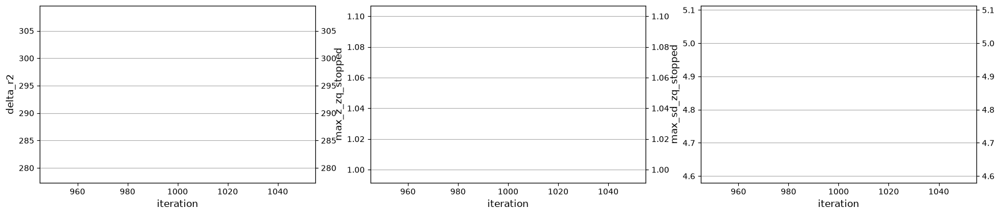

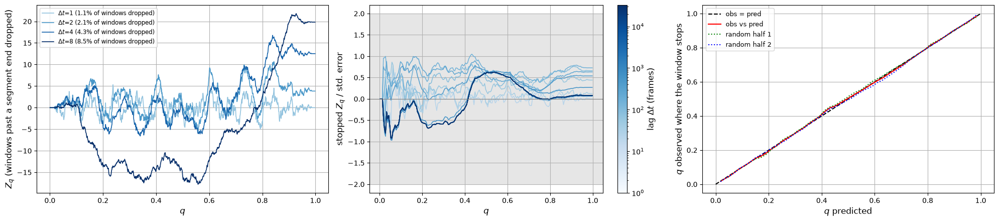

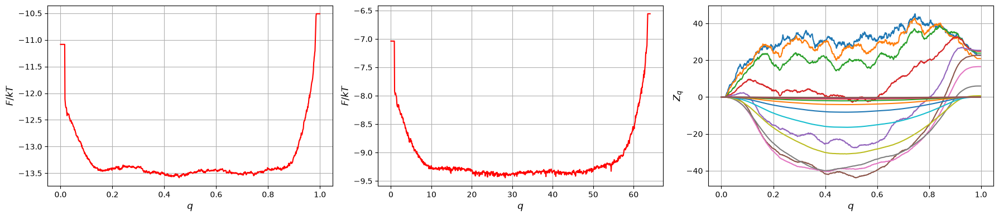

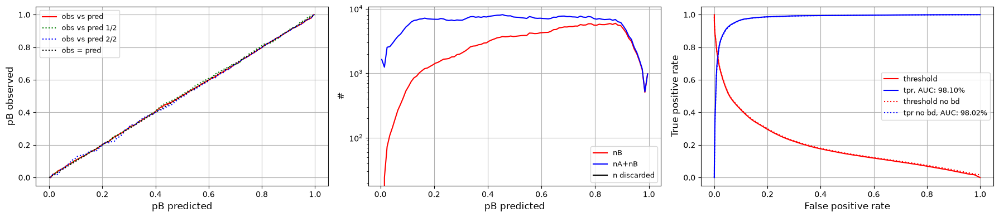

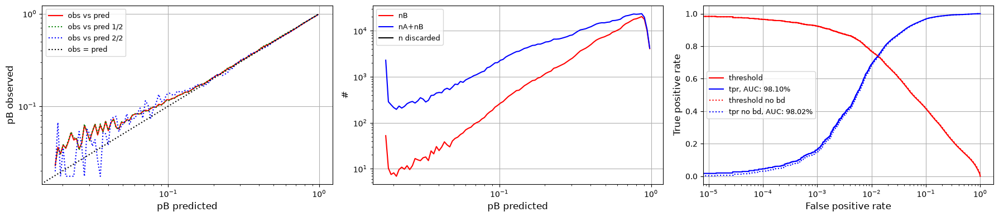

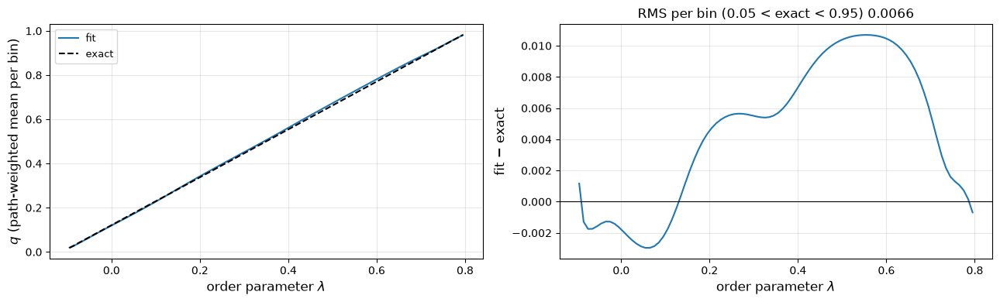

seed 0, 1000 iterations (warm-up: envelope 1000000, gamma 0.0) | RMS(fit - exact) 0.0068
#=1500, dr2=293.464, zqs_z=1.02744, sdzqs=4.76004, |dx|=0.000319601, time=1.26548
#=2000, dr2=293.432, zqs_z=1.0159, sdzqs=4.79168, |dx|=0.000127192, time=2.52374
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/fwd_rej/seed0/it2000 ---


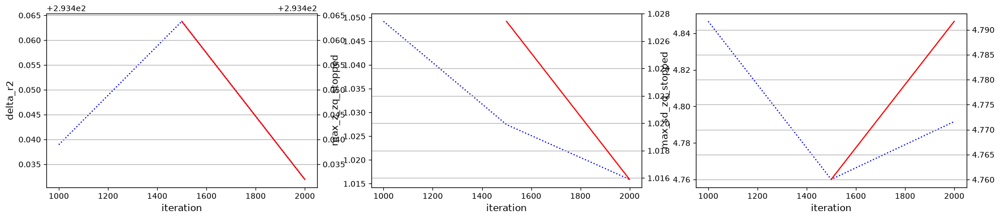

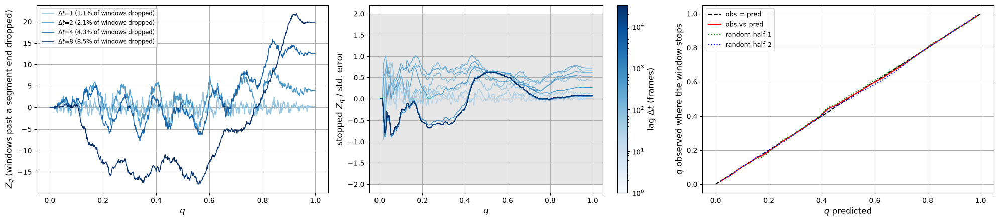

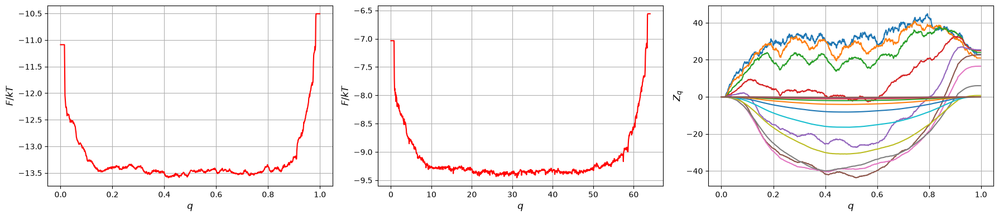

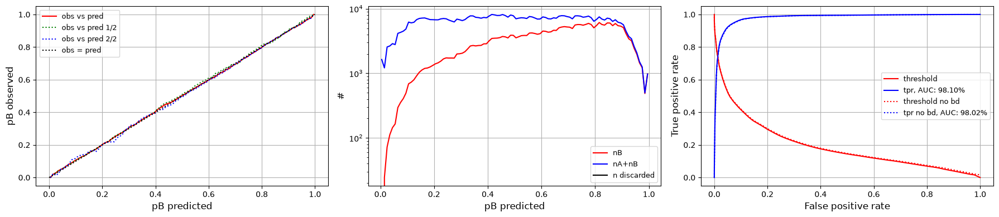

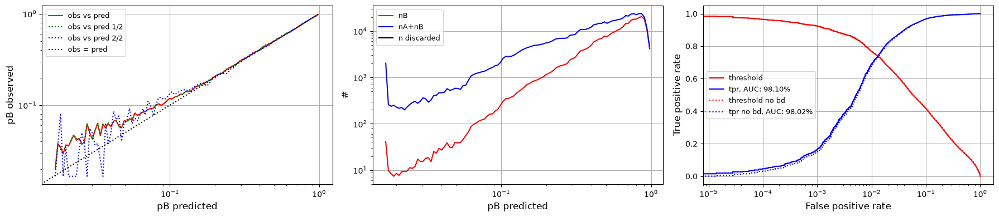

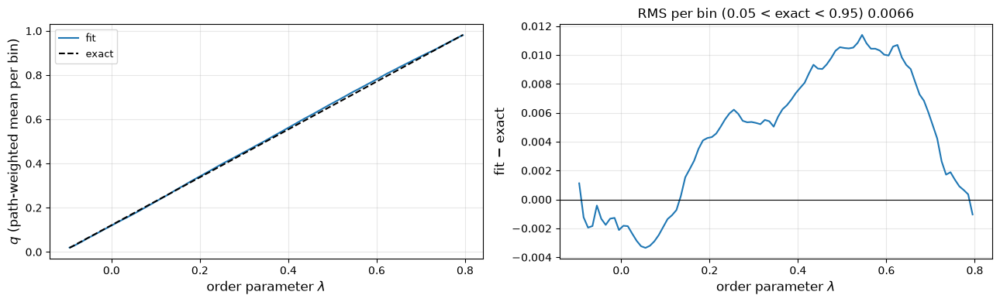

seed 0, 2000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0068
#=2500, dr2=293.463, zqs_z=1.10814, sdzqs=4.76304, |dx|=9.98383e-05, time=1.26112
#=3000, dr2=293.458, zqs_z=1.0904, sdzqs=4.78767, |dx|=4.12727e-05, time=2.51972
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/fwd_rej/seed0/it3000 ---


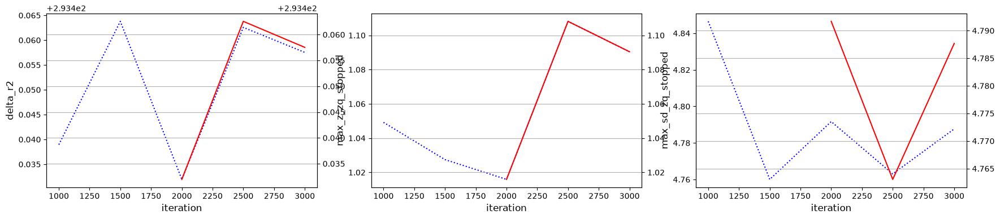

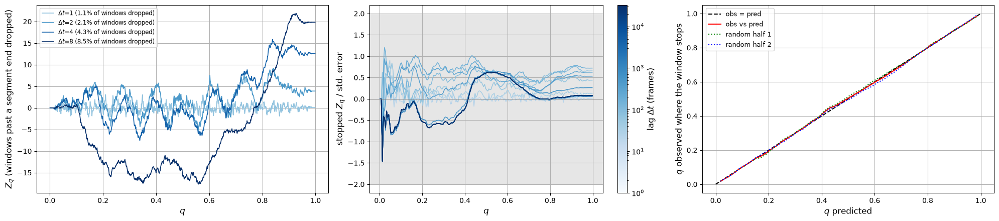

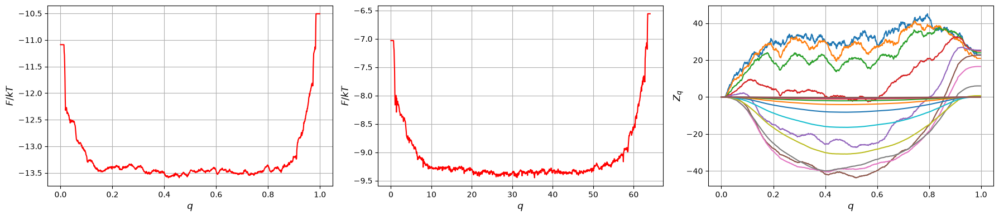

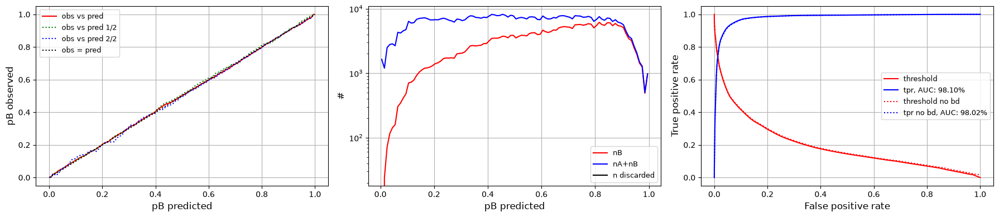

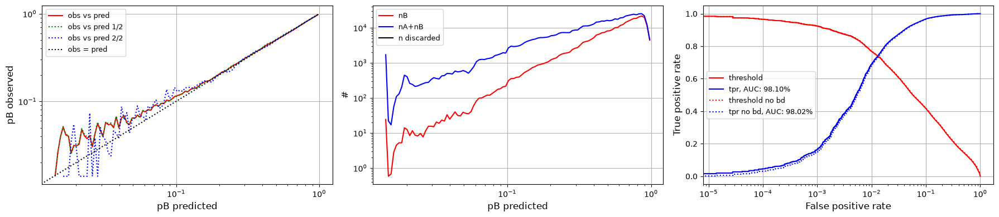

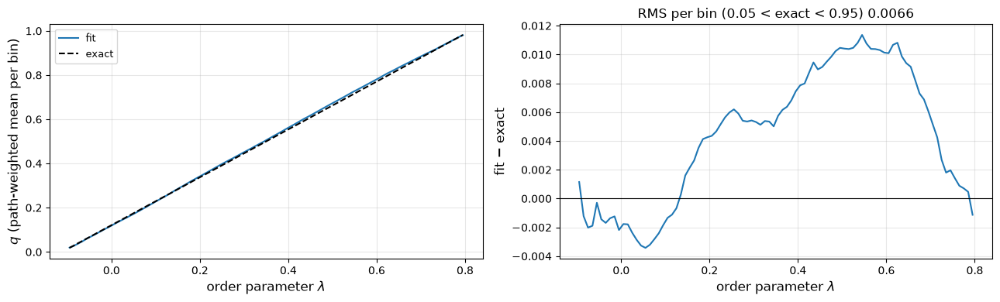

seed 0, 3000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0068
#=3500, dr2=293.472, zqs_z=1.07999, sdzqs=4.78139, |dx|=6.37908e-05, time=1.25805
#=4000, dr2=293.464, zqs_z=1.14382, sdzqs=4.79676, |dx|=5.1551e-05, time=2.51883
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/fwd_rej/seed0/it4000 ---


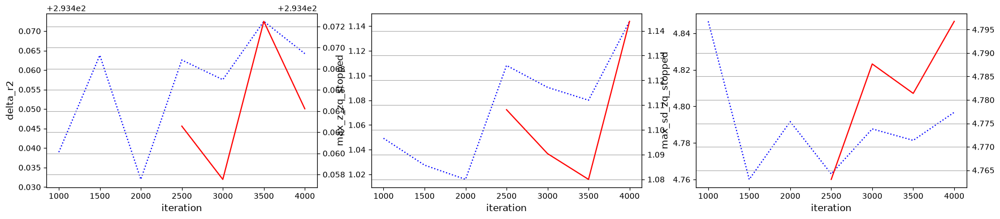

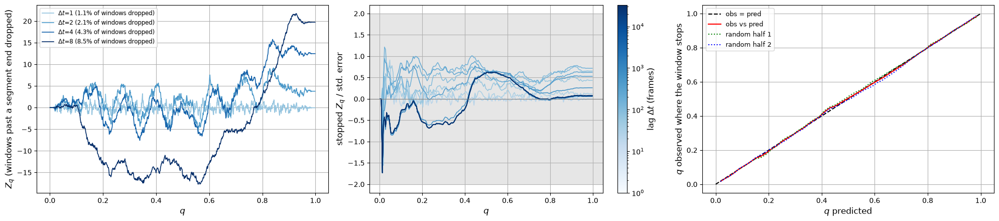

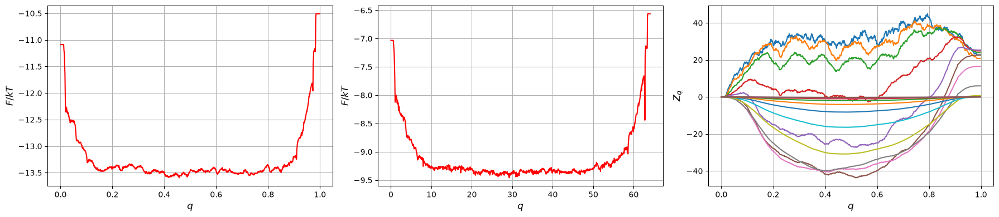

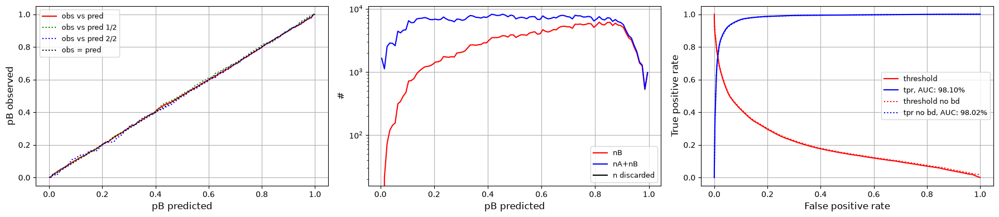

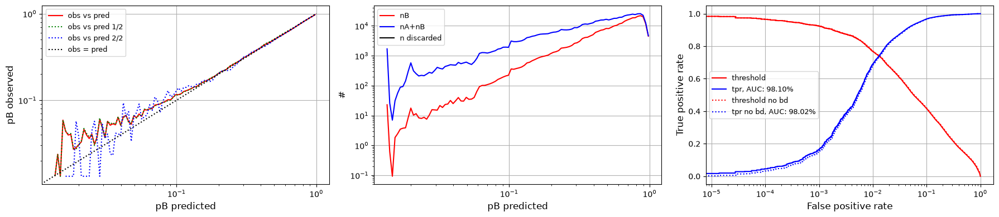

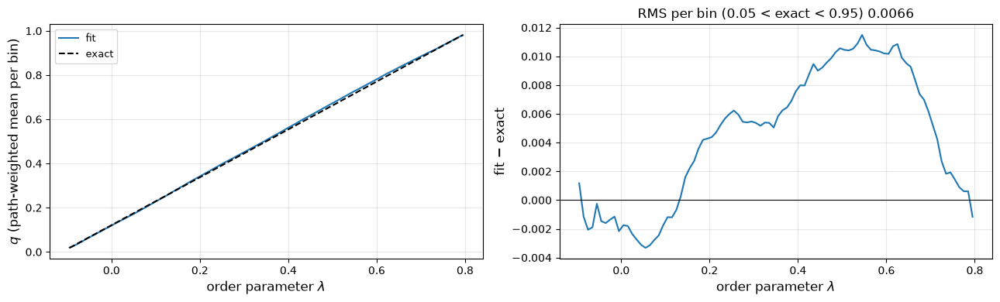

seed 0, 4000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0068
#=4500, dr2=293.467, zqs_z=1.16203, sdzqs=4.80232, |dx|=5.50122e-05, time=1.25461
#=5000, dr2=293.473, zqs_z=1.13779, sdzqs=4.80216, |dx|=2.61309e-05, time=2.51315
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/fwd_rej/seed0/it5000 ---


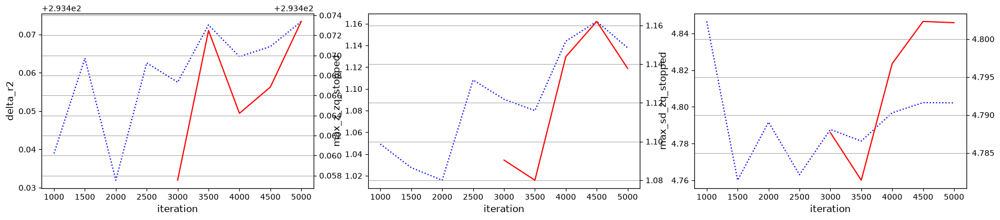

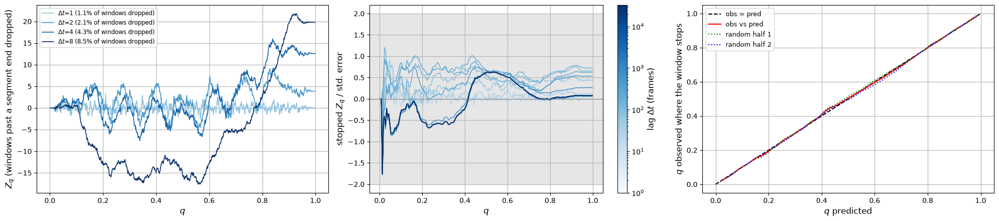

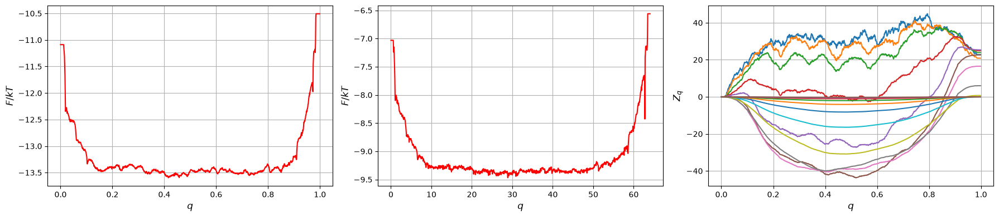

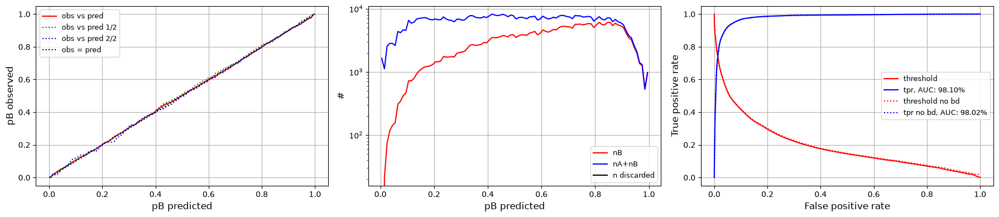

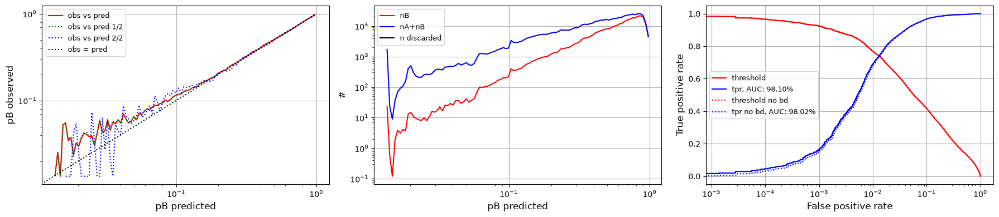

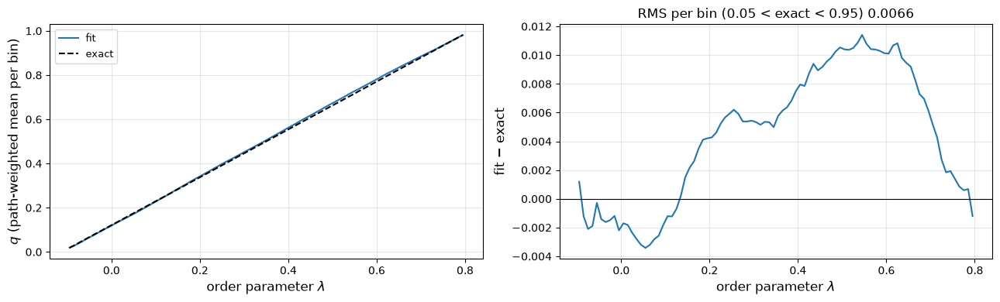

seed 0, 5000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0068
seed 0: | RMS(fit - exact) 0.0068
fwd_rej: done in 0.01 h, zqs_z 1.14, RMS(fit - exact) 0.0068

=== rev_rej: {'weights': 'rejections', 'reversed': True, 'cut': True, 'max_length': None, 'long_pieces': 'truncate', 'name': 'rev_rej'} ===
Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/logging.log: [-0.1, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
State A: order <= -0.1, state B: order >= 0.8
Found 10 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/001: loaded 1638 pieces, 41405 frames, total weight 4258, cut at M = -0.1
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/002: loaded 2000 pieces, 128054 frames, total weight 3890, cut at M = 0.0
  /home/staff7/fbsskr/Notebooks/Students/elias/da

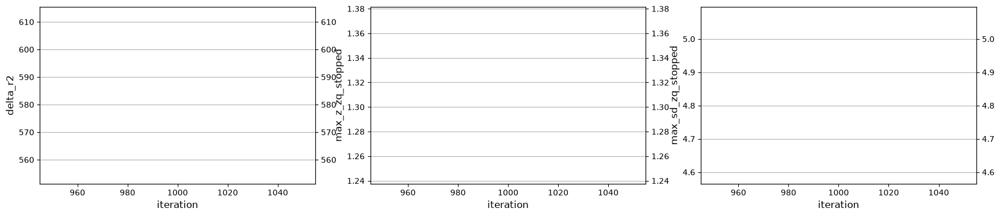

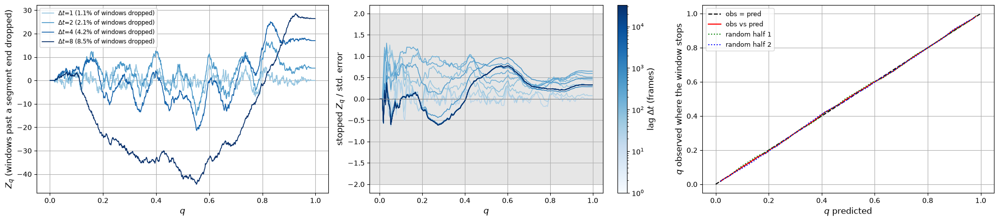

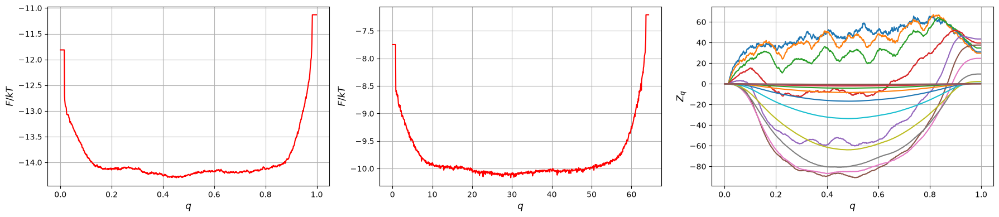

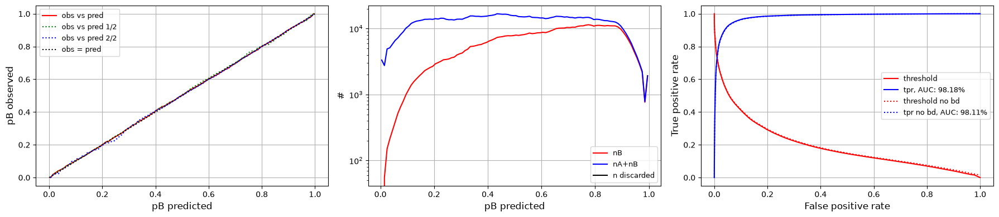

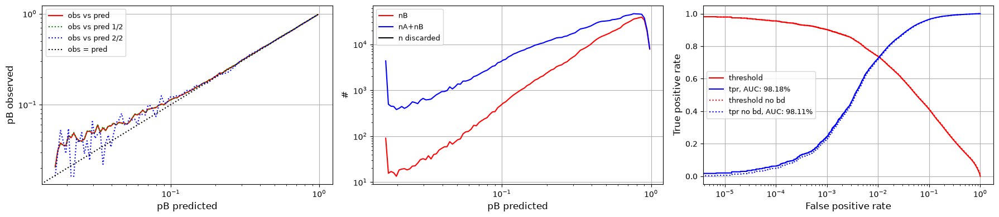

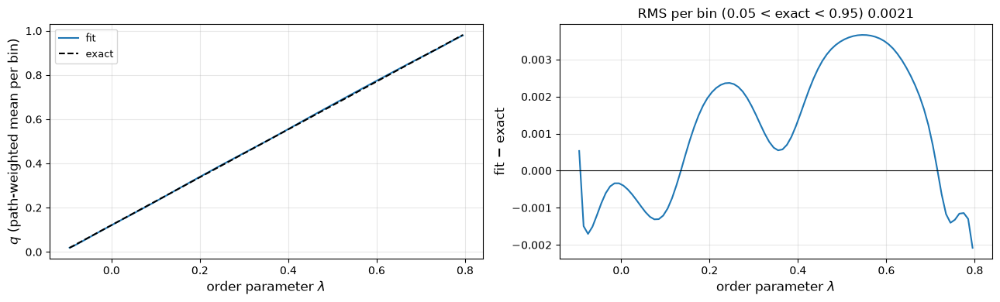

seed 0, 1000 iterations (warm-up: envelope 1000000, gamma 0.0) | RMS(fit - exact) 0.0022
#=1500, dr2=583.445, zqs_z=1.40675, sdzqs=4.69376, |dx|=0.000215212, time=2.24453
#=2000, dr2=583.426, zqs_z=1.41133, sdzqs=4.70453, |dx|=9.19204e-05, time=4.49377
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_rej/seed0/it2000 ---


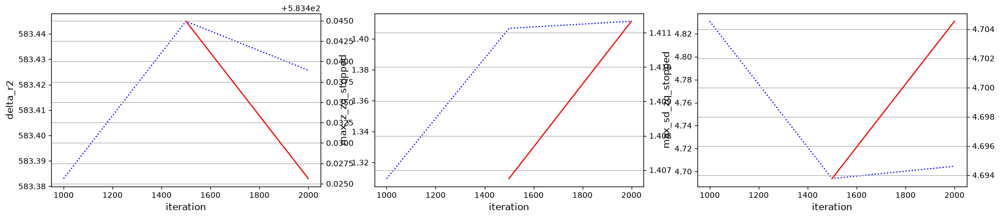

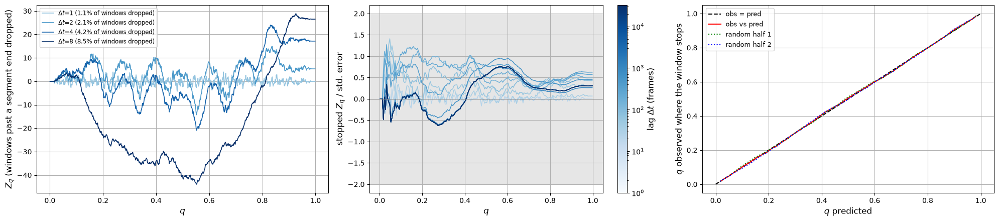

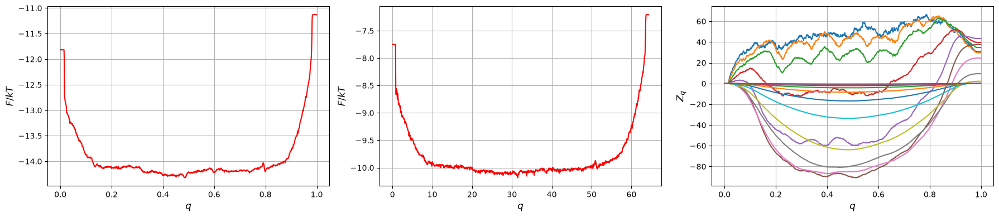

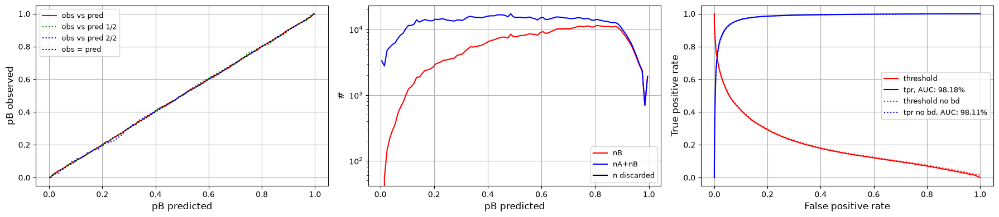

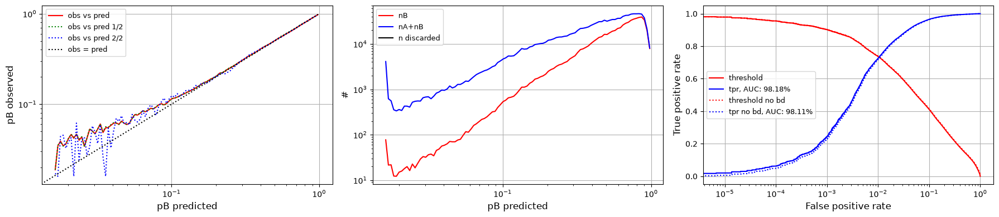

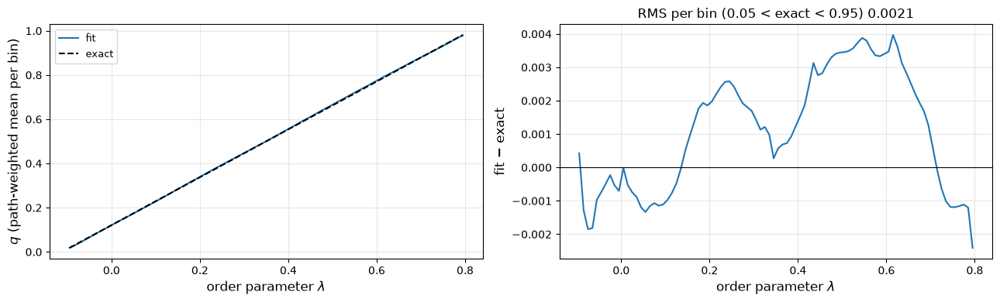

seed 0, 2000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0022
#=2500, dr2=583.417, zqs_z=1.444, sdzqs=4.71425, |dx|=3.98096e-05, time=2.23386
#=3000, dr2=583.399, zqs_z=1.44401, sdzqs=4.72284, |dx|=3.00731e-05, time=4.46947
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_rej/seed0/it3000 ---


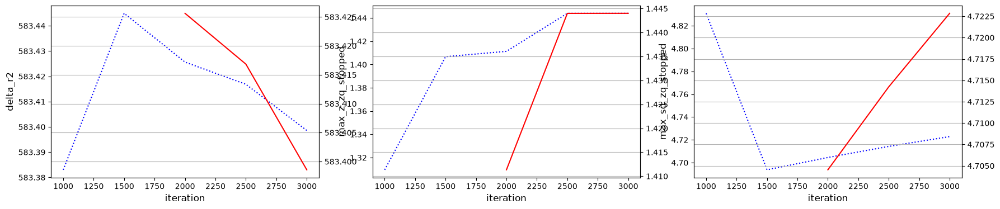

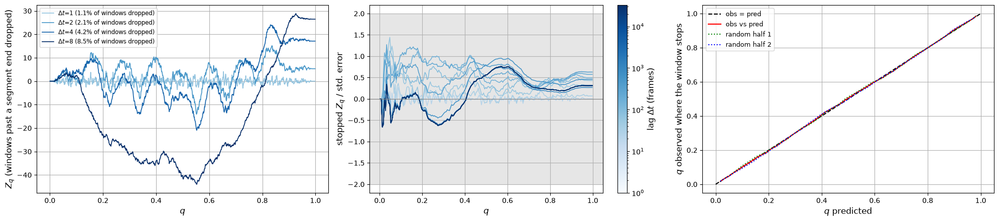

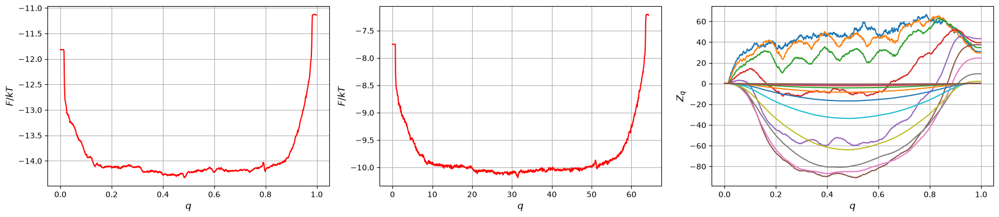

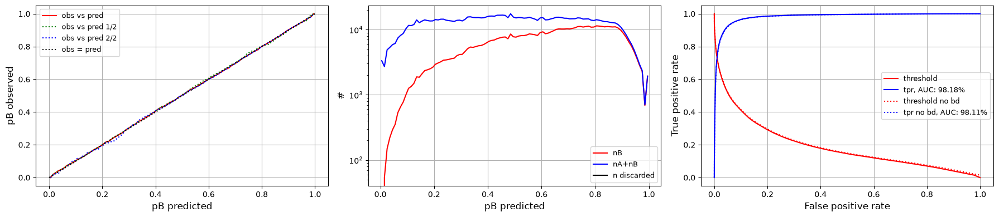

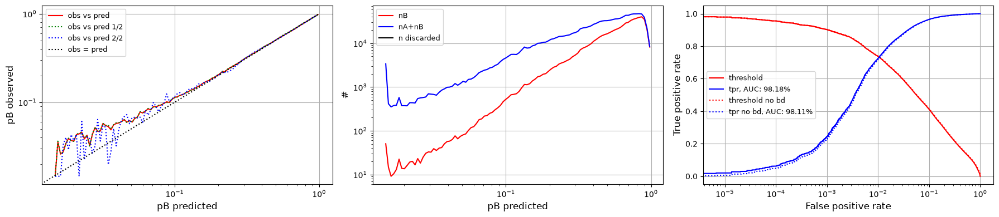

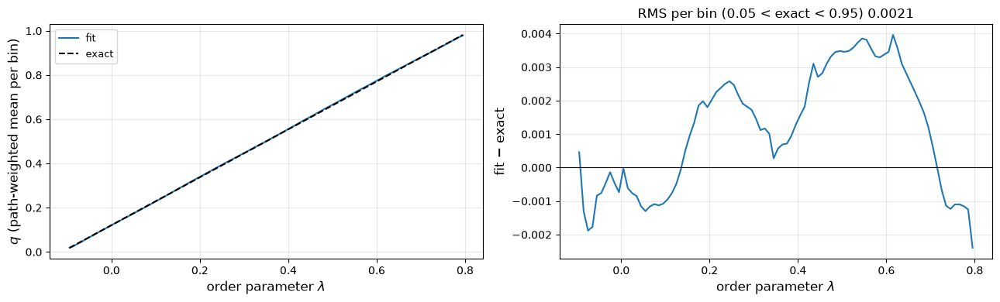

seed 0, 3000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0022
#=3500, dr2=583.408, zqs_z=1.43642, sdzqs=4.72736, |dx|=2.74416e-05, time=2.17531
#=4000, dr2=583.412, zqs_z=1.43566, sdzqs=4.70336, |dx|=3.20882e-05, time=4.35478
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_rej/seed0/it4000 ---


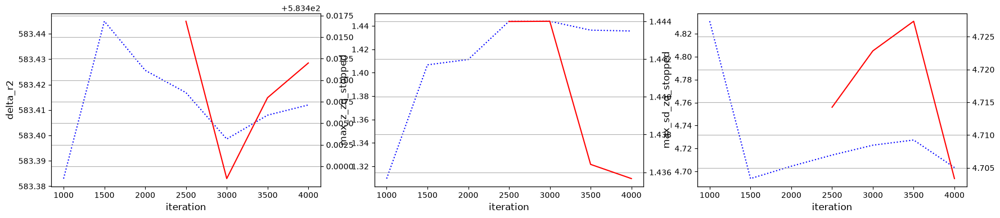

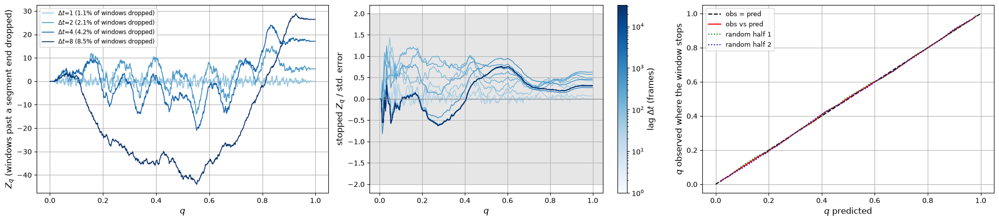

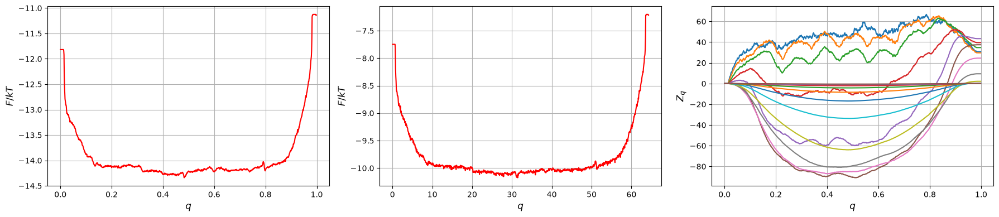

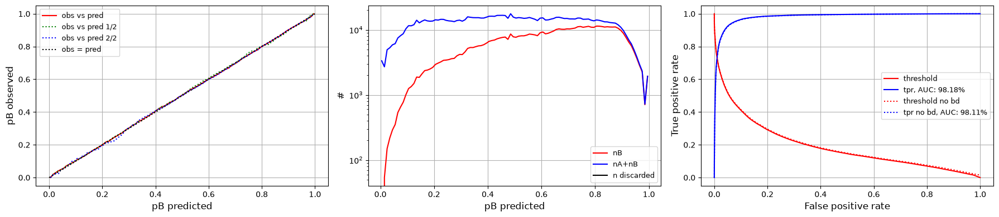

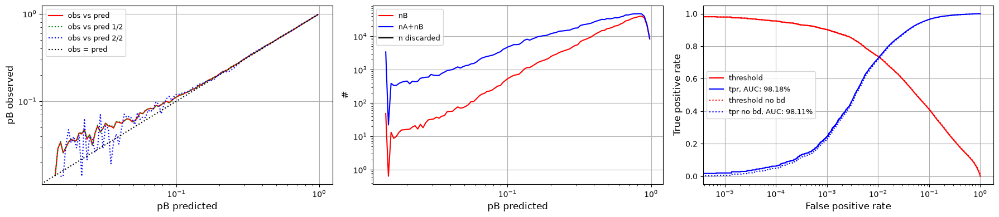

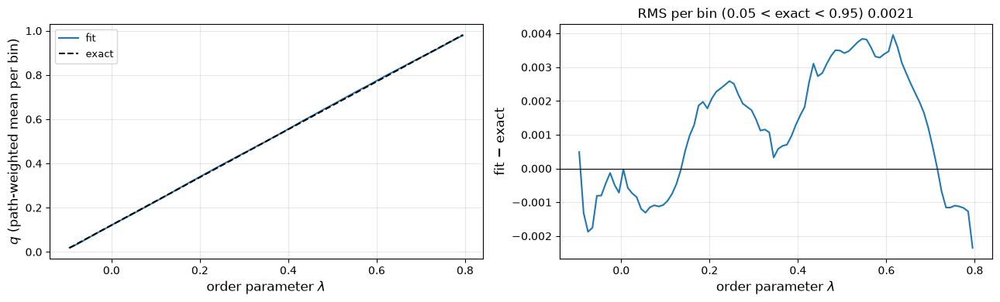

seed 0, 4000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0022
#=4500, dr2=583.414, zqs_z=1.42739, sdzqs=4.7177, |dx|=3.65816e-05, time=2.16673
#=5000, dr2=583.418, zqs_z=1.41385, sdzqs=4.70982, |dx|=2.95637e-05, time=4.3471
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_rej/seed0/it5000 ---


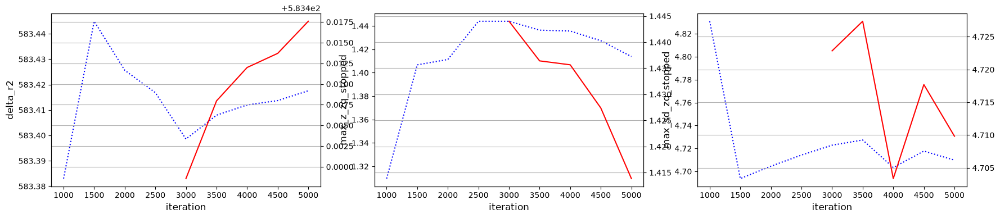

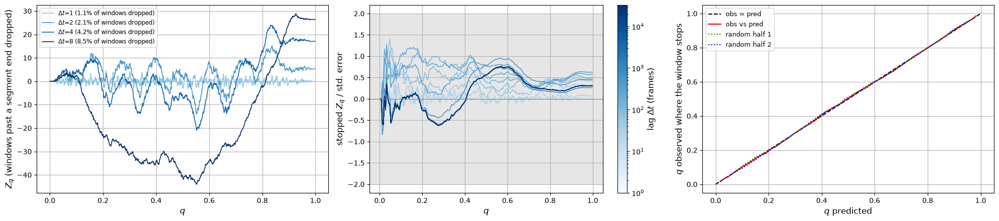

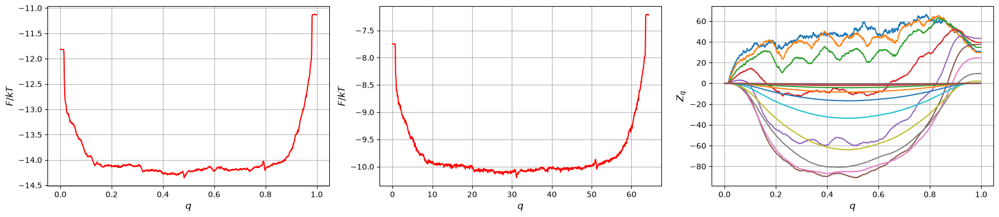

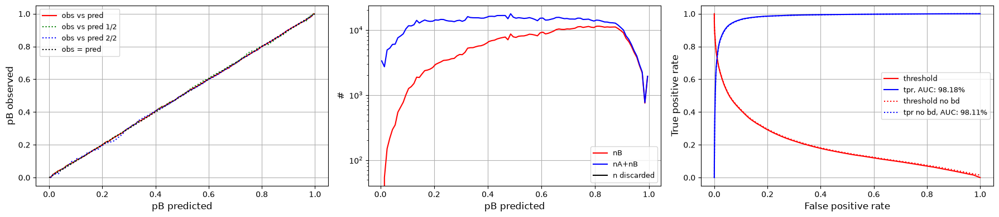

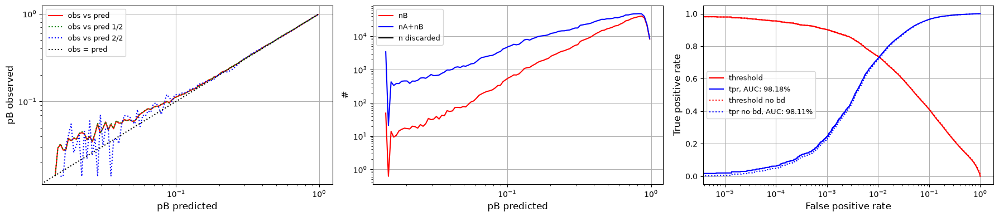

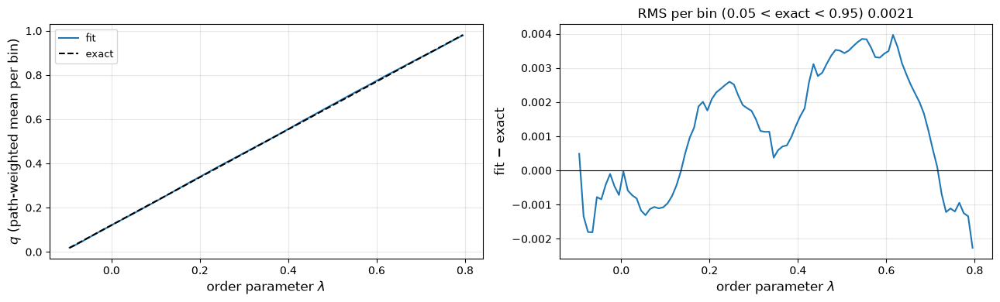

seed 0, 5000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0022
seed 0: | RMS(fit - exact) 0.0022
rev_rej: done in 0.01 h, zqs_z 1.41, RMS(fit - exact) 0.0022

=== fwd_staple: {'weights': 'staple', 'reversed': False, 'cut': True, 'max_length': None, 'long_pieces': 'truncate', 'name': 'fwd_staple'} ===
Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/logging.log: [-0.1, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
State A: order <= -0.1, state B: order >= 0.8
Found 10 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/001: loaded 822 paths, 20145 frames, total weight 2137, cut at M = -0.1
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/002: loaded 1000 paths, 65002 frames, total weight 2361, cut at M = 0.0
  /home/staff7/fbsskr/Notebooks/Students/elias/dat

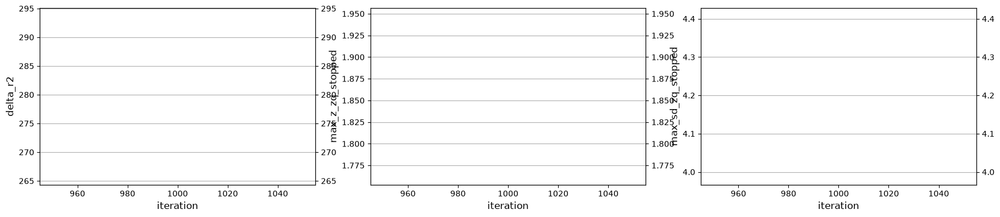

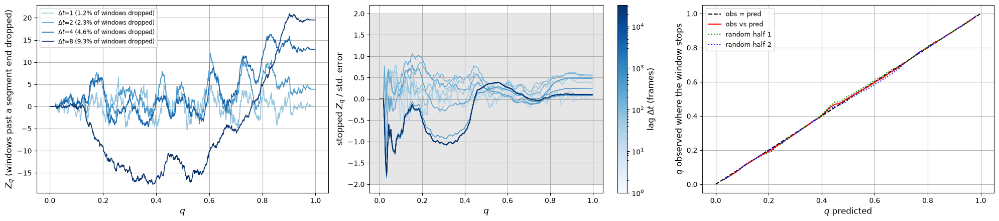

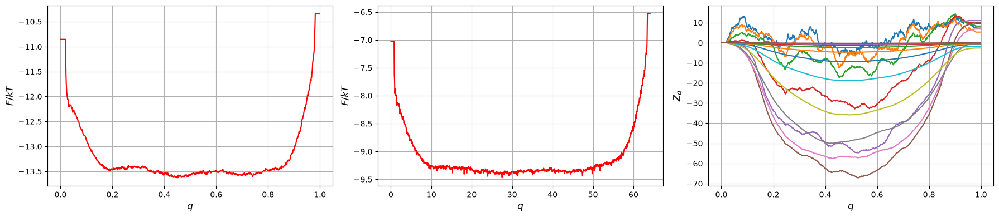

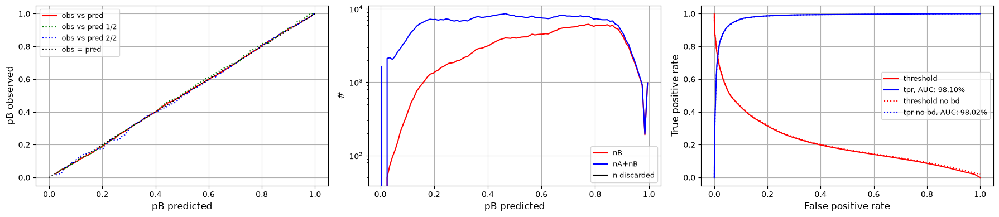

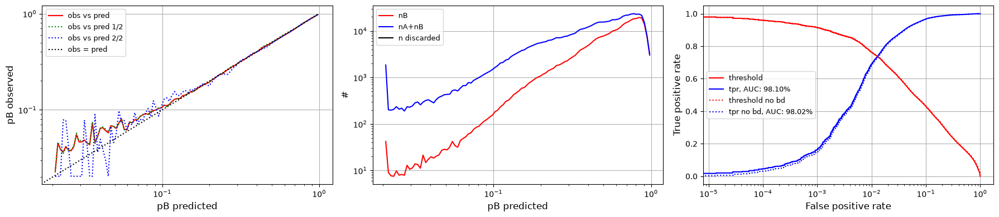

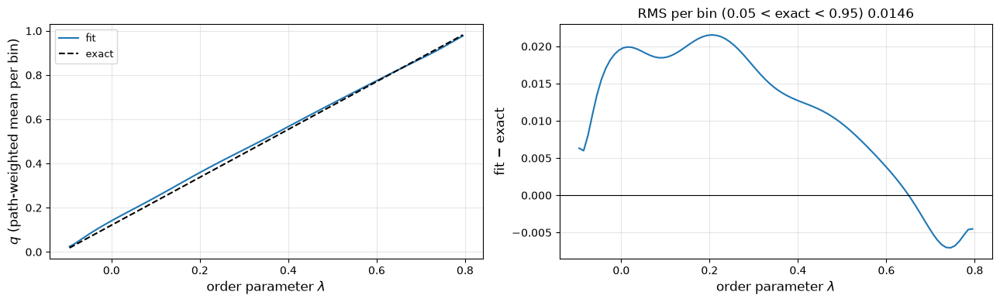

seed 0, 1000 iterations (warm-up: envelope 1000000, gamma 0.0) | RMS(fit - exact) 0.0150
#=1500, dr2=279.782, zqs_z=1.78637, sdzqs=4.17021, |dx|=0.000371713, time=1.26626
#=2000, dr2=279.768, zqs_z=1.57539, sdzqs=4.19331, |dx|=0.000175015, time=2.52837
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/fwd_staple/seed0/it2000 ---


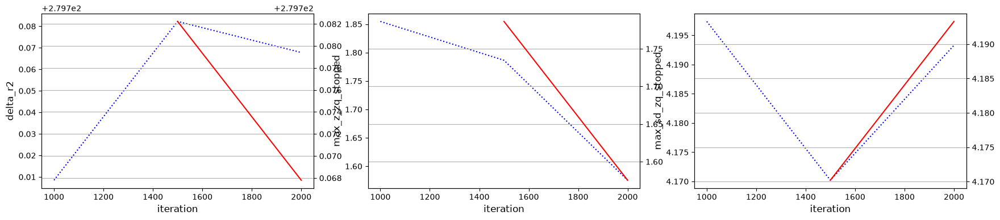

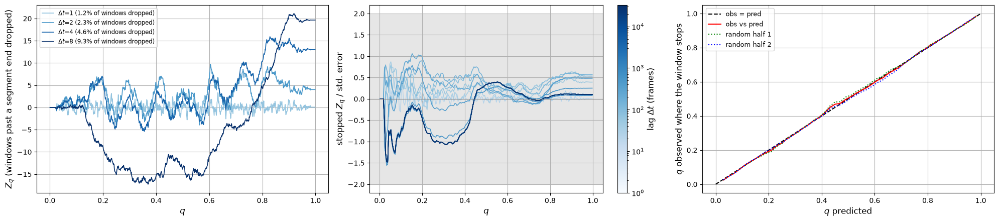

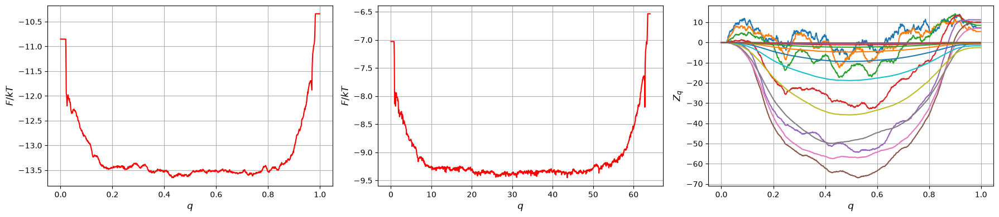

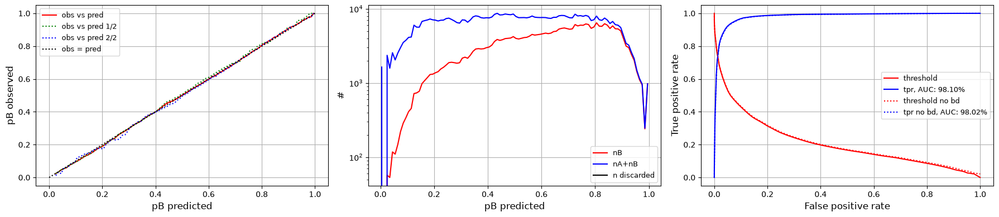

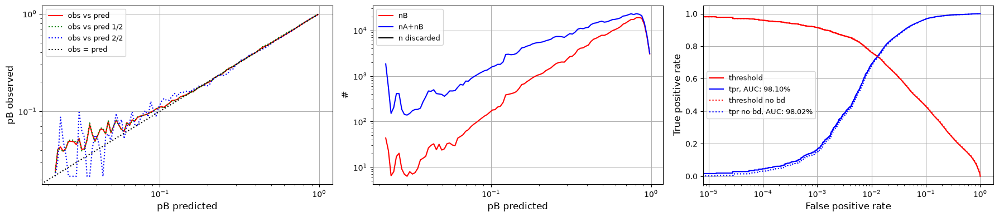

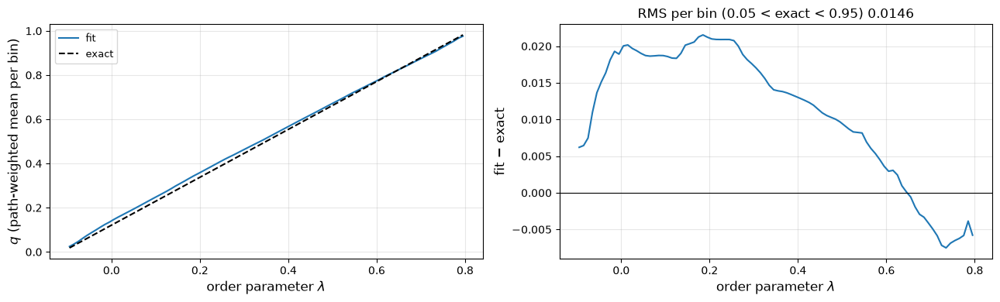

seed 0, 2000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0149
#=2500, dr2=279.799, zqs_z=1.65173, sdzqs=4.182, |dx|=7.61192e-05, time=1.2642
#=3000, dr2=279.799, zqs_z=1.59059, sdzqs=4.1839, |dx|=5.45531e-05, time=2.52915
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/fwd_staple/seed0/it3000 ---


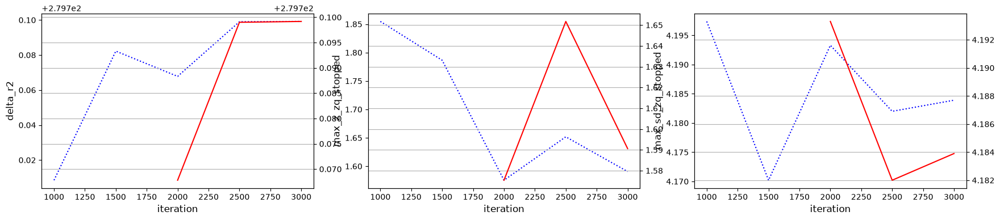

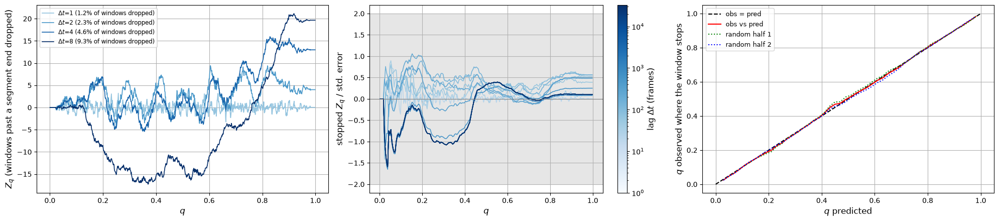

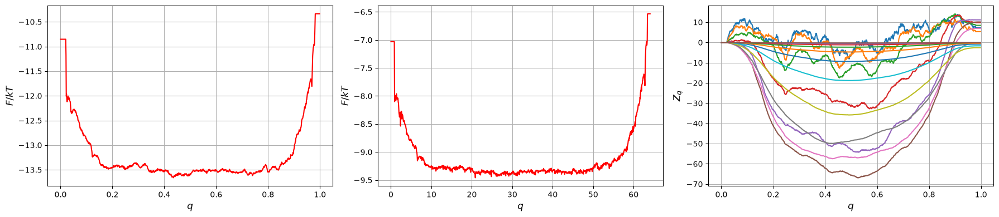

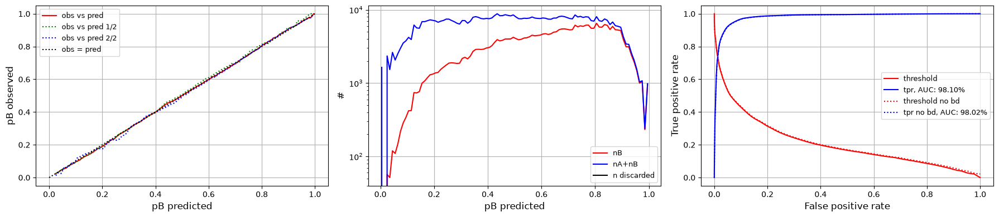

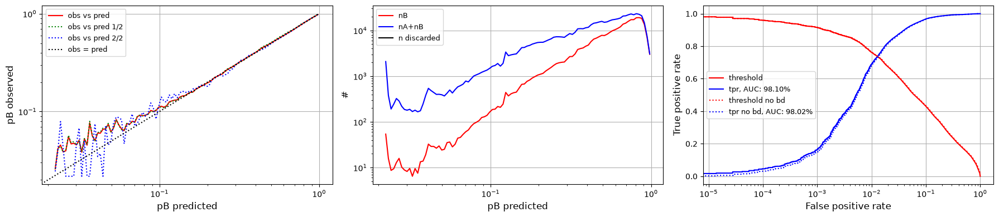

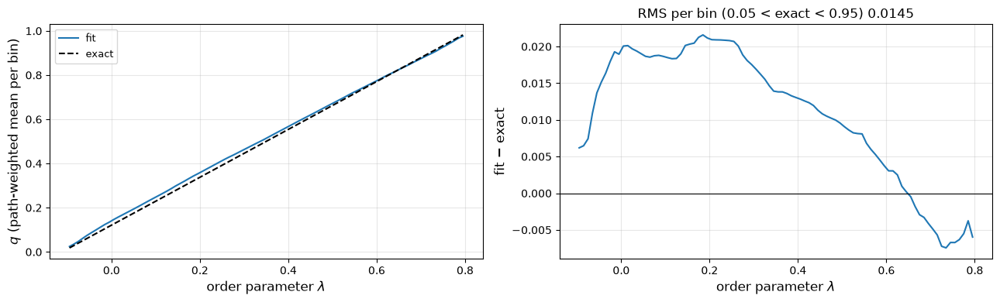

seed 0, 3000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0149
#=3500, dr2=279.816, zqs_z=1.59823, sdzqs=4.18508, |dx|=3.79445e-05, time=1.2574
#=4000, dr2=279.825, zqs_z=1.57387, sdzqs=4.18247, |dx|=0.000134588, time=2.52387
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/fwd_staple/seed0/it4000 ---


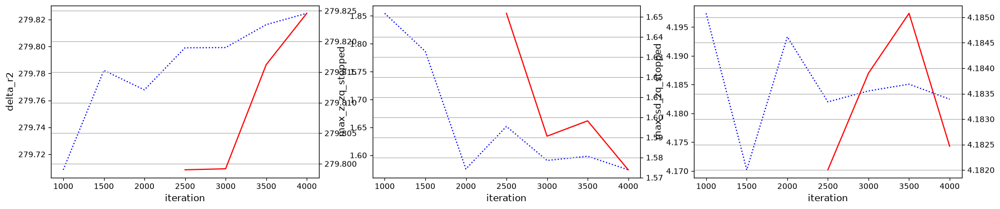

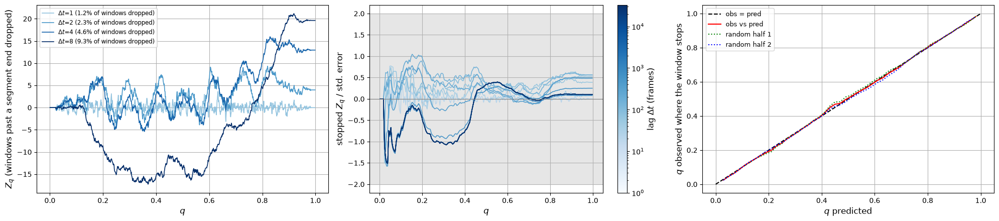

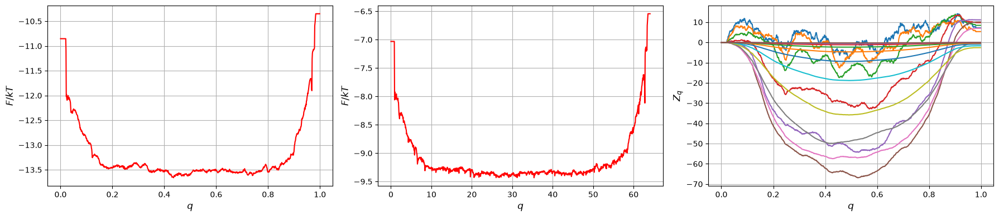

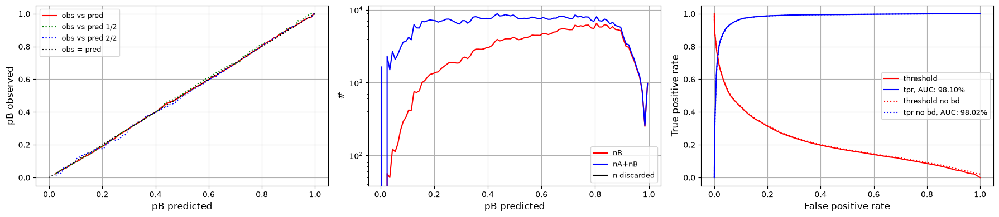

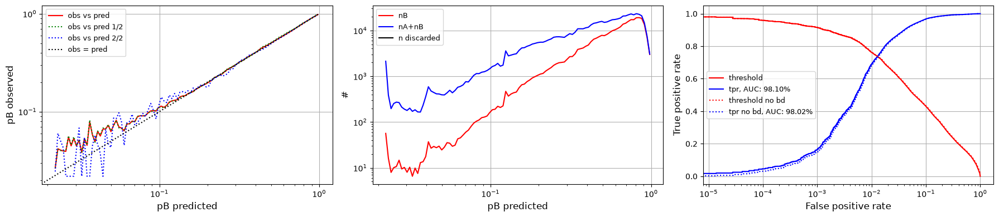

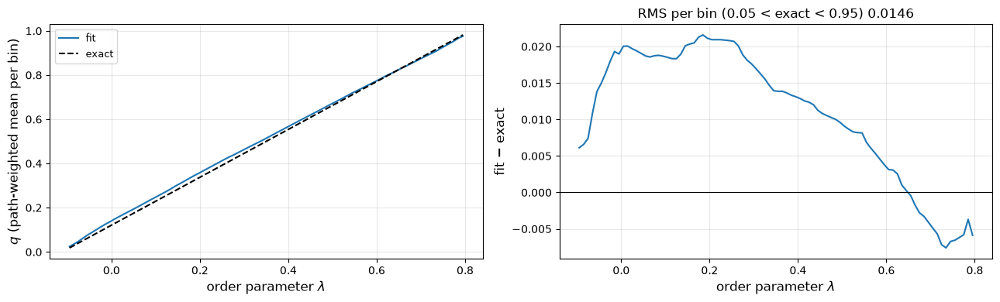

seed 0, 4000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0149
#=4500, dr2=279.828, zqs_z=1.59518, sdzqs=4.1876, |dx|=6.52803e-05, time=1.25671
#=5000, dr2=279.831, zqs_z=1.58875, sdzqs=4.17304, |dx|=3.14254e-05, time=2.52598
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/fwd_staple/seed0/it5000 ---


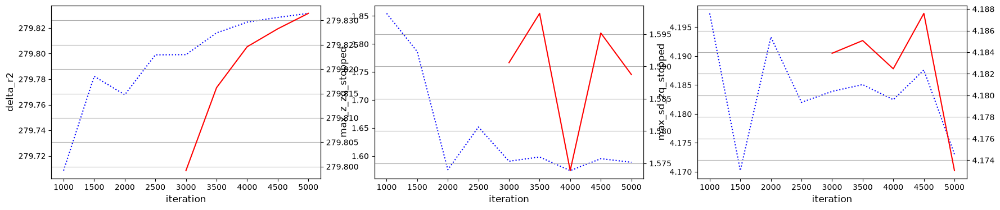

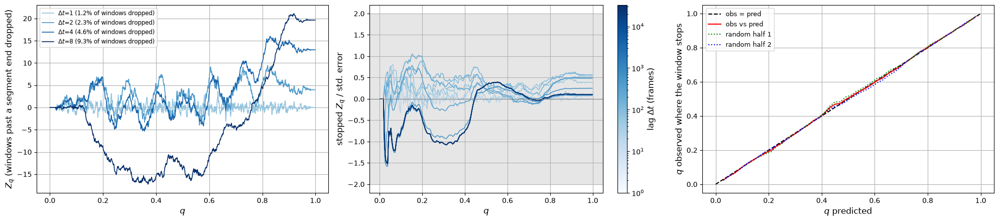

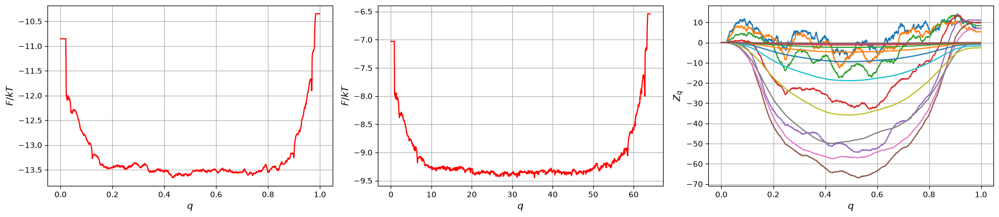

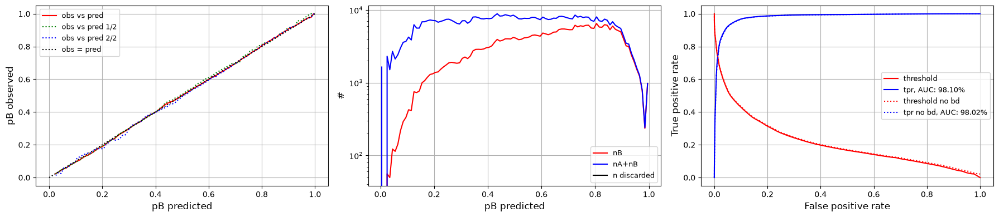

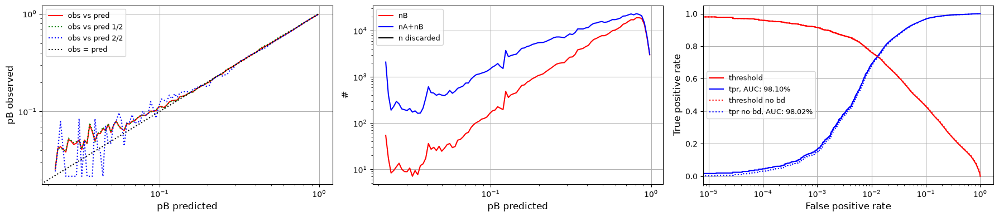

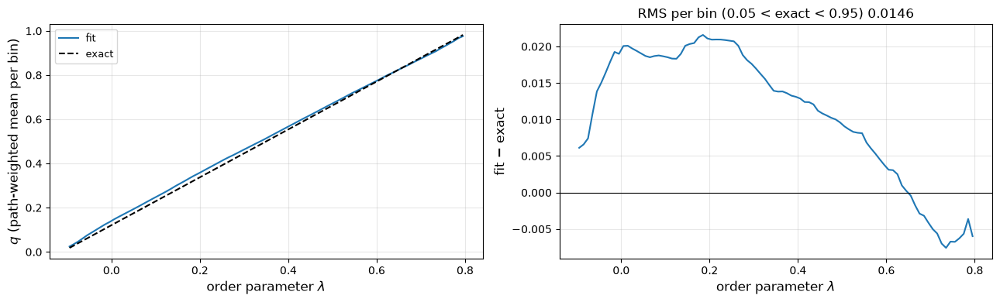

seed 0, 5000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0149
seed 0: | RMS(fit - exact) 0.0149
fwd_staple: done in 0.01 h, zqs_z 1.59, RMS(fit - exact) 0.0149

=== rev_staple: {'weights': 'staple', 'reversed': True, 'cut': True, 'max_length': None, 'long_pieces': 'truncate', 'name': 'rev_staple'} ===
Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/logging.log: [-0.1, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
State A: order <= -0.1, state B: order >= 0.8
Found 10 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/001: loaded 1638 pieces, 41405 frames, total weight 4258, cut at M = -0.1
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/002: loaded 2000 pieces, 128054 frames, total weight 4722, cut at M = 0.0
  /home/staff7/fbsskr/Notebooks/Students/eli

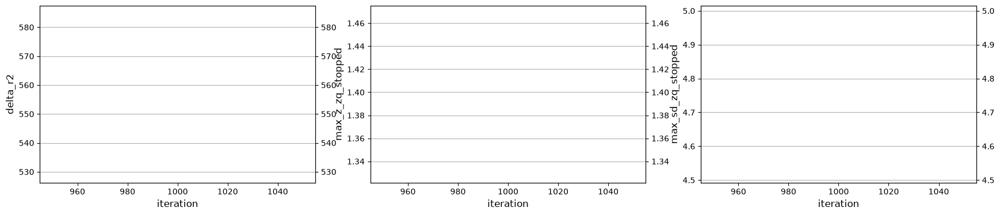

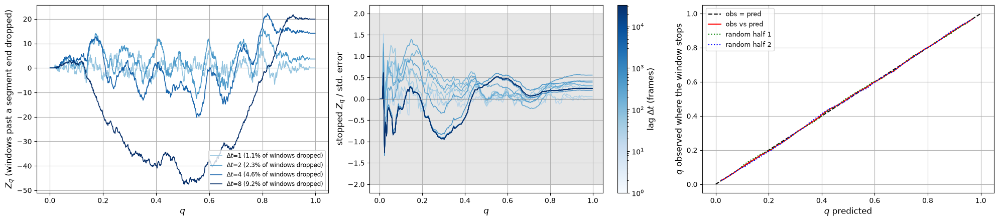

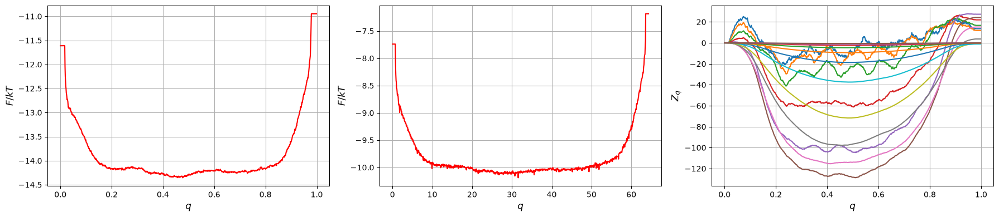

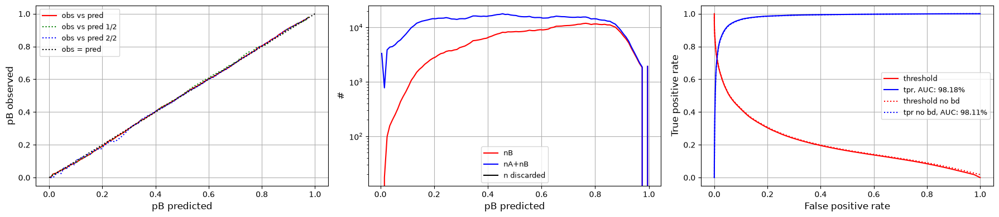

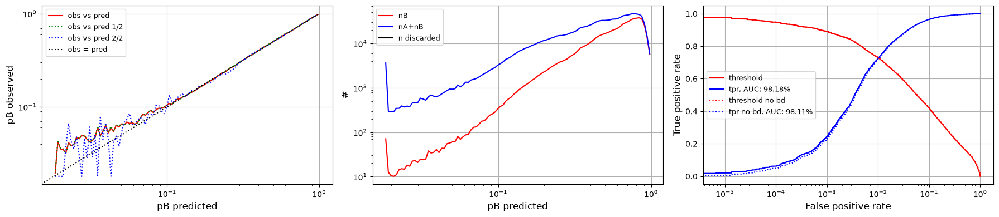

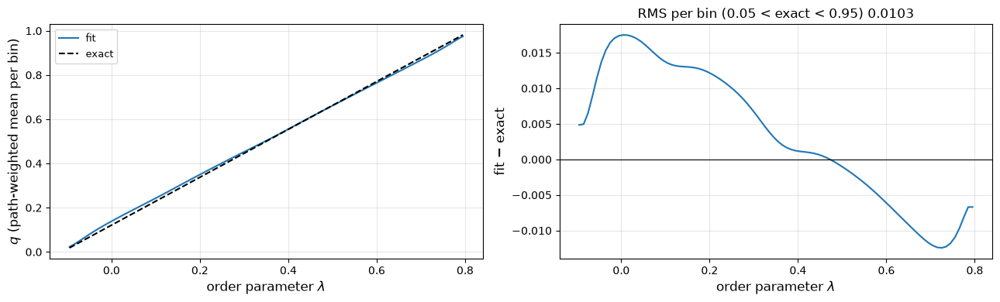

seed 0, 1000 iterations (warm-up: envelope 1000000, gamma 0.0) | RMS(fit - exact) 0.0098
#=1500, dr2=556.822, zqs_z=1.35648, sdzqs=4.7628, |dx|=0.000246828, time=2.24372
#=2000, dr2=556.869, zqs_z=1.37308, sdzqs=4.77044, |dx|=4.98766e-05, time=4.48847
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_staple/seed0/it2000 ---


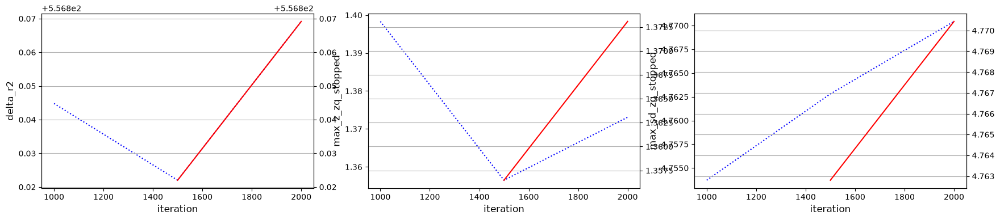

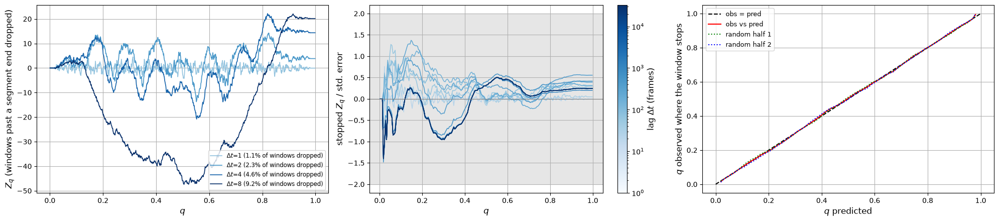

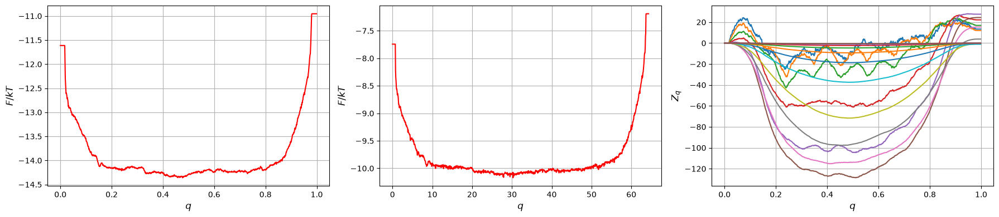

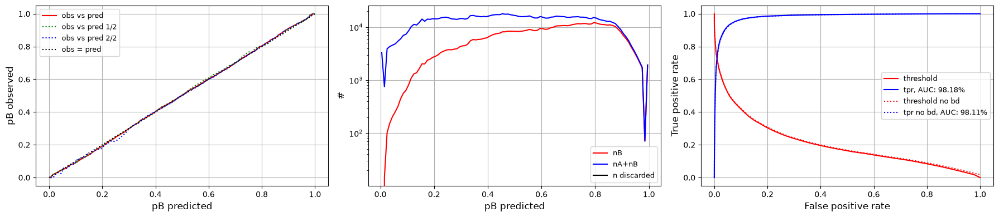

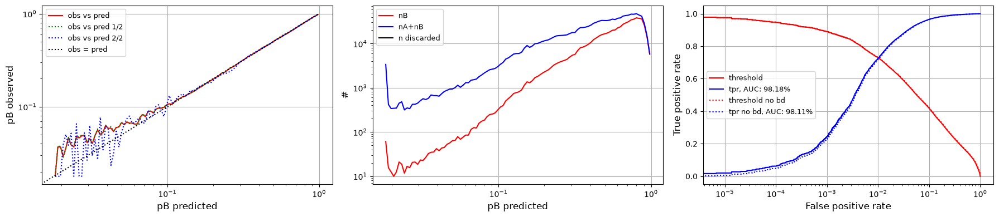

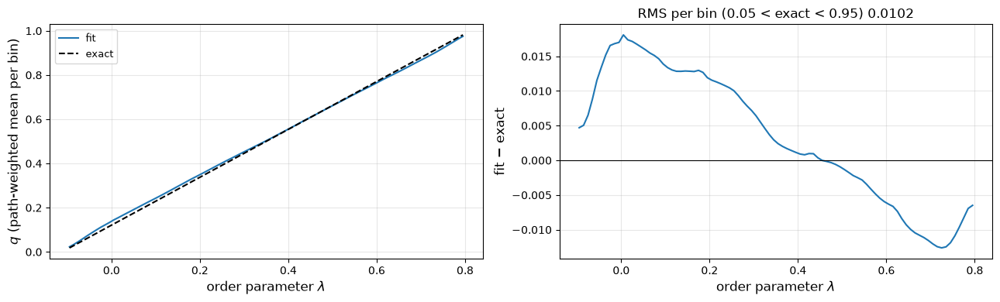

seed 0, 2000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0098
#=2500, dr2=556.859, zqs_z=1.3673, sdzqs=4.77435, |dx|=3.14055e-05, time=2.24336
#=3000, dr2=556.865, zqs_z=1.36577, sdzqs=4.77083, |dx|=2.21125e-05, time=4.48957
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_staple/seed0/it3000 ---


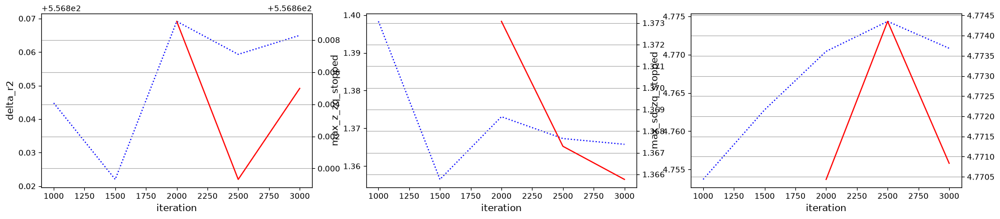

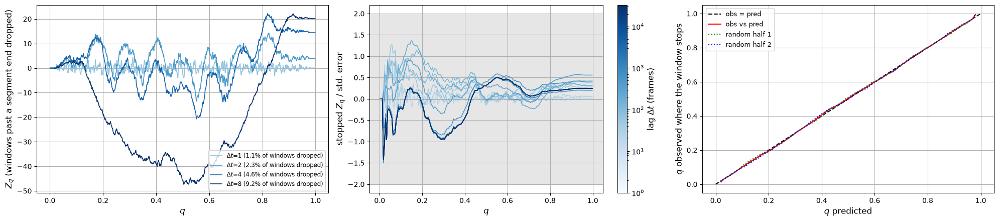

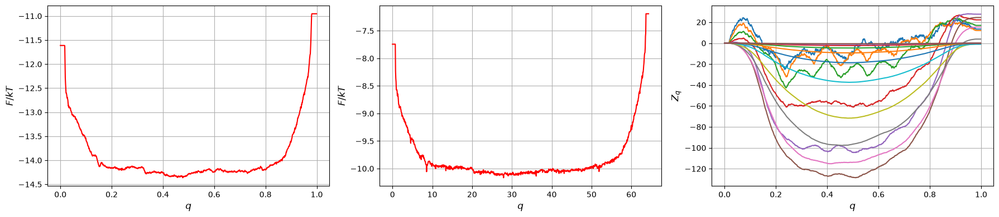

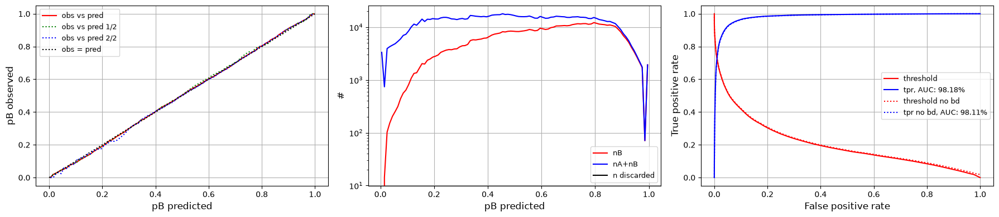

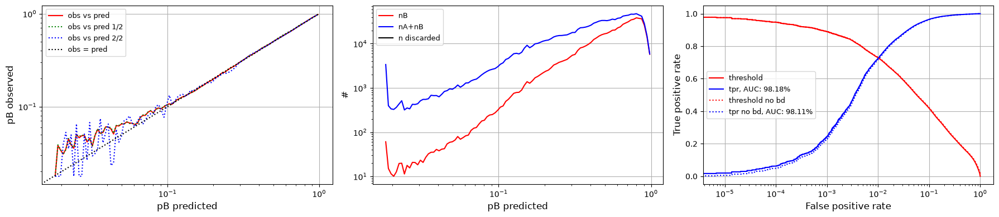

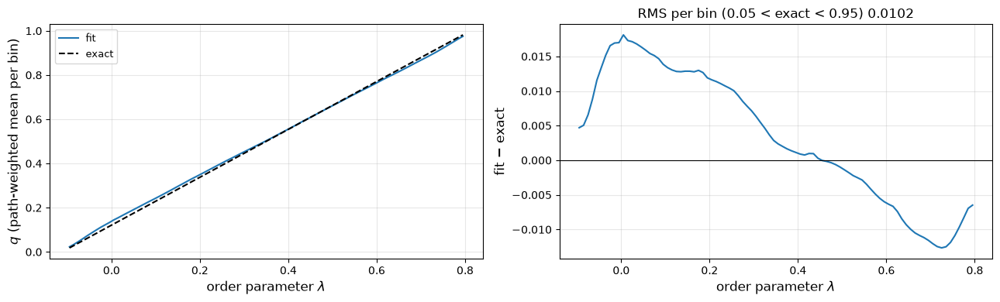

seed 0, 3000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0098
#=3500, dr2=556.86, zqs_z=1.3735, sdzqs=4.77041, |dx|=2.35187e-05, time=2.24169
#=4000, dr2=556.869, zqs_z=1.36436, sdzqs=4.75465, |dx|=5.12102e-05, time=4.49184
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_staple/seed0/it4000 ---


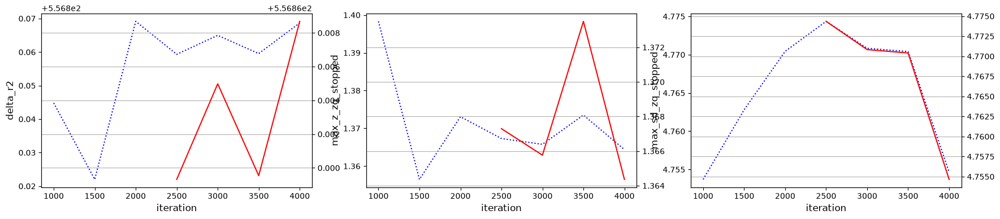

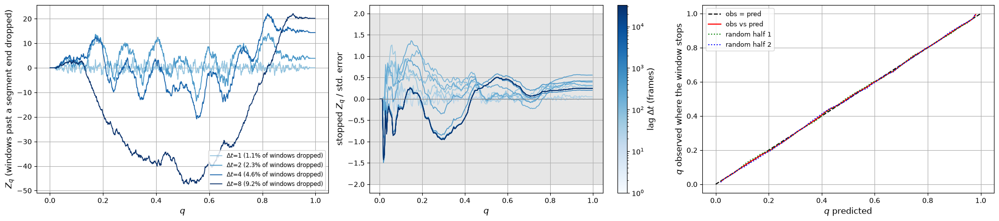

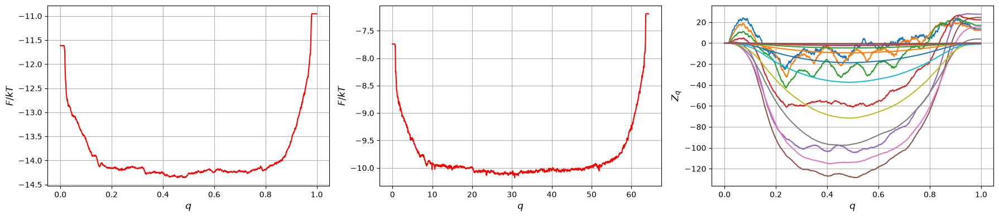

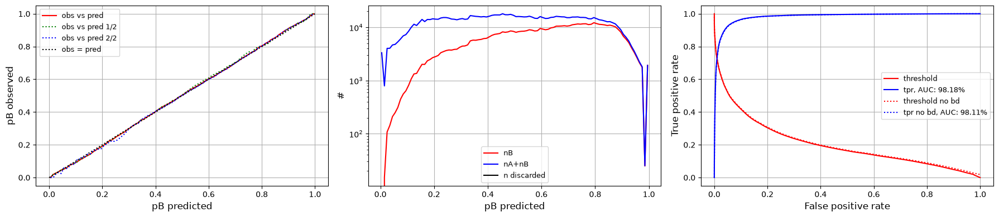

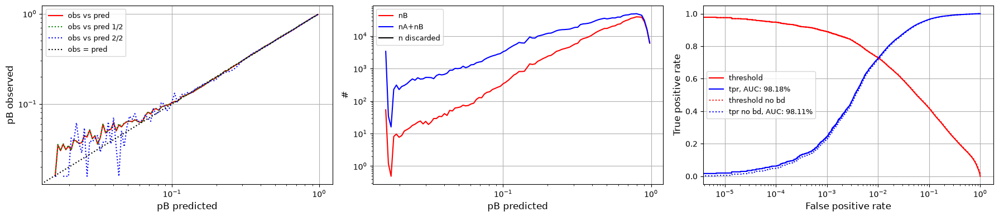

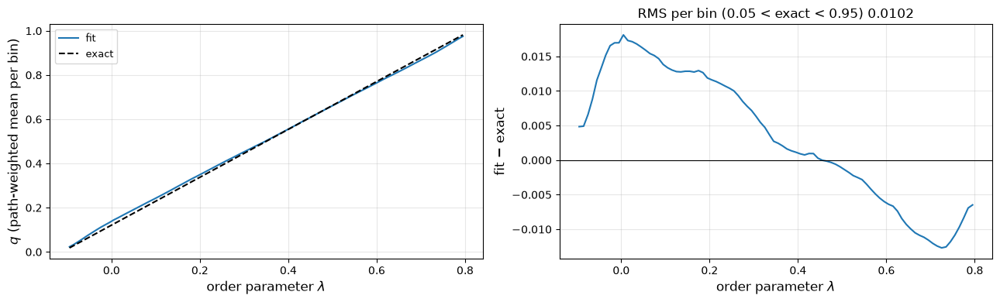

seed 0, 4000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0098
#=4500, dr2=556.873, zqs_z=1.36822, sdzqs=4.76251, |dx|=5.58858e-05, time=2.24037
#=5000, dr2=556.86, zqs_z=1.36475, sdzqs=4.76803, |dx|=2.76784e-05, time=4.49502
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_staple/seed0/it5000 ---


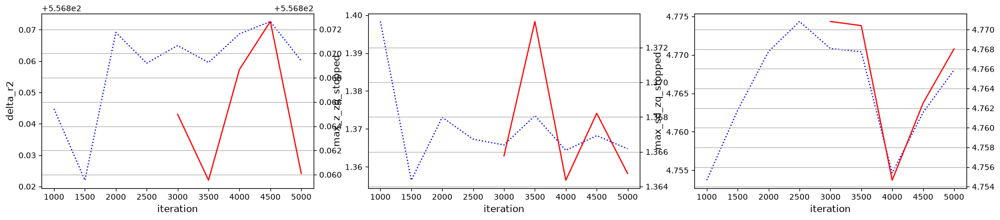

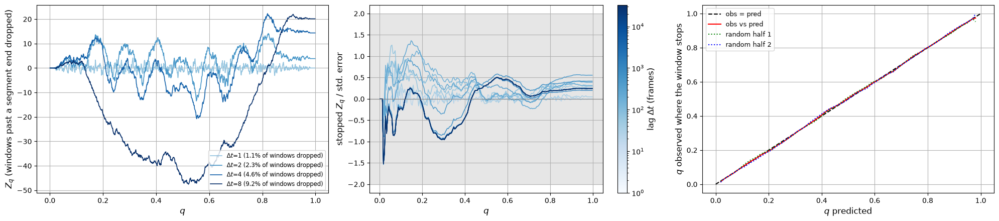

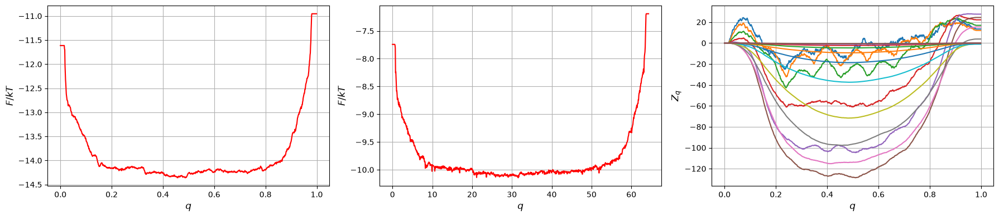

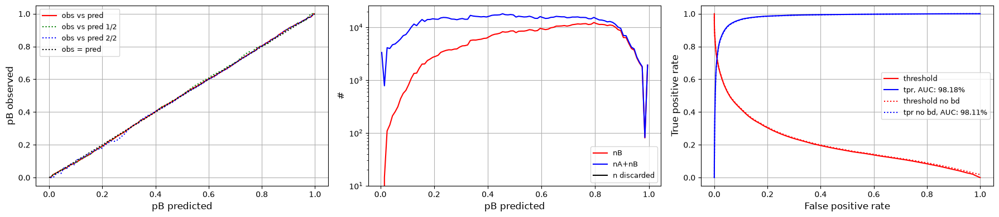

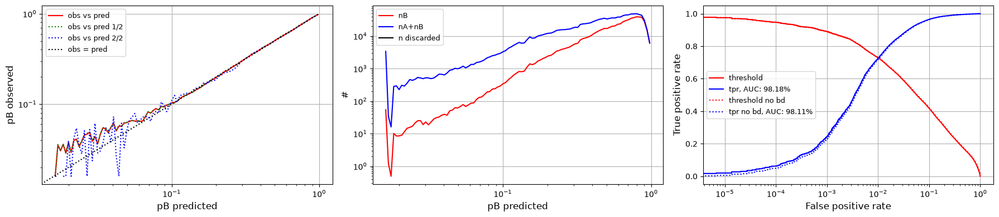

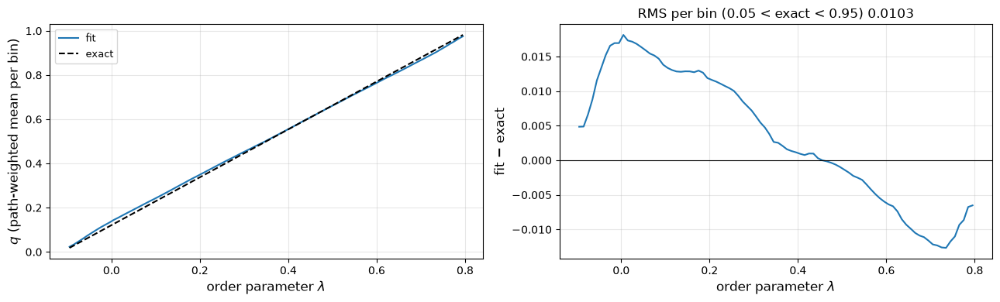

seed 0, 5000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0098
seed 0: | RMS(fit - exact) 0.0098
rev_staple: done in 0.01 h, zqs_z 1.36, RMS(fit - exact) 0.0098

=== fwd_none: {'weights': 'none', 'reversed': False, 'cut': True, 'max_length': None, 'long_pieces': 'truncate', 'name': 'fwd_none'} ===
Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/logging.log: [-0.1, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
State A: order <= -0.1, state B: order >= 0.8
Found 10 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/001: loaded 822 paths, 20145 frames, total weight 822, cut at M = -0.1
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/002: loaded 1000 paths, 65002 frames, total weight 1000, cut at M = 0.0
  /home/staff7/fbsskr/Notebooks/Students/elias/data/si

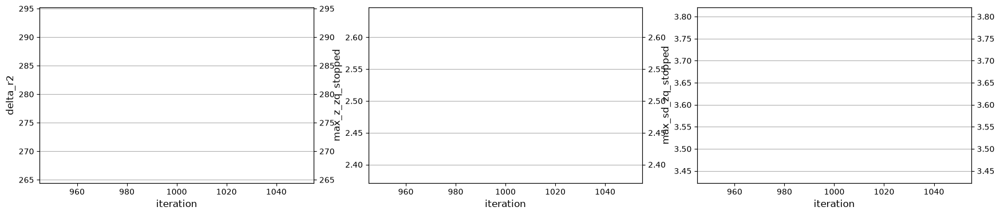

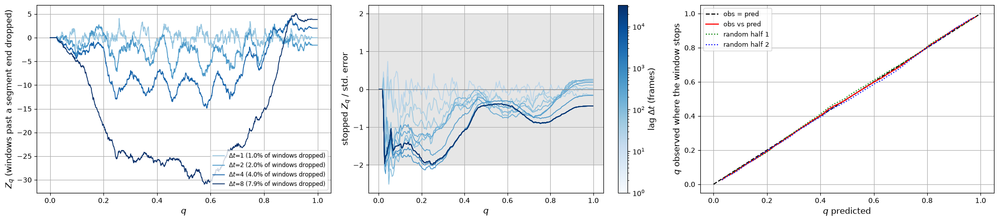

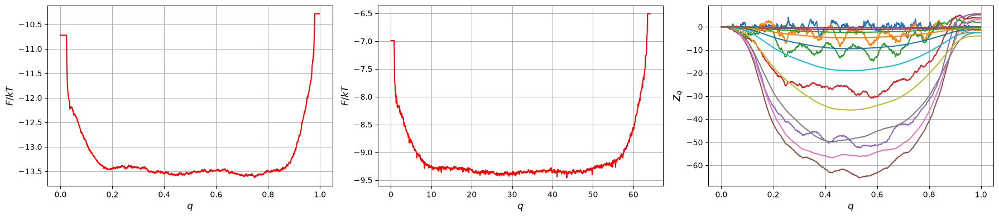

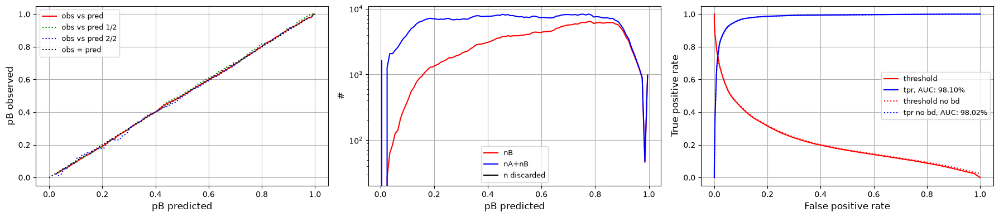

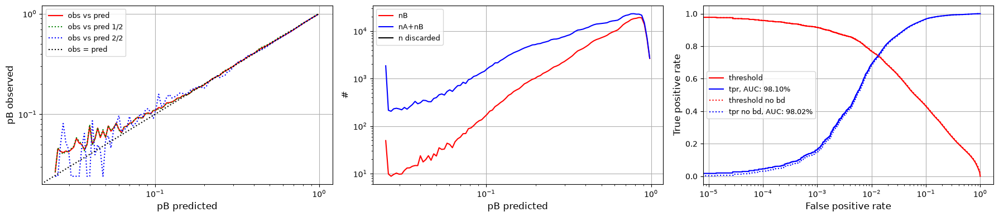

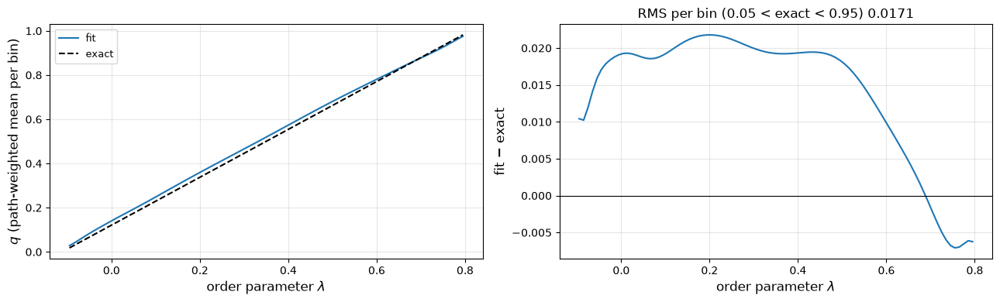

seed 0, 1000 iterations (warm-up: envelope 1000000, gamma 0.0) | RMS(fit - exact) 0.0176
#=1500, dr2=279.854, zqs_z=2.71471, sdzqs=3.60863, |dx|=0.000207673, time=1.27001
#=2000, dr2=279.858, zqs_z=2.63773, sdzqs=3.61137, |dx|=7.79182e-05, time=2.53228
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/fwd_none/seed0/it2000 ---


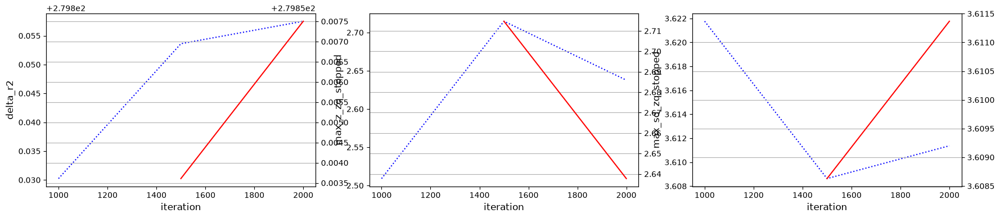

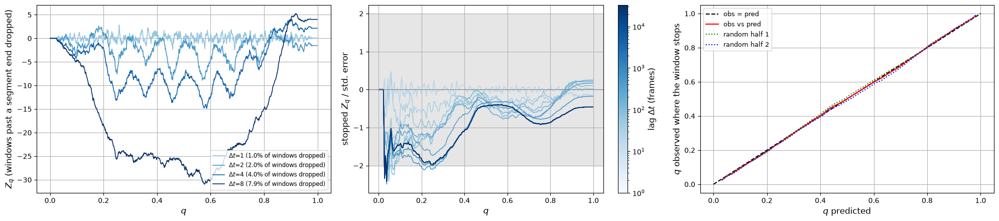

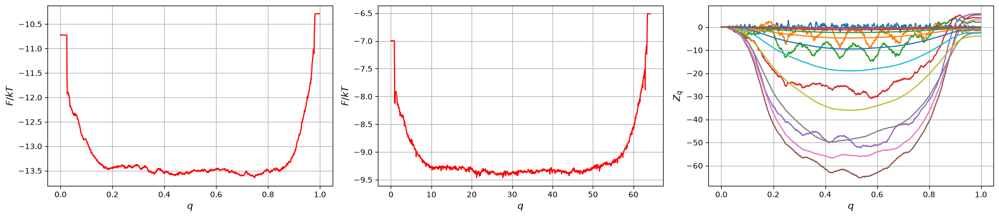

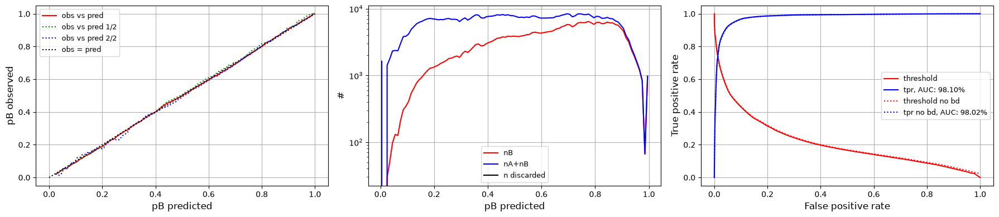

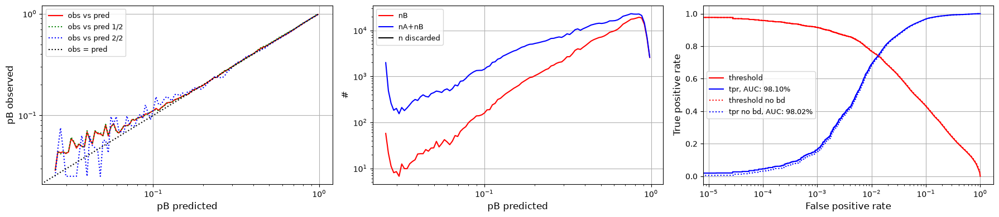

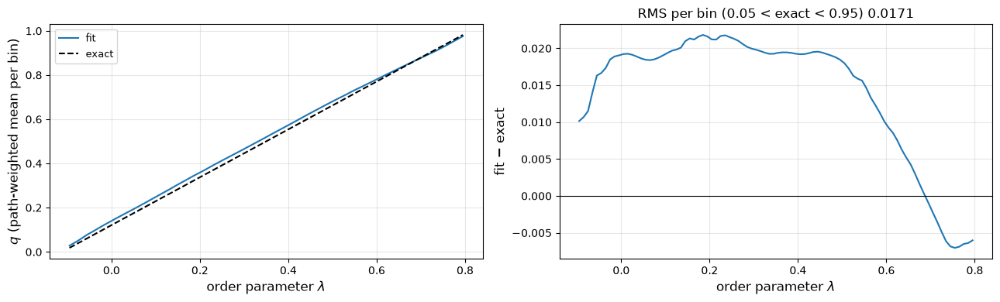

seed 0, 2000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0175
#=2500, dr2=279.841, zqs_z=2.62213, sdzqs=3.61066, |dx|=5.91642e-05, time=1.2663
#=3000, dr2=279.843, zqs_z=2.62926, sdzqs=3.61496, |dx|=4.5815e-05, time=2.53425
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/fwd_none/seed0/it3000 ---


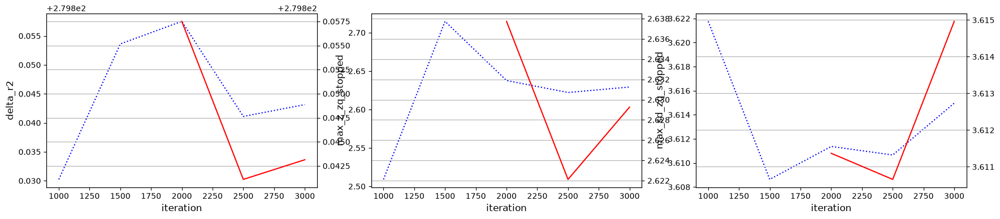

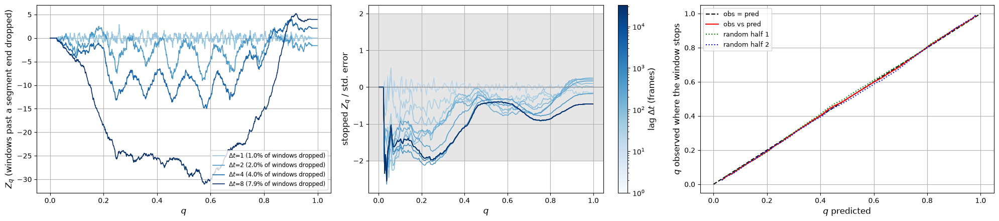

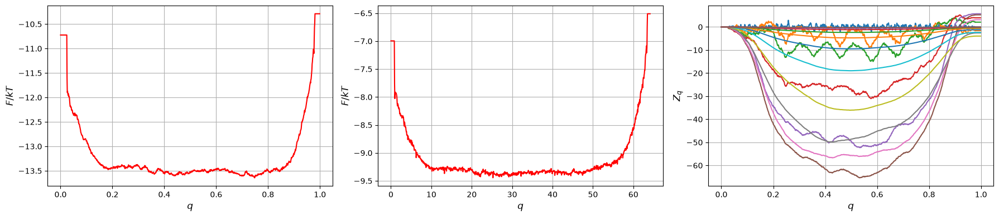

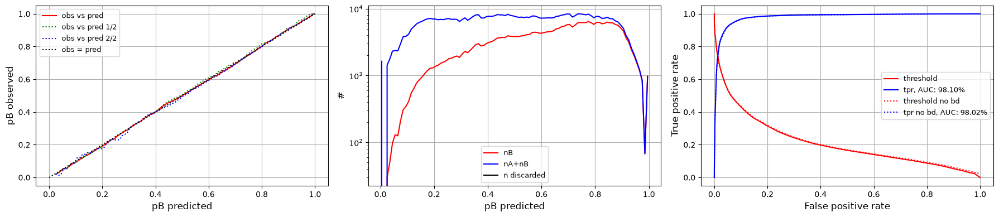

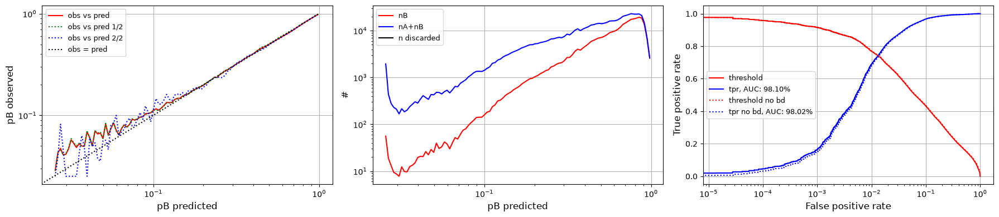

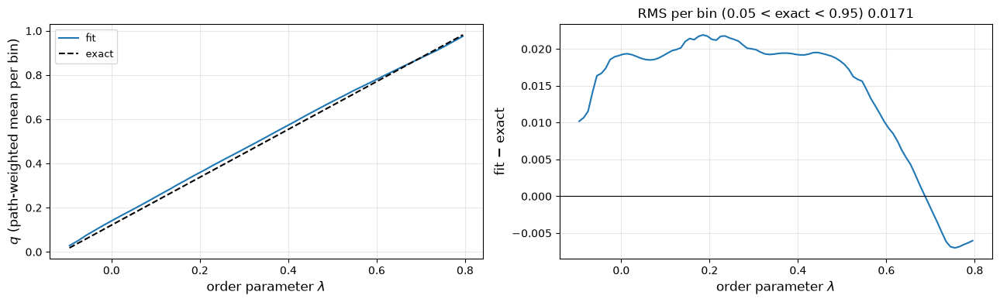

seed 0, 3000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0176
#=3500, dr2=279.845, zqs_z=2.68063, sdzqs=3.61158, |dx|=2.68152e-05, time=1.26124
#=4000, dr2=279.846, zqs_z=2.63261, sdzqs=3.61217, |dx|=3.90671e-05, time=2.52925
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/fwd_none/seed0/it4000 ---


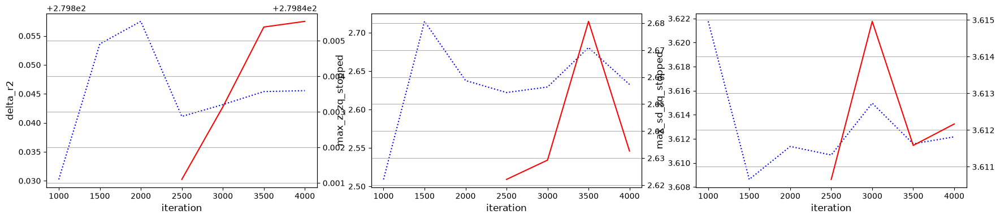

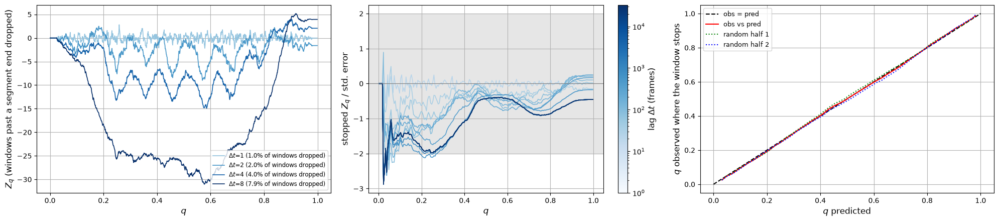

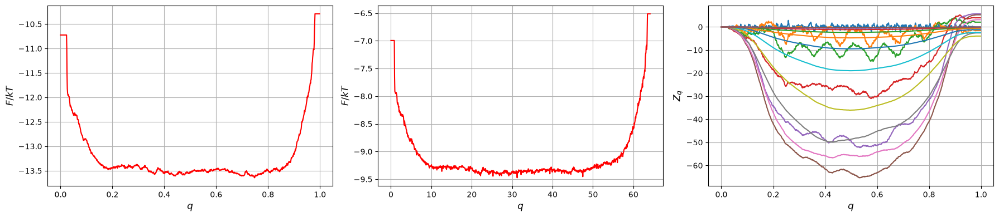

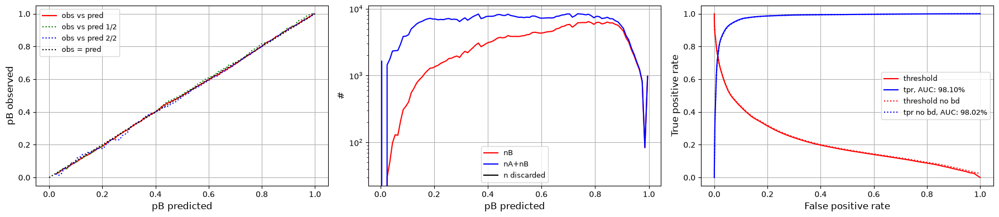

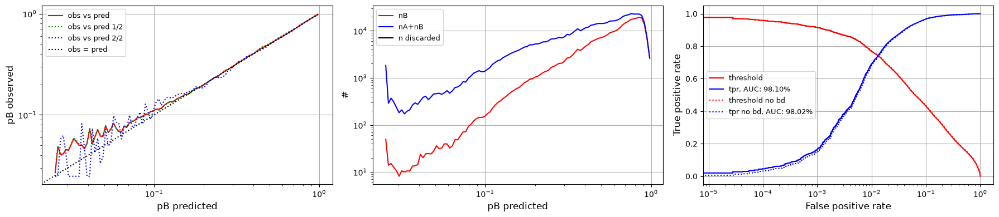

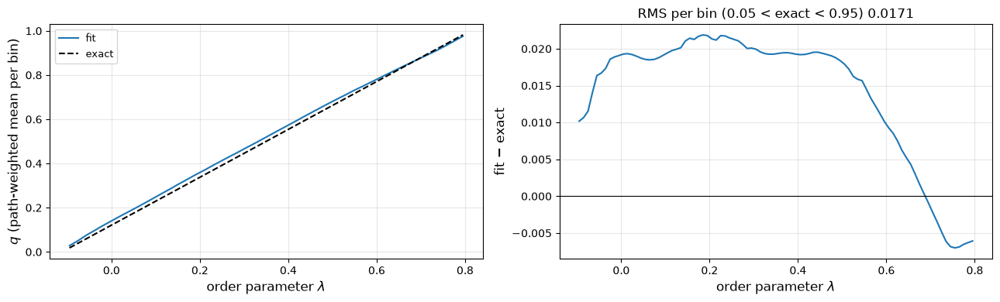

seed 0, 4000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0176
#=4500, dr2=279.851, zqs_z=2.61348, sdzqs=3.60667, |dx|=3.09458e-05, time=1.26563
#=5000, dr2=279.848, zqs_z=2.61742, sdzqs=3.60818, |dx|=2.504e-05, time=2.53834
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/fwd_none/seed0/it5000 ---


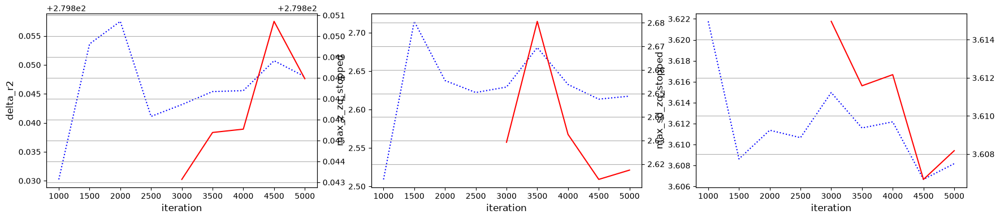

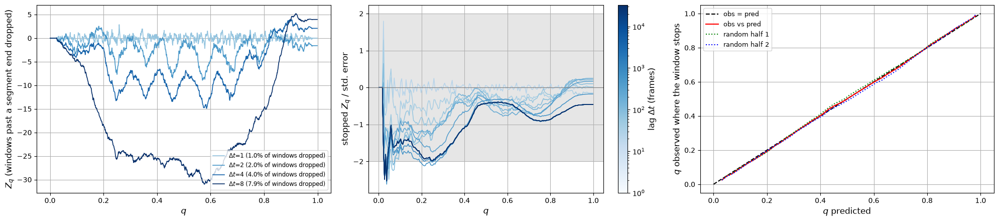

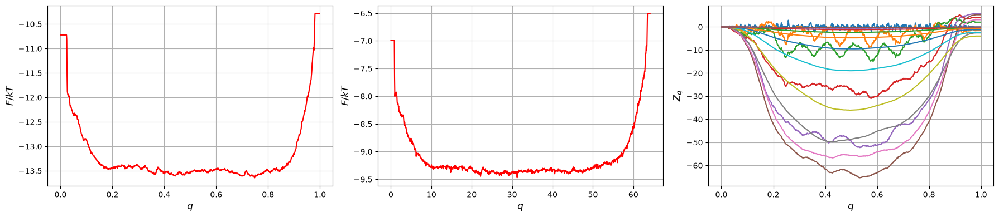

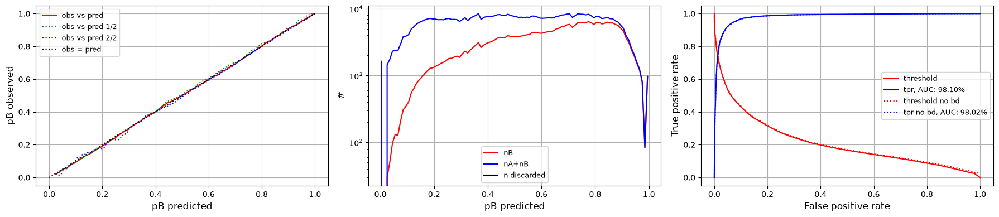

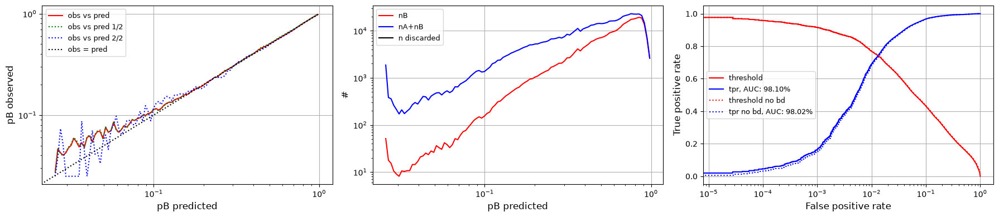

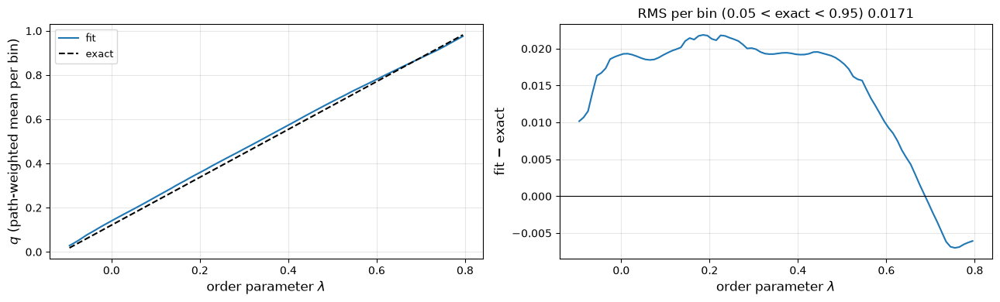

seed 0, 5000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0176
seed 0: | RMS(fit - exact) 0.0176
fwd_none: done in 0.01 h, zqs_z 2.62, RMS(fit - exact) 0.0176

=== rev_none: {'weights': 'none', 'reversed': True, 'cut': True, 'max_length': None, 'long_pieces': 'truncate', 'name': 'rev_none'} ===
Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/logging.log: [-0.1, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
State A: order <= -0.1, state B: order >= 0.8
Found 10 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/001: loaded 1638 pieces, 41405 frames, total weight 1638, cut at M = -0.1
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/002: loaded 2000 pieces, 128054 frames, total weight 2000, cut at M = 0.0
  /home/staff7/fbsskr/Notebooks/Students/elias/data/

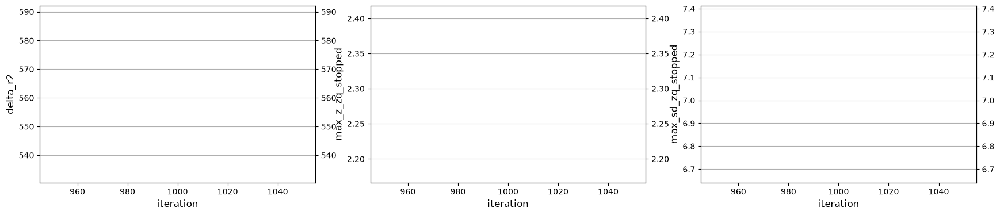

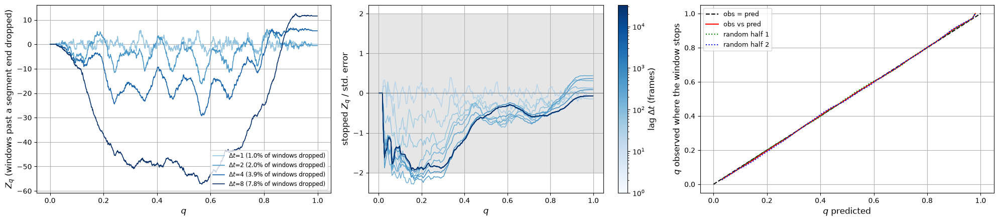

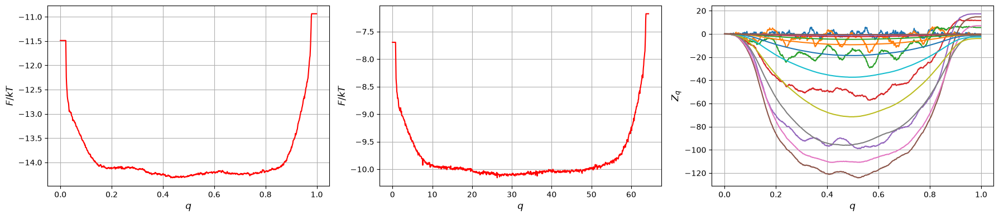

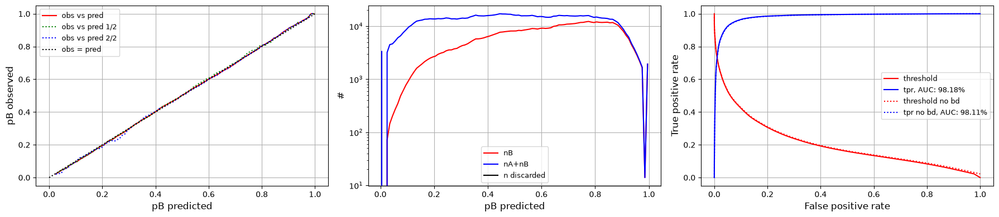

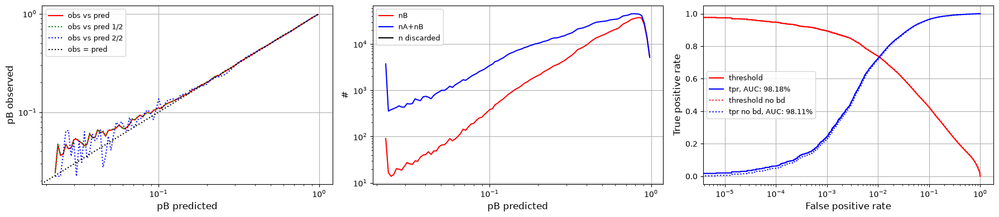

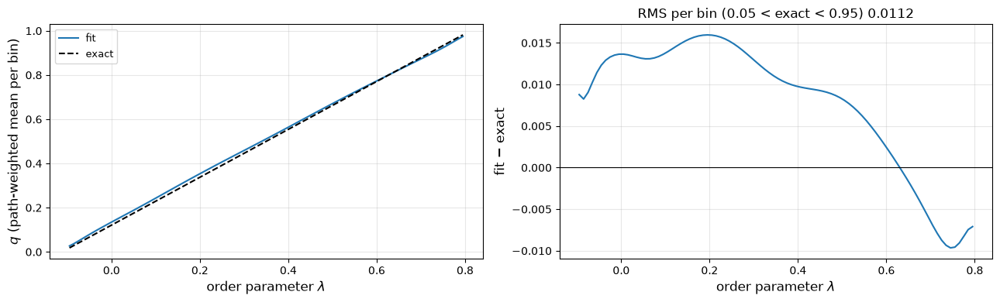

seed 0, 1000 iterations (warm-up: envelope 1000000, gamma 0.0) | RMS(fit - exact) 0.0113
#=1500, dr2=561.266, zqs_z=2.27956, sdzqs=6.98636, |dx|=0.000134725, time=2.24617
#=2000, dr2=561.282, zqs_z=2.2808, sdzqs=6.97418, |dx|=4.76695e-05, time=4.49397
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_none/seed0/it2000 ---


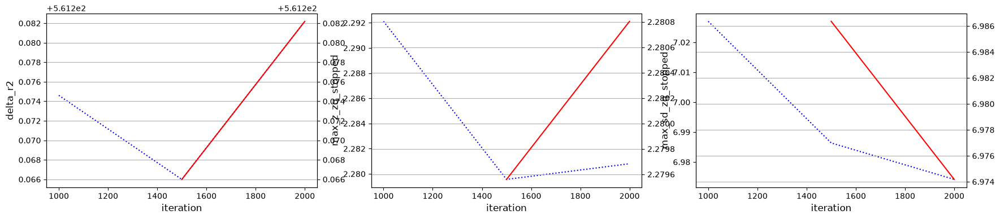

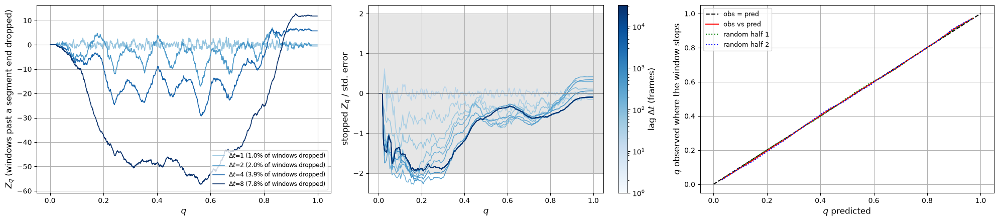

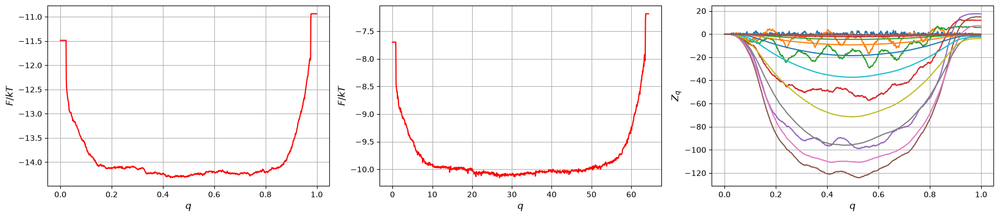

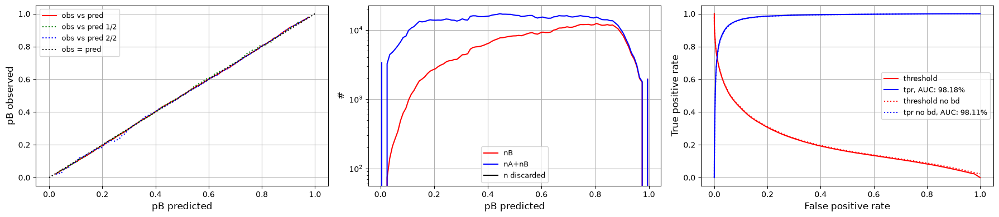

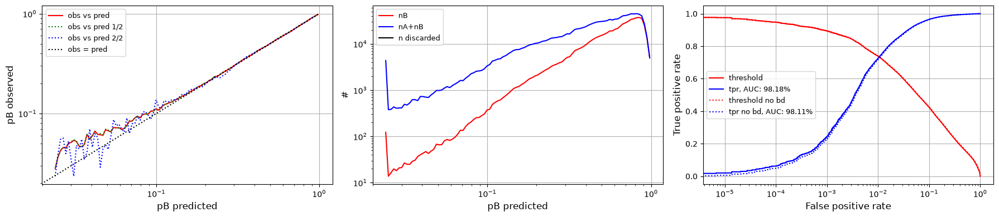

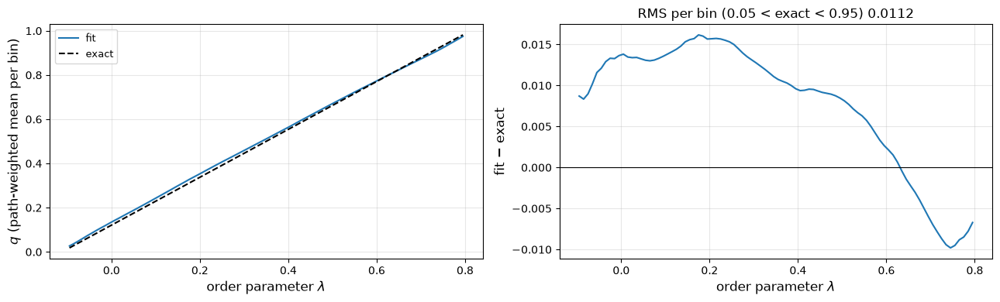

seed 0, 2000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0113
#=2500, dr2=561.264, zqs_z=2.27927, sdzqs=6.96416, |dx|=6.13325e-05, time=2.24688
#=3000, dr2=561.269, zqs_z=2.27202, sdzqs=6.96517, |dx|=4.27501e-05, time=4.49995
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_none/seed0/it3000 ---


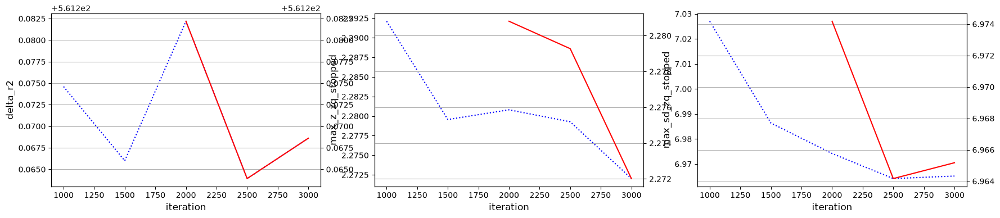

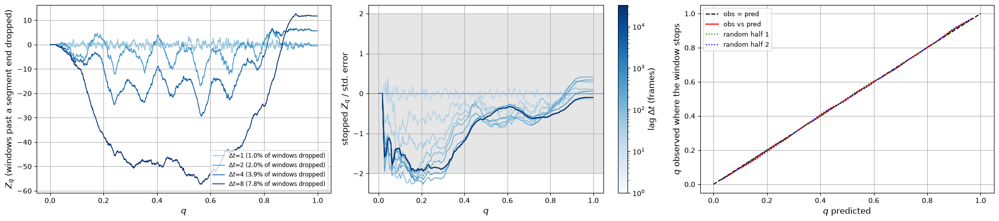

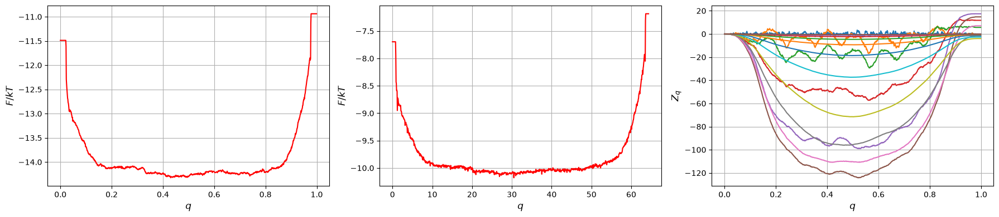

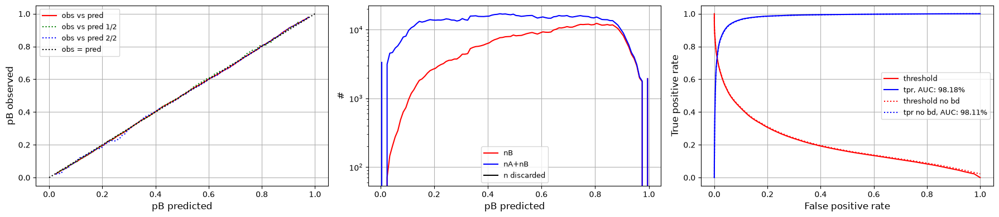

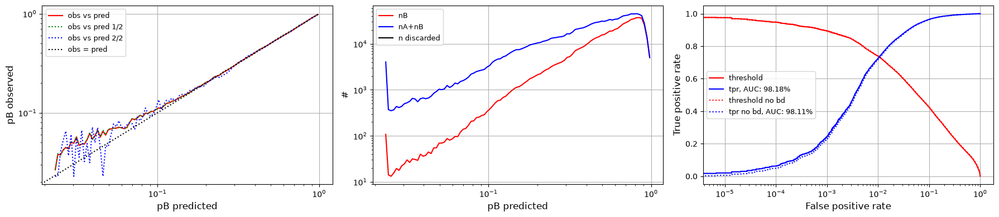

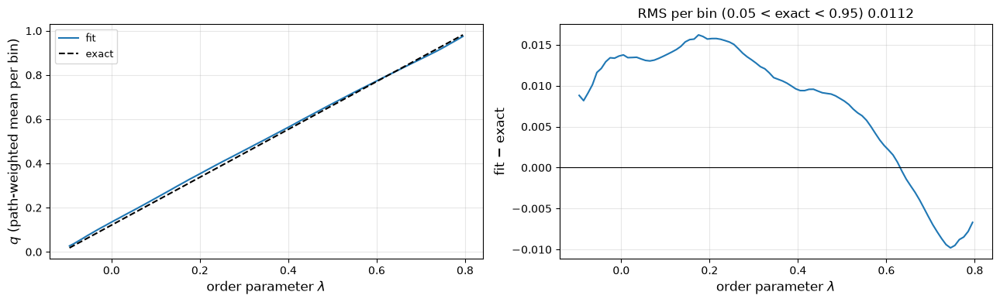

seed 0, 3000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0113
#=3500, dr2=561.264, zqs_z=2.27525, sdzqs=6.96848, |dx|=2.14203e-05, time=2.18617
#=4000, dr2=561.264, zqs_z=2.27541, sdzqs=6.96645, |dx|=1.91575e-05, time=4.37386
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_none/seed0/it4000 ---


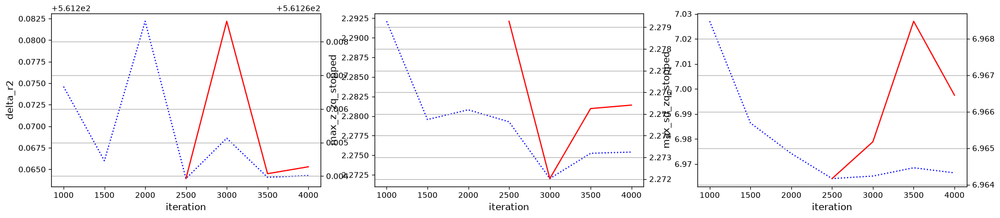

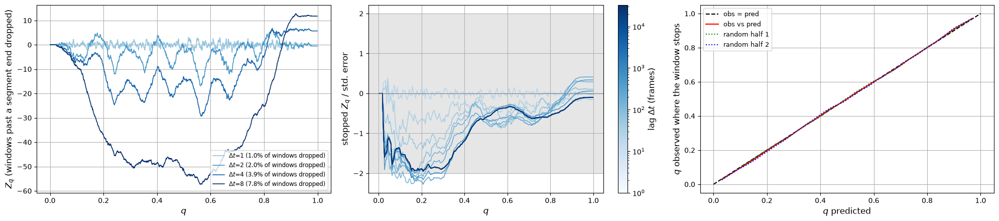

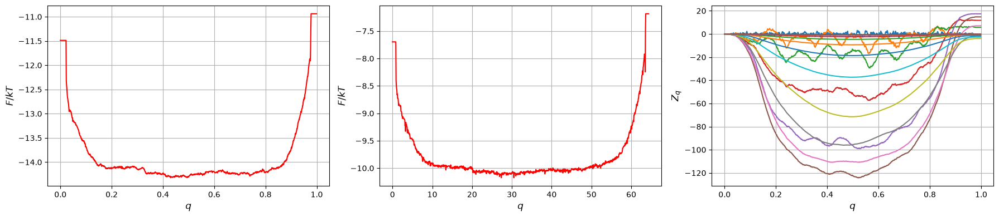

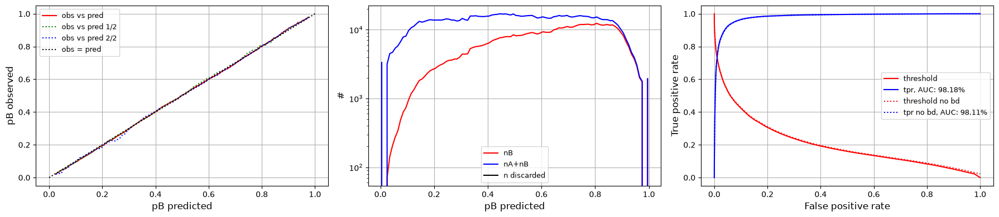

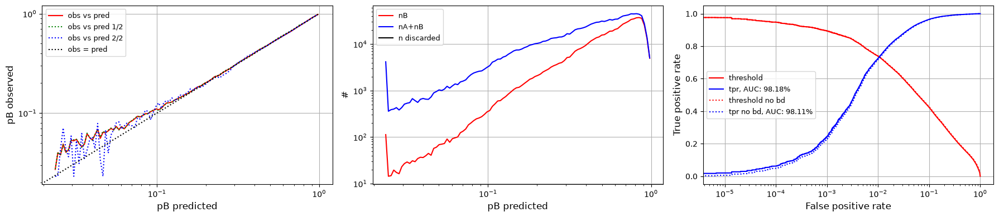

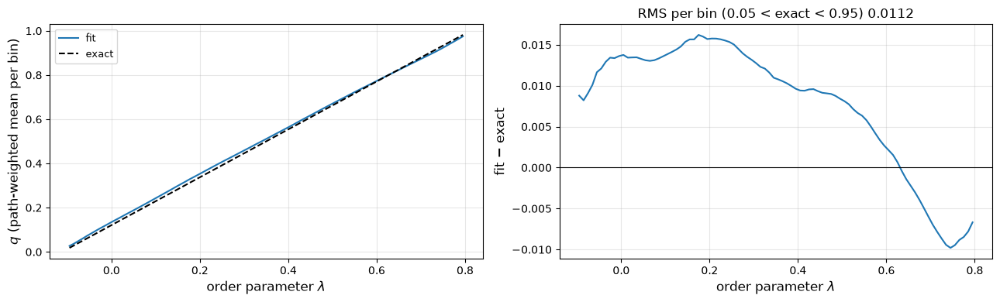

seed 0, 4000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0113
#=4500, dr2=561.261, zqs_z=2.27737, sdzqs=6.9734, |dx|=2.473e-05, time=2.18417
#=5000, dr2=561.273, zqs_z=2.27352, sdzqs=6.95182, |dx|=3.87265e-05, time=4.37864
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_none/seed0/it5000 ---


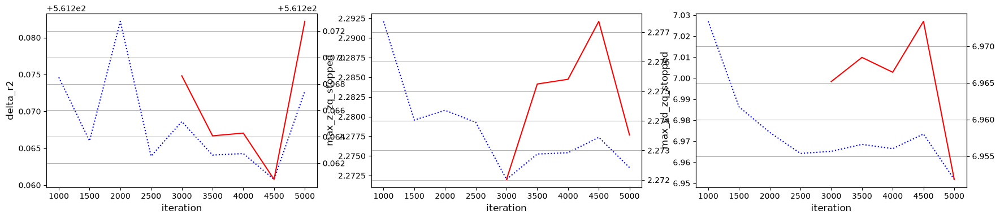

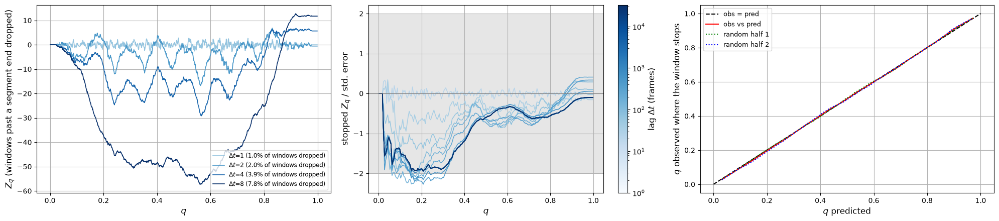

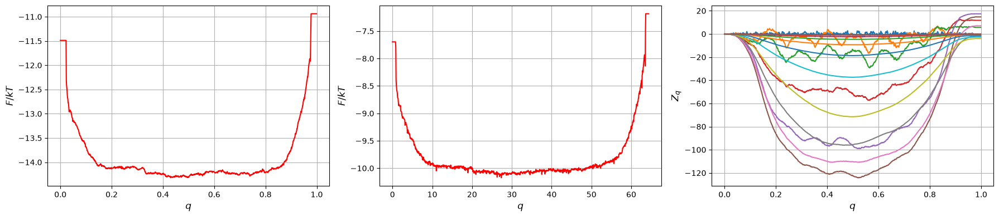

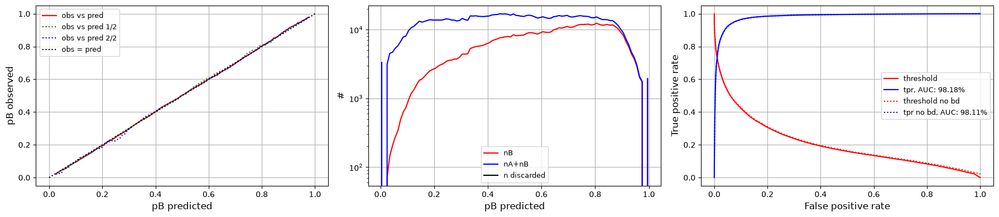

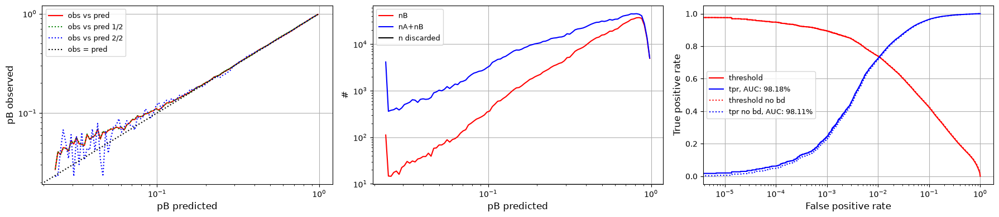

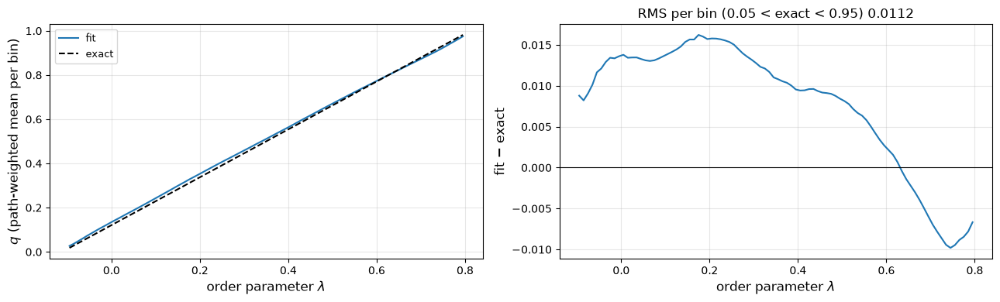

seed 0, 5000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0113
seed 0: | RMS(fit - exact) 0.0113
rev_none: done in 0.01 h, zqs_z 2.27, RMS(fit - exact) 0.0113

=== nocut_rej: {'weights': 'rejections', 'reversed': False, 'cut': False, 'max_length': None, 'long_pieces': 'truncate', 'name': 'nocut_rej'} ===
Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/logging.log: [-0.1, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
State A: order <= -0.1, state B: order >= 0.8
Found 10 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/001: loaded 1000 paths, 37595 frames, total weight 2483
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/002: loaded 1000 paths, 103905 frames, total weight 1945
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br1

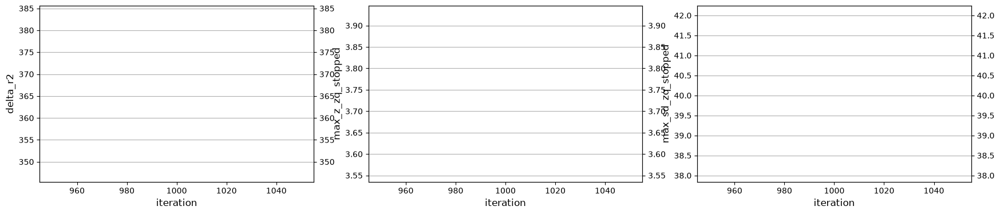

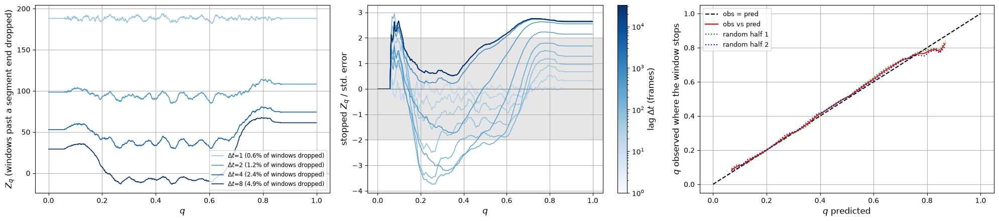

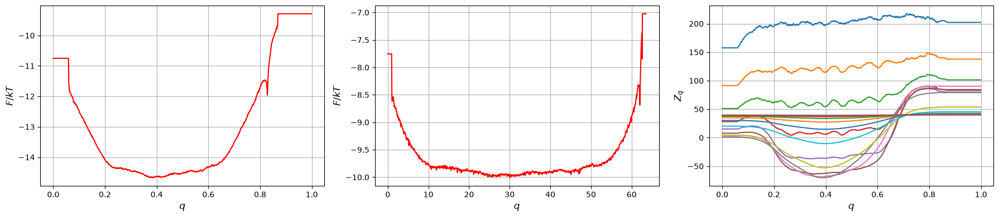

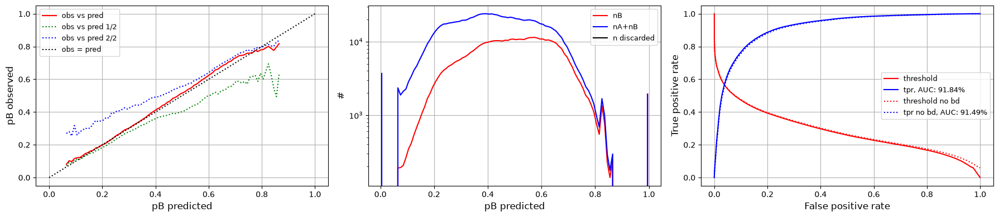

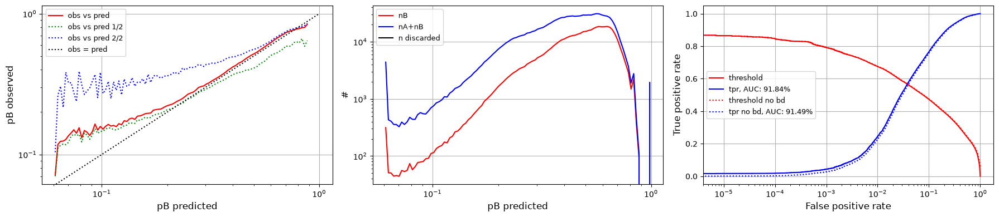

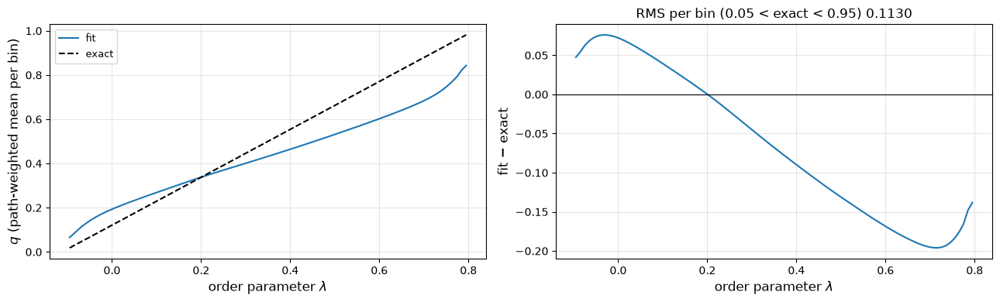

seed 0, 1000 iterations (warm-up: envelope 1000000, gamma 0.0) | RMS(fit - exact) 0.1062
#=1500, dr2=365.559, zqs_z=3.72722, sdzqs=39.9595, |dx|=0.000285204, time=1.91194
#=2000, dr2=365.565, zqs_z=3.72556, sdzqs=39.957, |dx|=4.2115e-05, time=3.82672
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/nocut_rej/seed0/it2000 ---


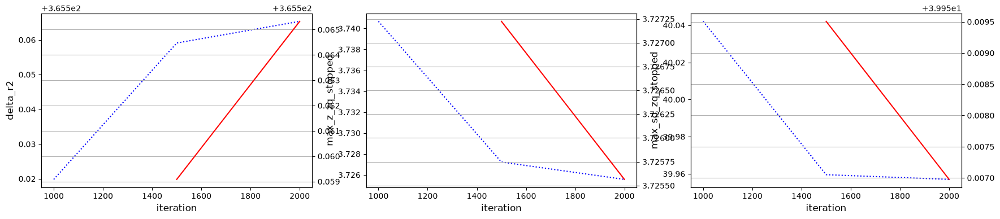

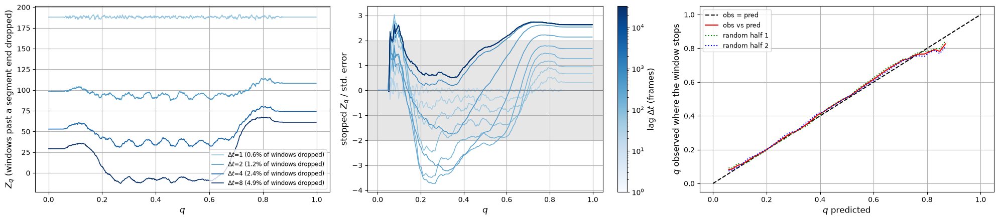

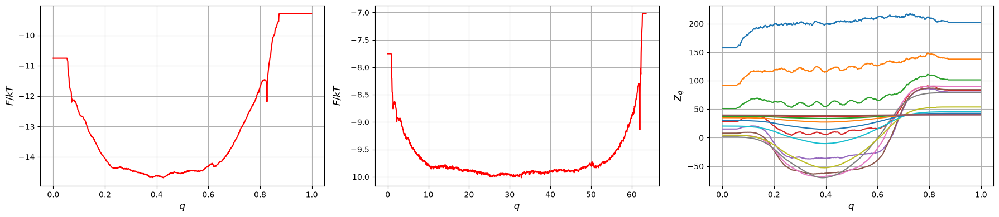

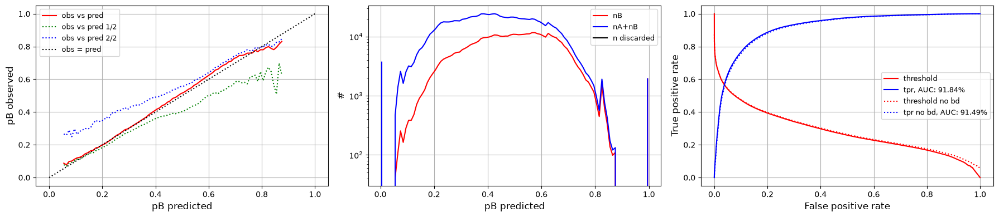

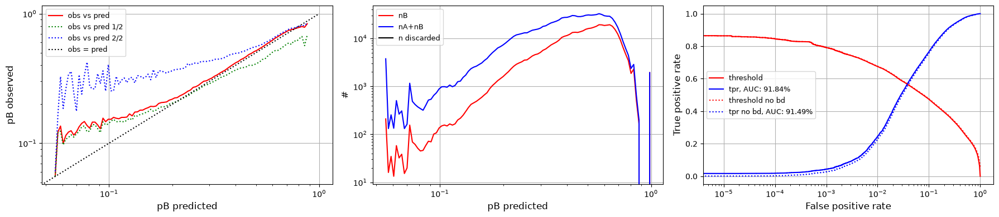

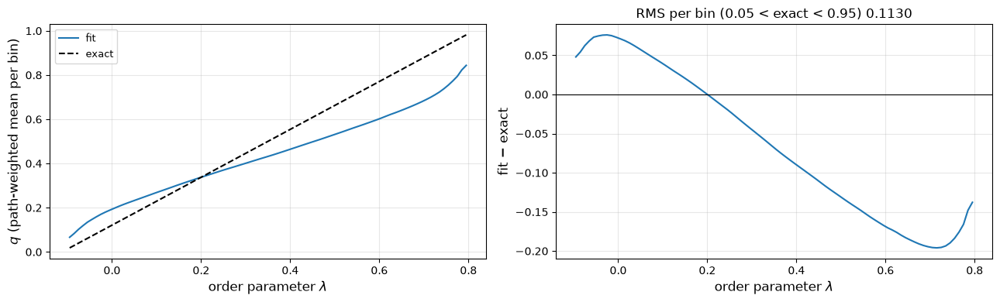

seed 0, 2000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.1062
#=2500, dr2=365.566, zqs_z=3.74015, sdzqs=39.98, |dx|=4.72288e-05, time=1.92453
#=3000, dr2=365.574, zqs_z=3.72868, sdzqs=39.9719, |dx|=3.83887e-05, time=3.84696
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/nocut_rej/seed0/it3000 ---


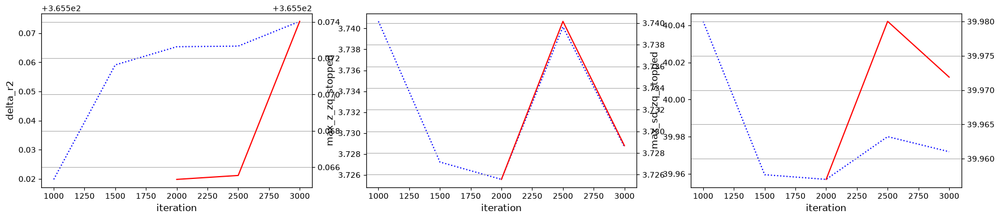

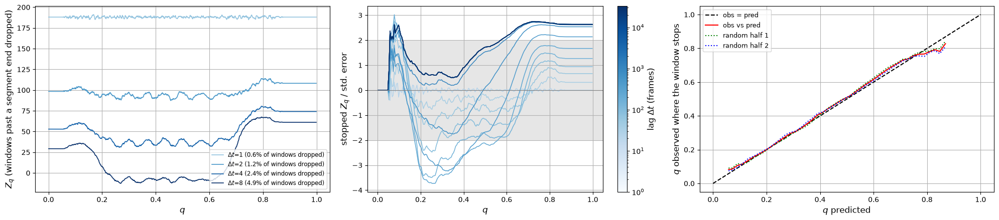

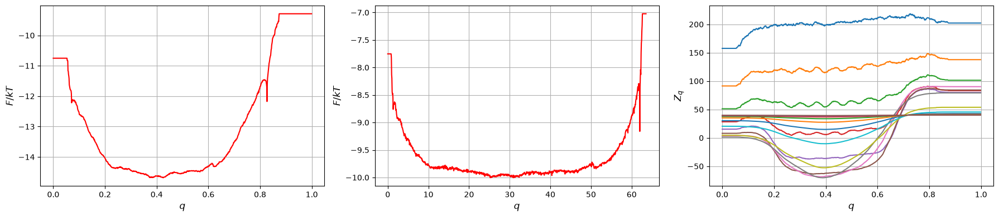

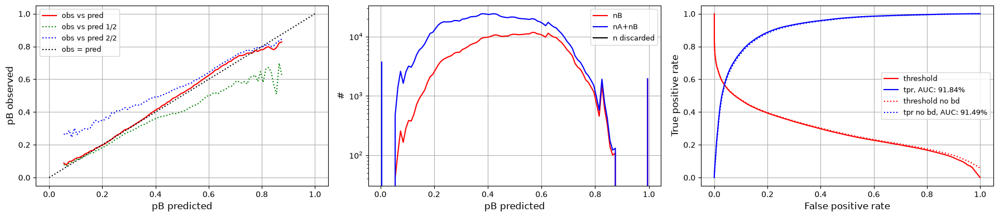

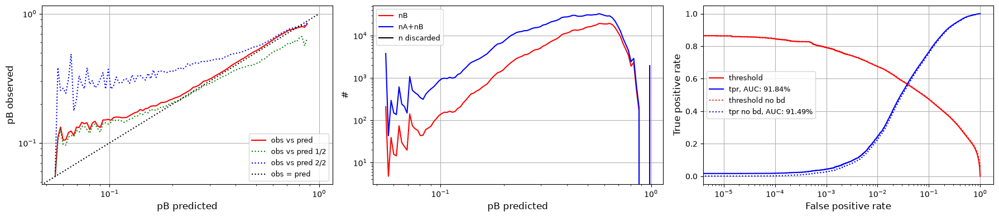

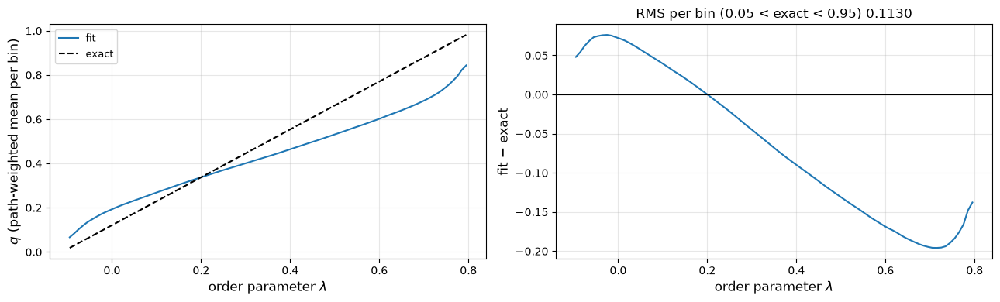

seed 0, 3000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.1062
#=3500, dr2=365.578, zqs_z=3.72854, sdzqs=39.9612, |dx|=8.88618e-05, time=1.91595
#=4000, dr2=365.579, zqs_z=3.72958, sdzqs=39.9635, |dx|=2.28181e-05, time=3.83205
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/nocut_rej/seed0/it4000 ---


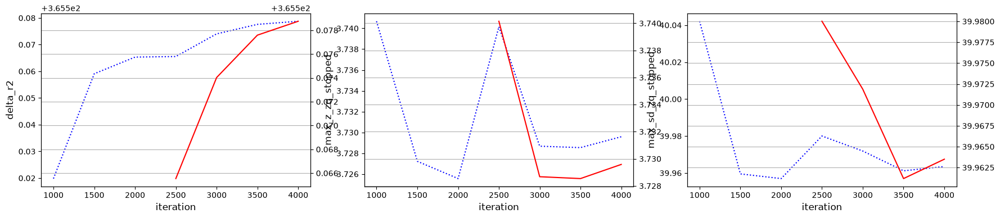

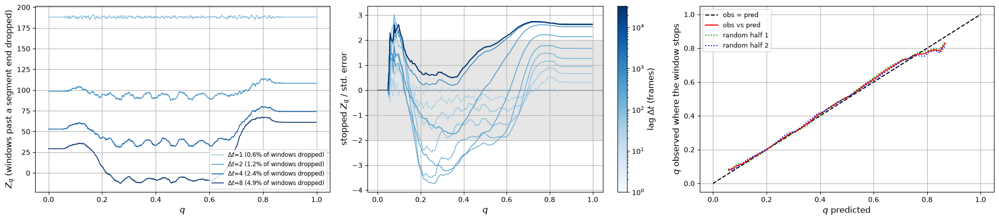

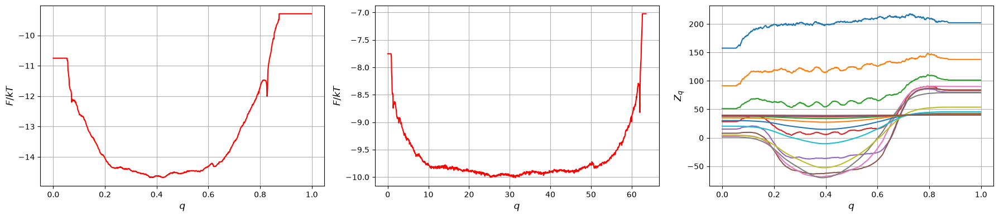

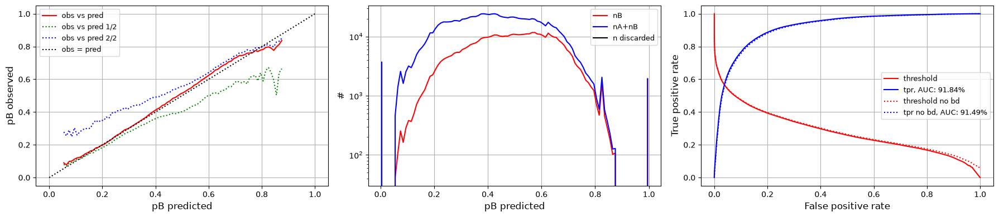

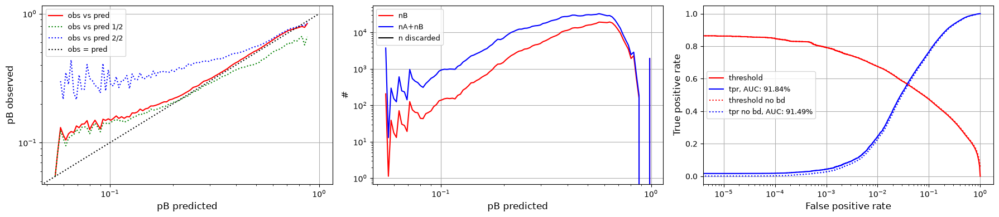

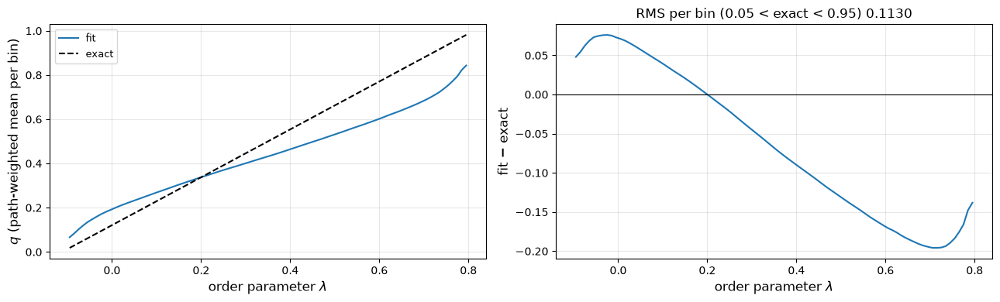

seed 0, 4000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.1062
#=4500, dr2=365.576, zqs_z=3.72909, sdzqs=39.9673, |dx|=2.71015e-05, time=1.89743
#=5000, dr2=365.578, zqs_z=3.72918, sdzqs=39.9628, |dx|=1.81428e-05, time=3.80629
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/nocut_rej/seed0/it5000 ---


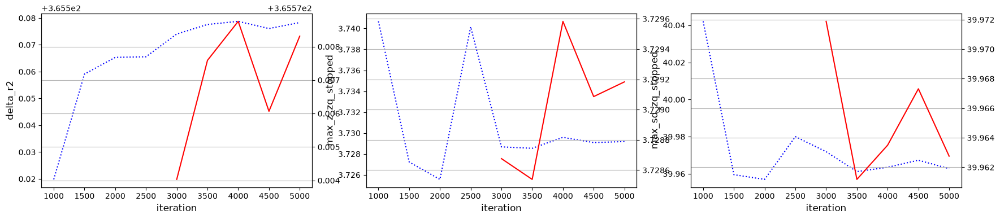

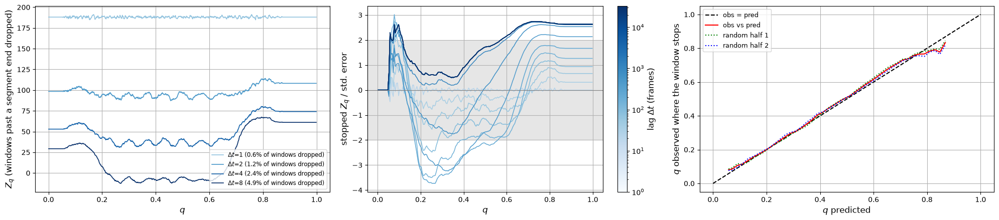

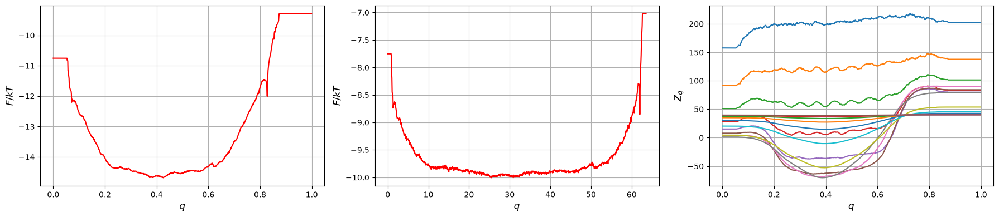

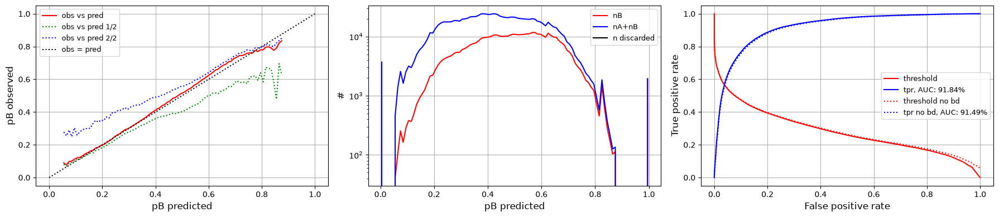

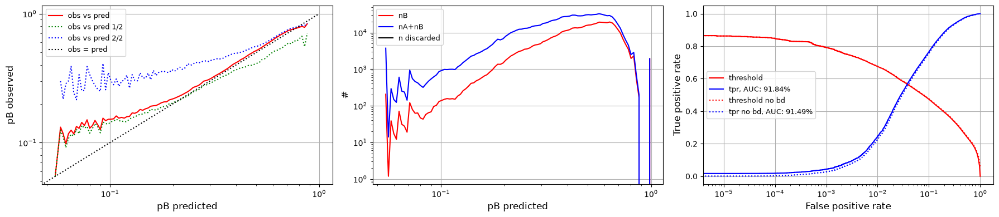

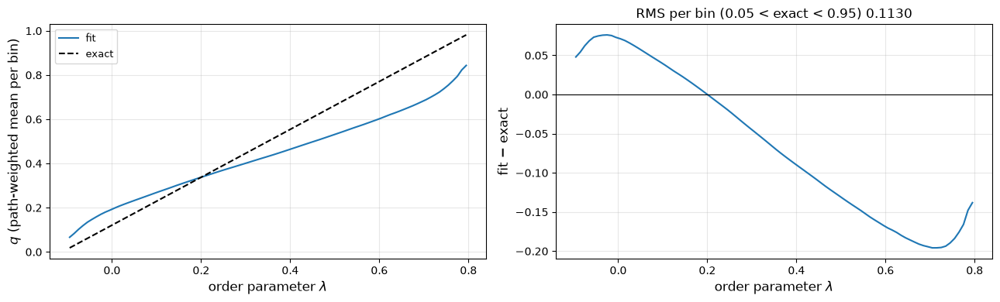

seed 0, 5000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.1062
seed 0: | RMS(fit - exact) 0.1062
nocut_rej: done in 0.01 h, zqs_z 3.73, RMS(fit - exact) 0.1062

=== rev_rej_trunc200: {'weights': 'rejections', 'reversed': True, 'cut': True, 'max_length': 200, 'long_pieces': 'truncate', 'name': 'rev_rej_trunc200'} ===
Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/logging.log: [-0.1, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
State A: order <= -0.1, state B: order >= 0.8
Found 10 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/001: loaded 1638 pieces, 40083 frames, total weight 4258, cut at M = -0.1 (26 pieces longer than 200 frames truncated)
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/002: loaded 2000 pieces, 124675 frames, total weight 3890, 

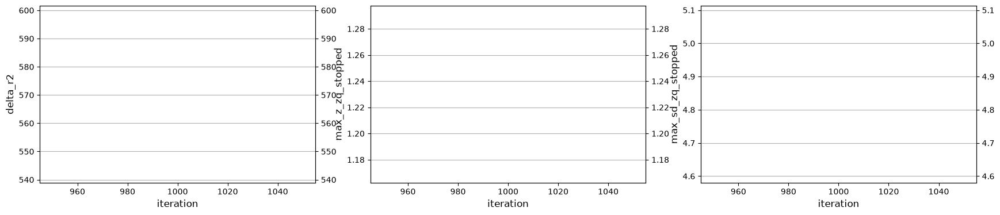

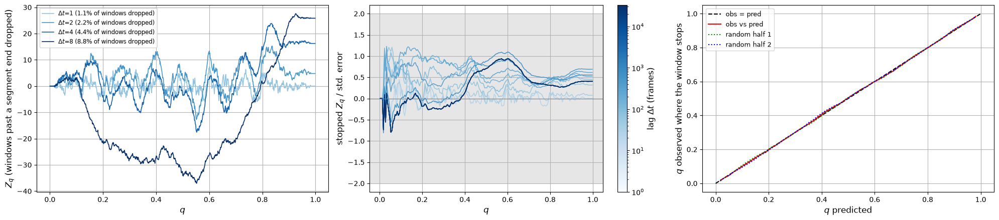

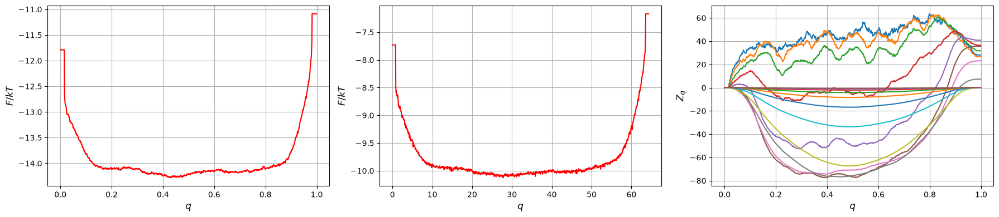

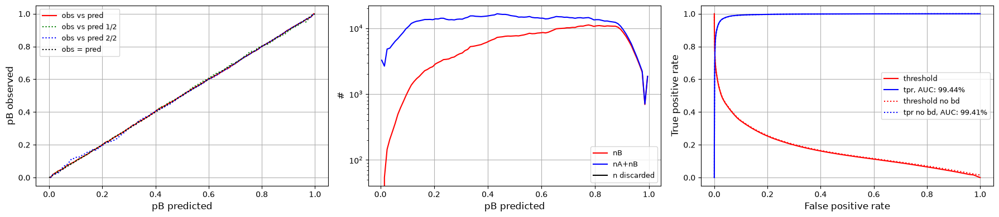

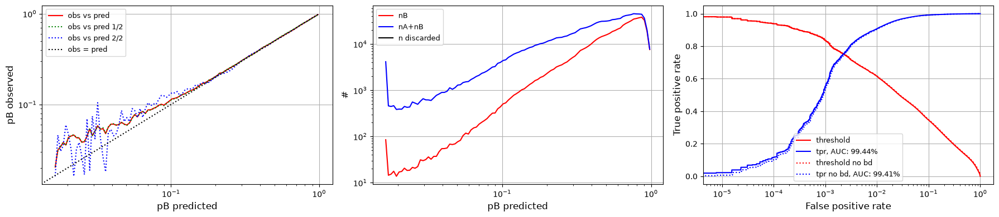

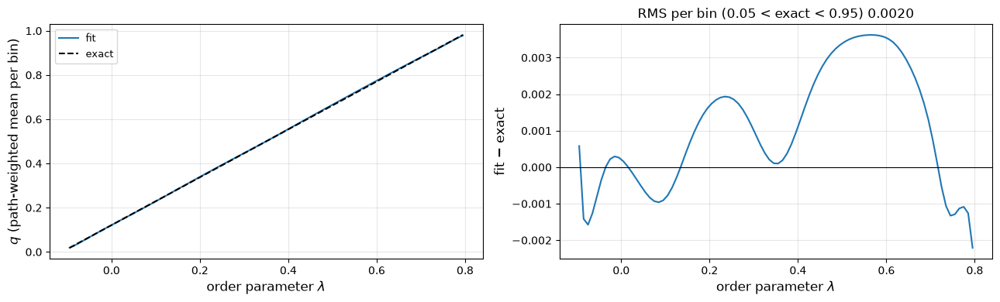

seed 0, 1000 iterations (warm-up: envelope 1000000, gamma 0.0) | RMS(fit - exact) 0.0020
#=1500, dr2=570.335, zqs_z=1.44, sdzqs=4.79538, |dx|=0.000205685, time=2.22065
#=2000, dr2=570.322, zqs_z=1.47983, sdzqs=4.80548, |dx|=4.19207e-05, time=4.44581
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_rej_trunc200/seed0/it2000 ---


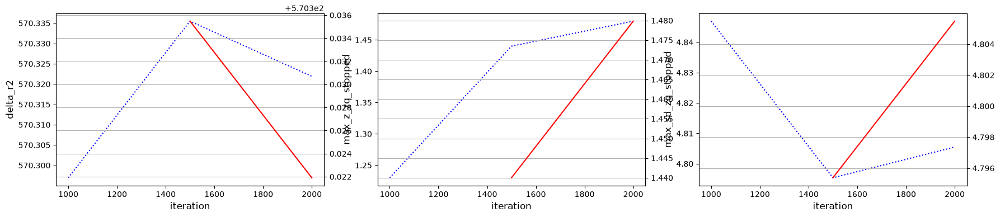

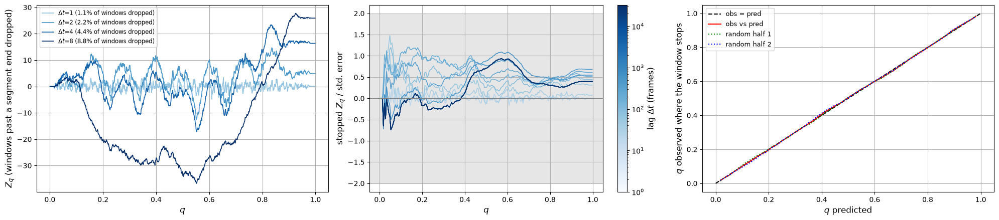

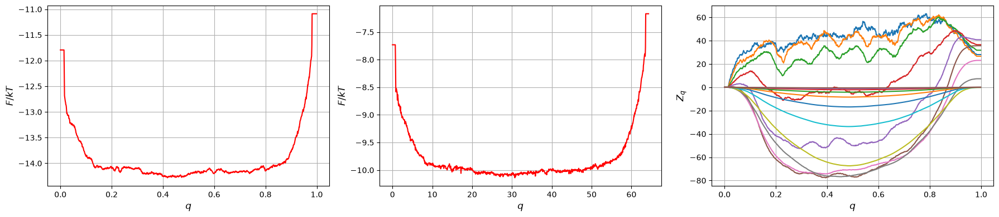

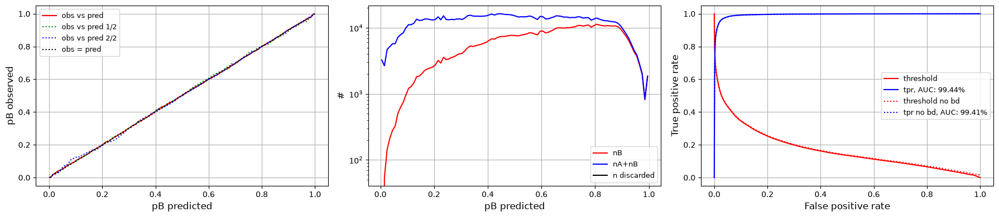

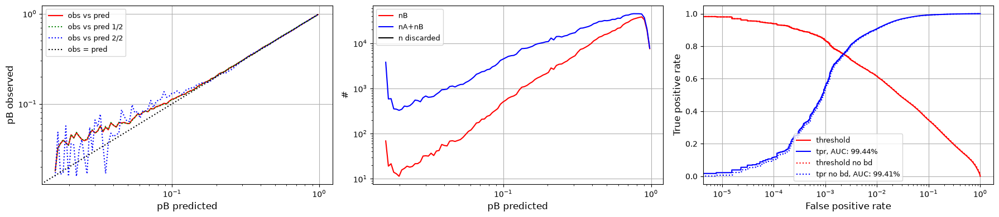

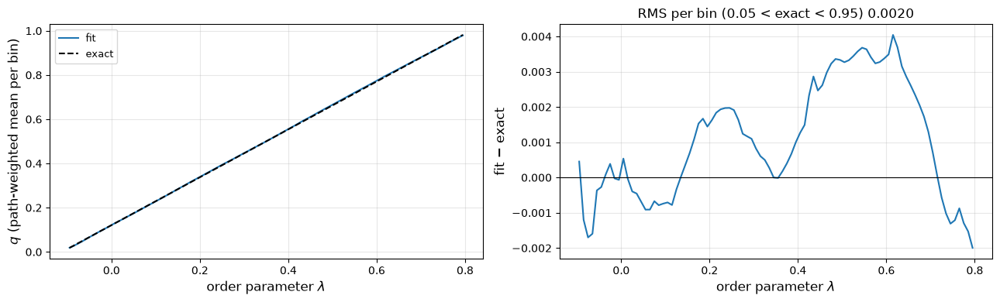

seed 0, 2000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0020
#=2500, dr2=570.331, zqs_z=1.48413, sdzqs=4.81016, |dx|=3.70373e-05, time=2.21722
#=3000, dr2=570.344, zqs_z=1.45716, sdzqs=4.78504, |dx|=4.31137e-05, time=4.44029
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_rej_trunc200/seed0/it3000 ---


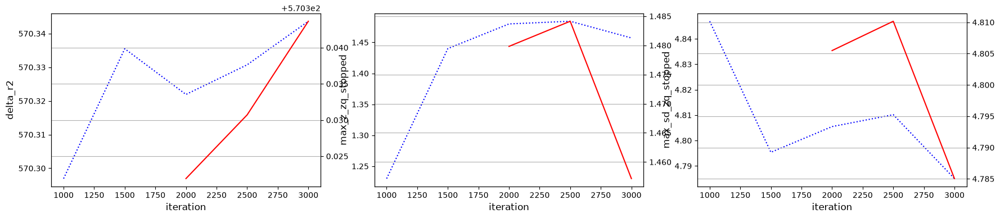

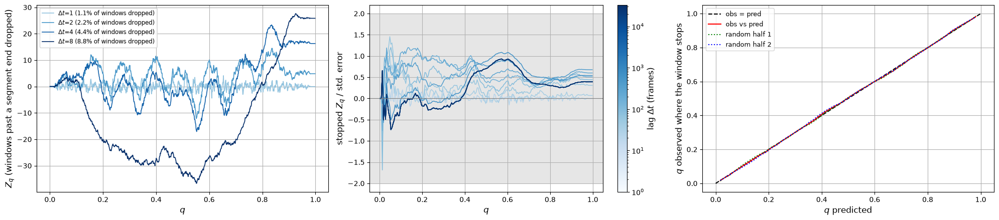

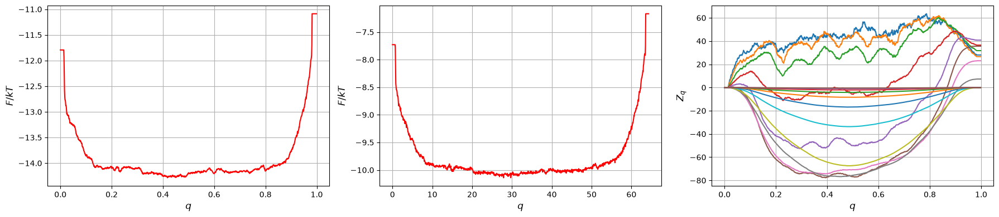

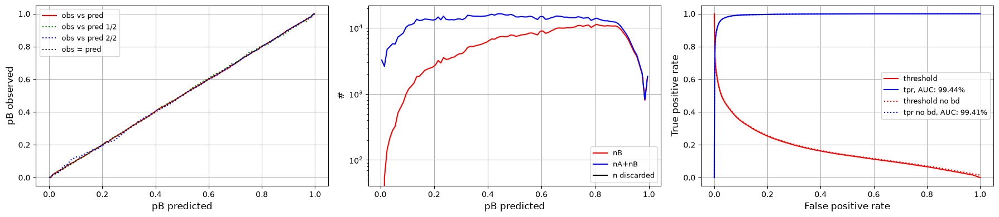

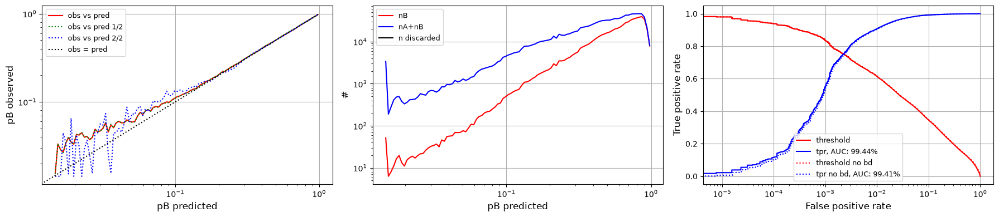

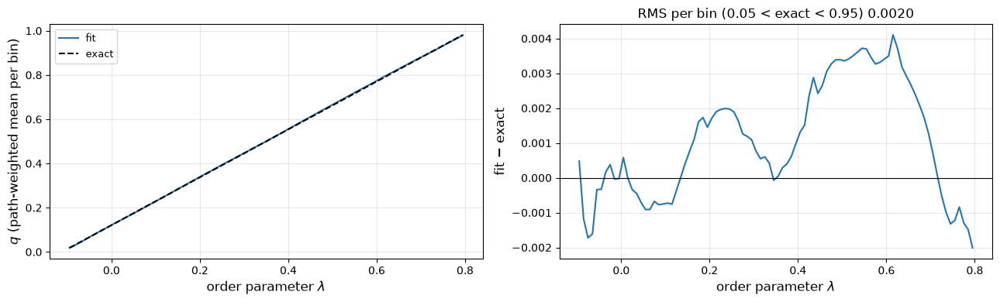

seed 0, 3000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0020
#=3500, dr2=570.338, zqs_z=1.47191, sdzqs=4.7911, |dx|=4.24867e-05, time=2.20963
#=4000, dr2=570.327, zqs_z=1.47266, sdzqs=4.78274, |dx|=2.94343e-05, time=4.43055
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_rej_trunc200/seed0/it4000 ---


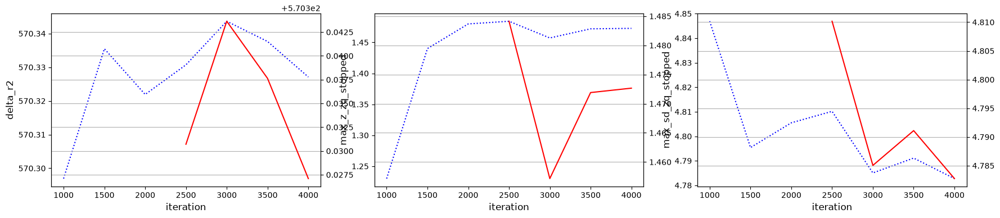

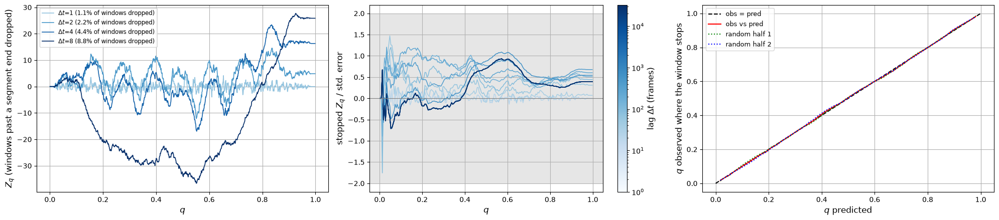

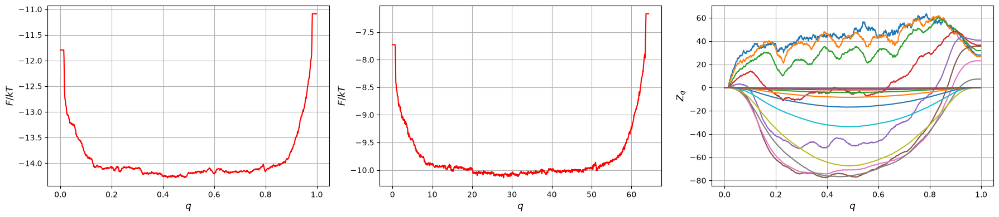

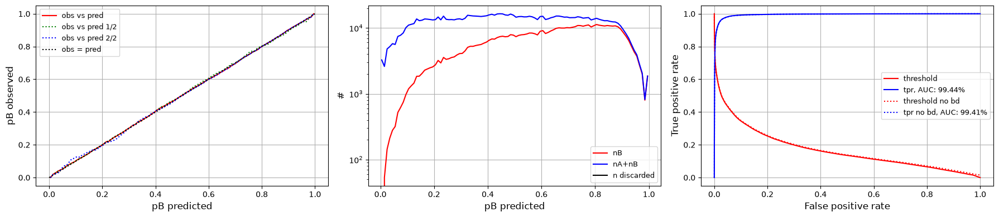

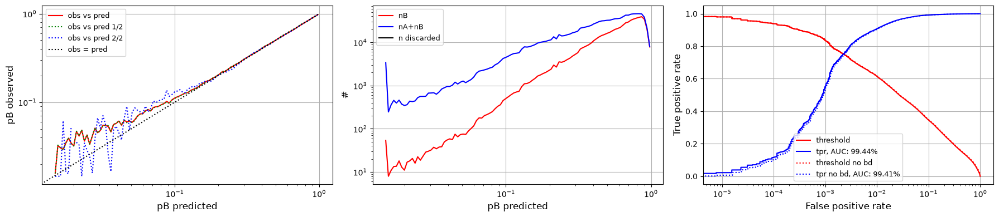

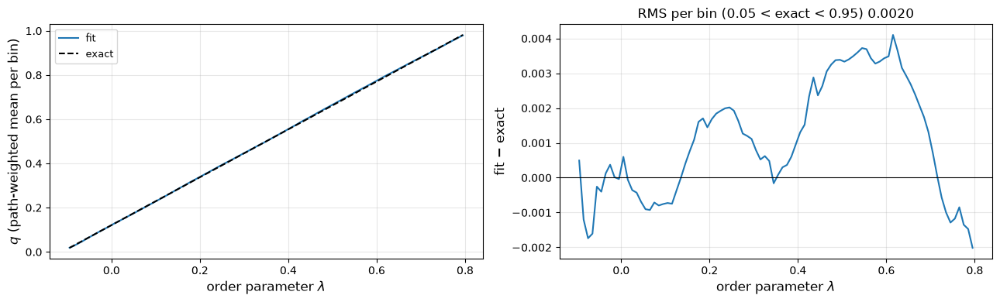

seed 0, 4000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0020
#=4500, dr2=570.33, zqs_z=1.4558, sdzqs=4.79653, |dx|=3.41384e-05, time=2.20516
#=5000, dr2=570.323, zqs_z=1.46091, sdzqs=4.80096, |dx|=2.0351e-05, time=4.43258
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_rej_trunc200/seed0/it5000 ---


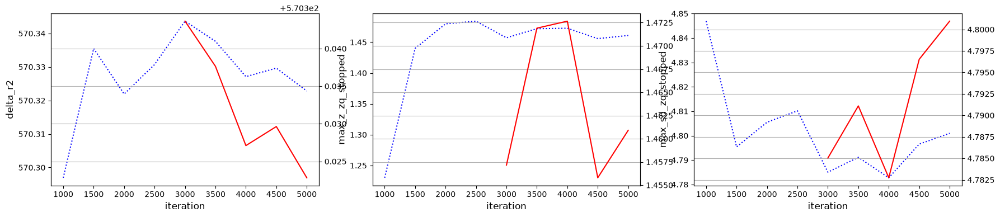

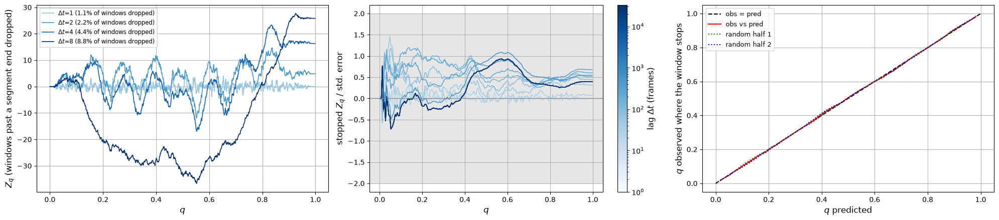

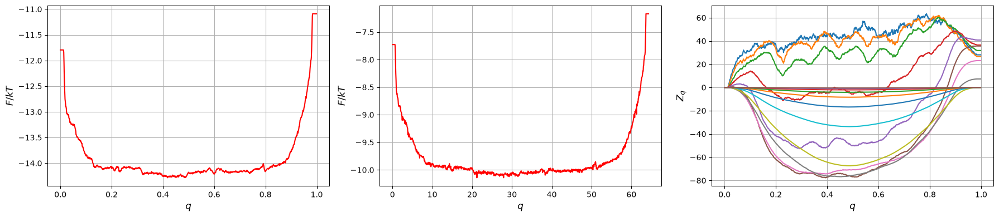

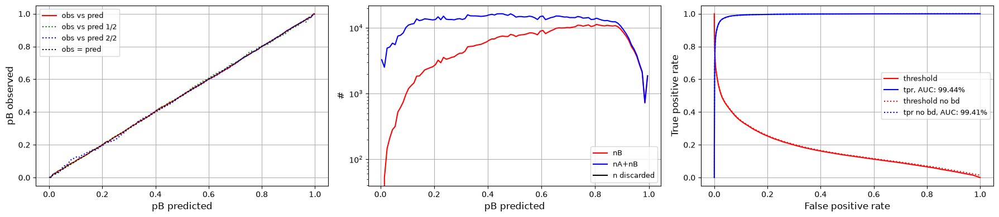

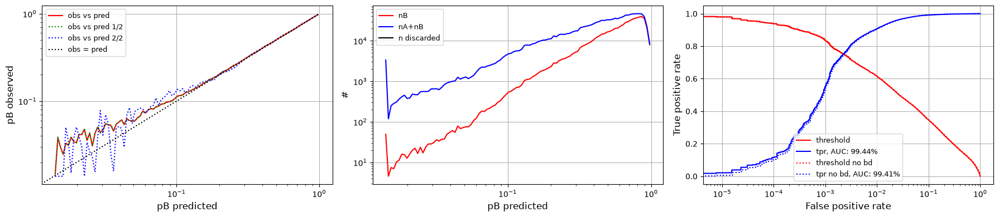

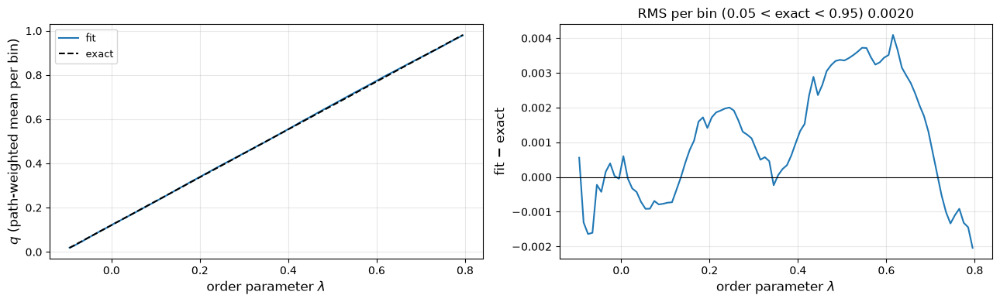

seed 0, 5000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0020
seed 0: | RMS(fit - exact) 0.0020
rev_rej_trunc200: done in 0.01 h, zqs_z 1.46, RMS(fit - exact) 0.0020

=== rev_rej_disc200: {'weights': 'rejections', 'reversed': True, 'cut': True, 'max_length': 200, 'long_pieces': 'discard', 'name': 'rev_rej_disc200'} ===
Interfaces from /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/logging.log: [-0.1, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
State A: order <= -0.1, state B: order >= 0.8
Found 10 ensemble folders in /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/001: loaded 1612 pieces, 34883 frames, total weight 4200, cut at M = -0.1 (26 pieces longer than 200 frames discarded)
  /home/staff7/fbsskr/Notebooks/Students/elias/data/simulations/sim_istar0br10intf/002: loaded 1940 pieces, 112675 frames, total weight 38

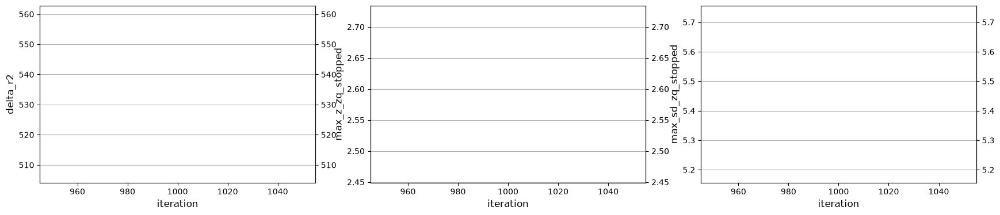

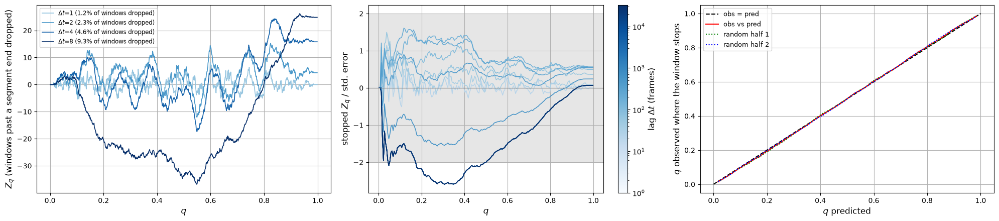

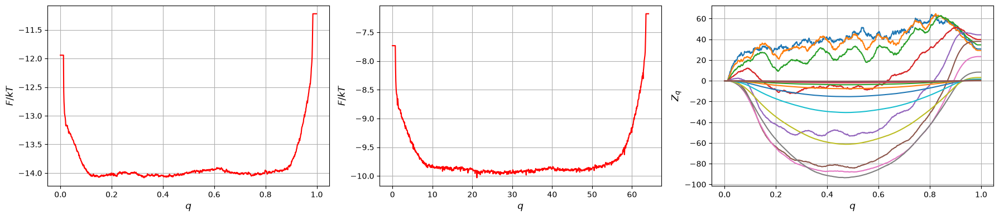

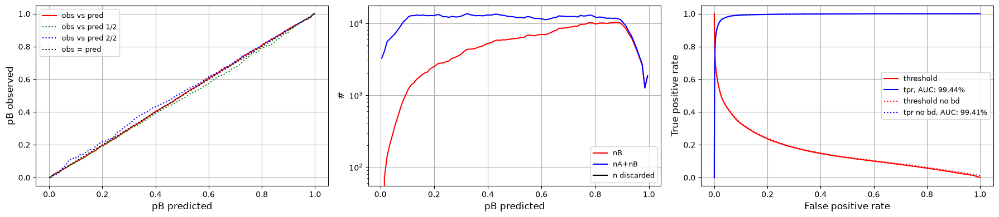

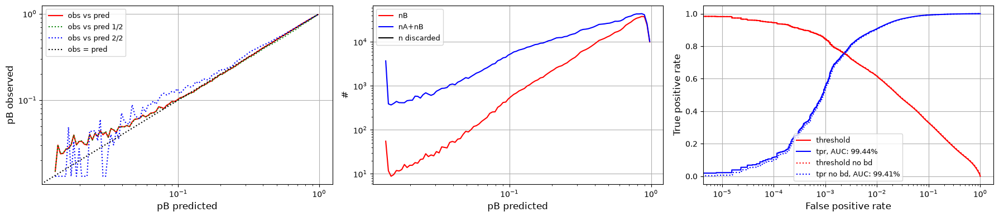

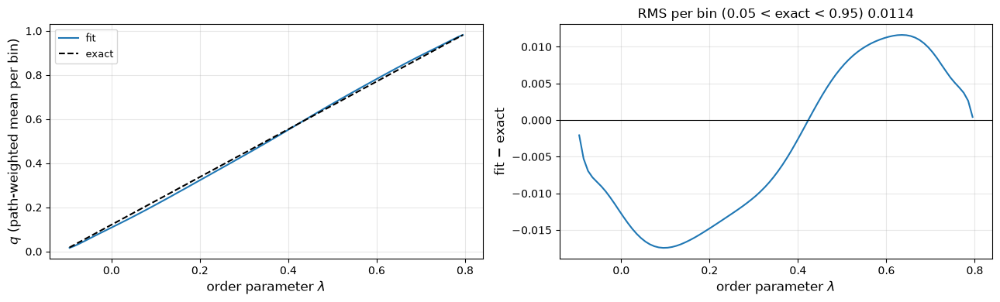

seed 0, 1000 iterations (warm-up: envelope 1000000, gamma 0.0) | RMS(fit - exact) 0.0116
#=1500, dr2=533.491, zqs_z=2.61287, sdzqs=5.46405, |dx|=0.000224248, time=1.9609
#=2000, dr2=533.544, zqs_z=2.61538, sdzqs=5.44196, |dx|=7.53842e-05, time=3.92759
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_rej_disc200/seed0/it2000 ---


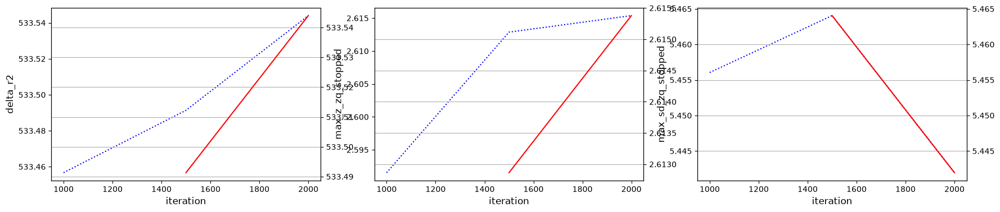

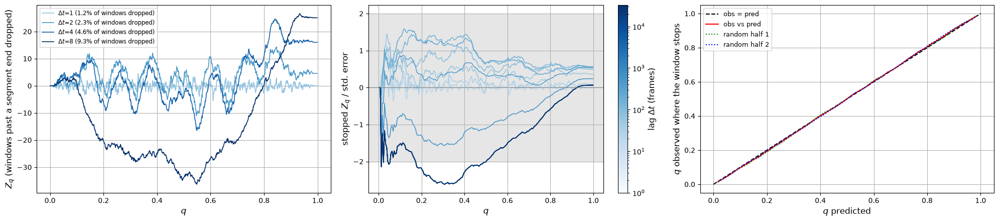

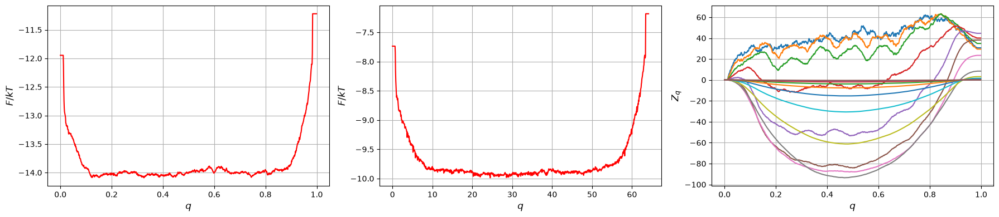

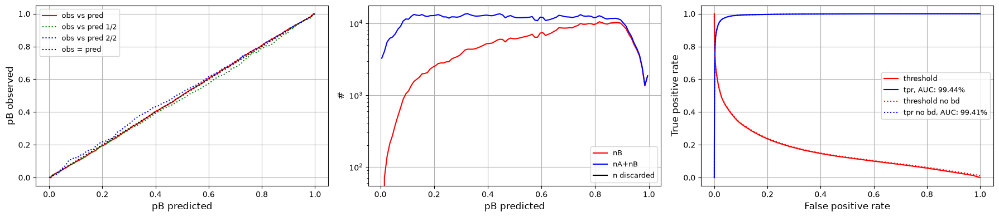

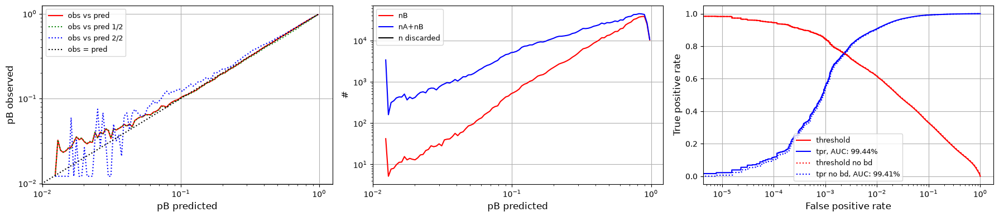

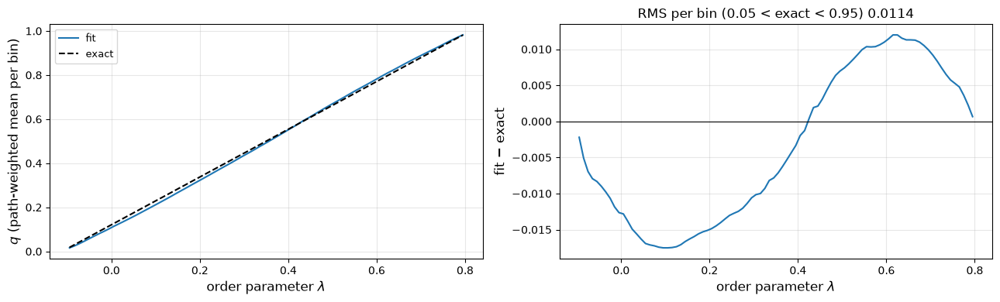

seed 0, 2000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0116
#=2500, dr2=533.511, zqs_z=2.6178, sdzqs=5.44742, |dx|=4.94716e-05, time=1.96241
#=3000, dr2=533.506, zqs_z=2.61311, sdzqs=5.44603, |dx|=8.40065e-05, time=3.92513
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_rej_disc200/seed0/it3000 ---


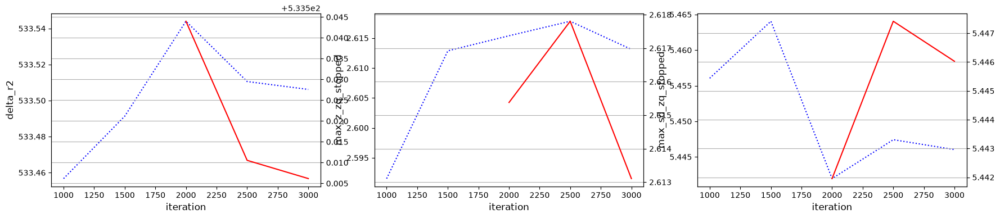

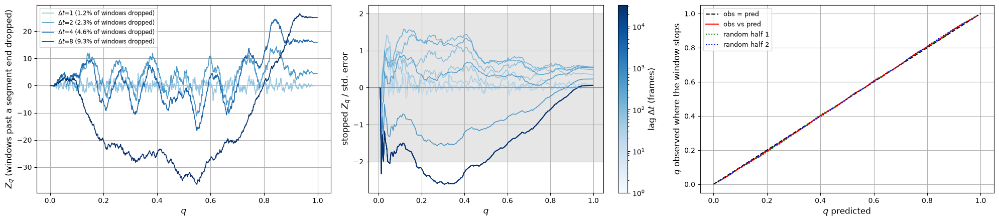

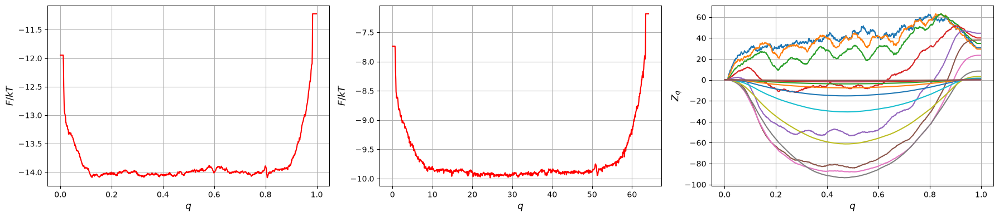

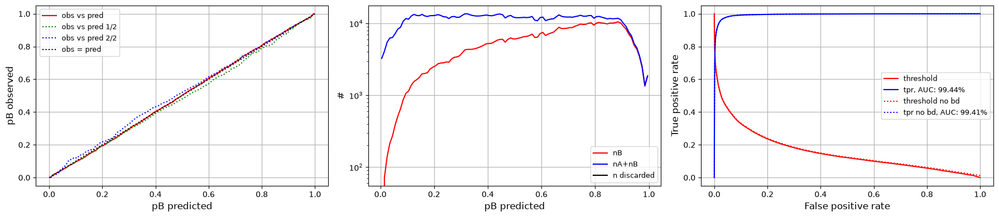

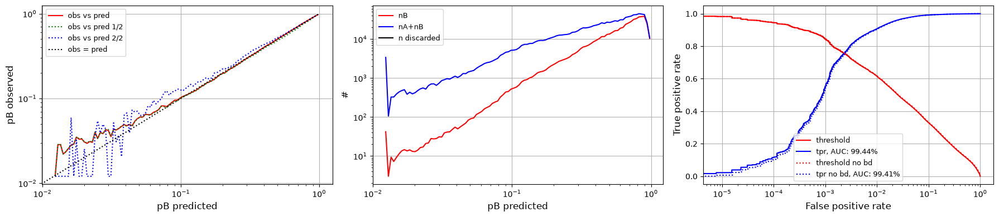

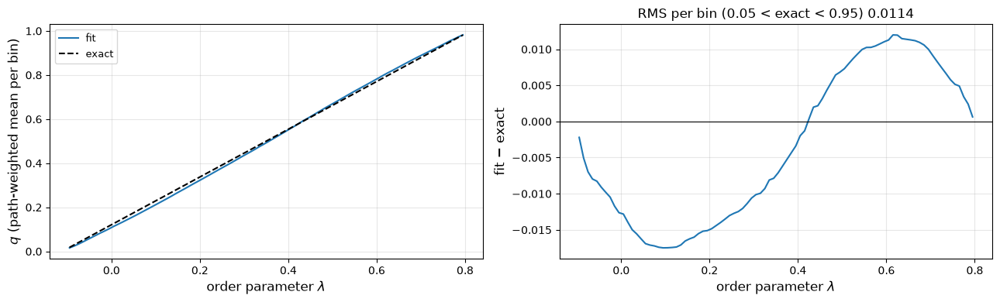

seed 0, 3000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0116
#=3500, dr2=533.483, zqs_z=2.61915, sdzqs=5.45452, |dx|=6.75748e-05, time=1.96201
#=4000, dr2=533.492, zqs_z=2.61784, sdzqs=5.44622, |dx|=3.87398e-05, time=3.93715
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_rej_disc200/seed0/it4000 ---


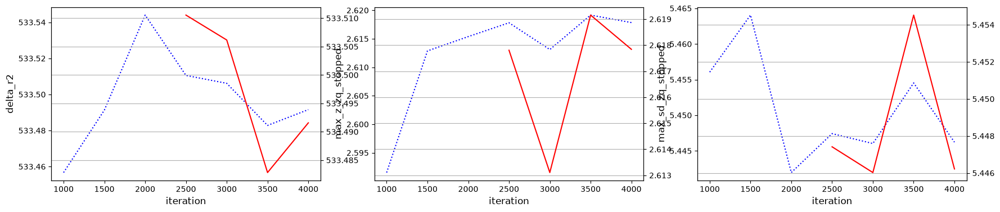

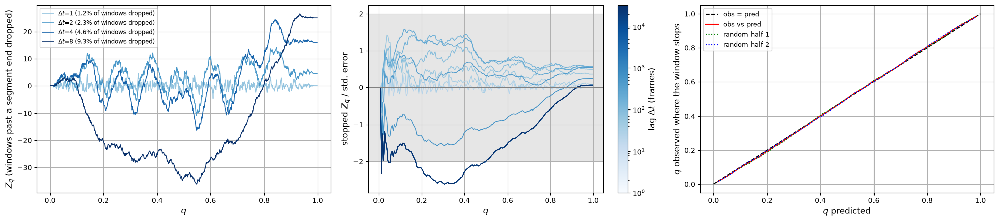

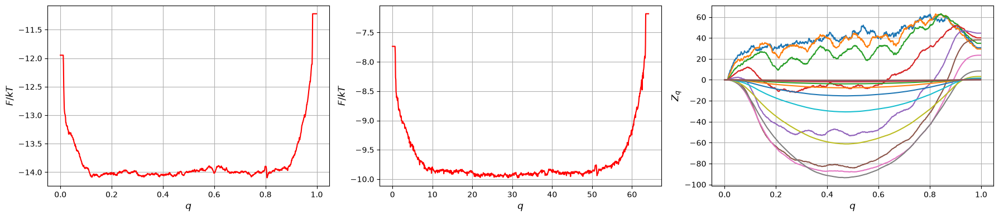

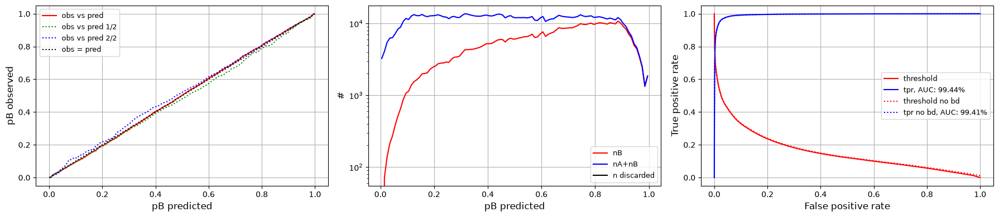

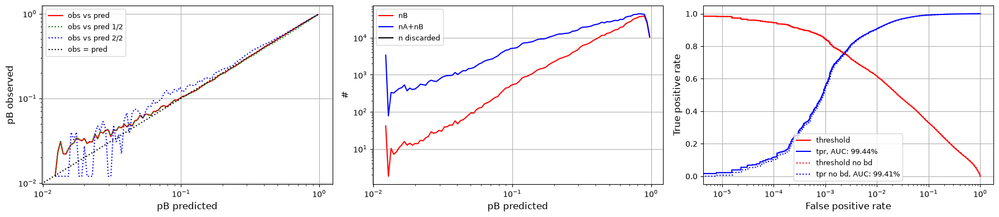

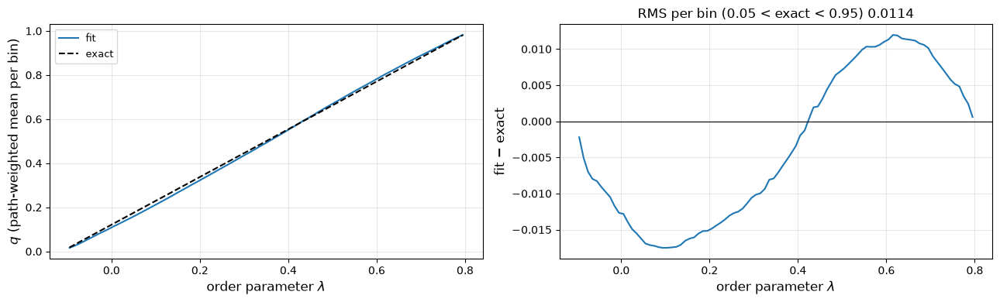

seed 0, 4000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0116
#=4500, dr2=533.504, zqs_z=2.61851, sdzqs=5.44363, |dx|=2.69195e-05, time=2.00965
#=5000, dr2=533.469, zqs_z=2.61883, sdzqs=5.44471, |dx|=3.15464e-05, time=4.03395
--- /home/staff7/fbsskr/Notebooks/Students/elias/optimalrcs/examples/figures/staple_compare/sim_istar0br10intf_p1000_s0/rev_rej_disc200/seed0/it5000 ---


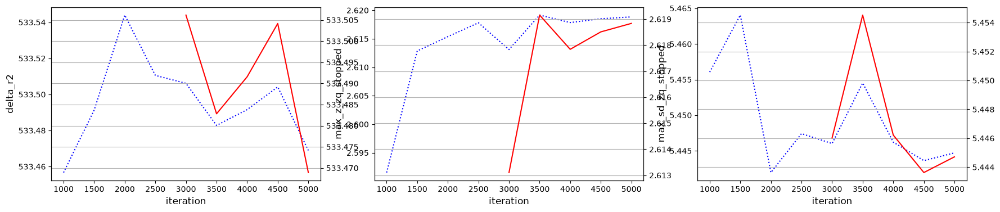

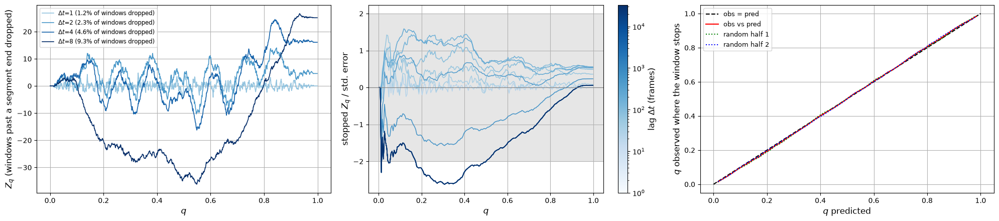

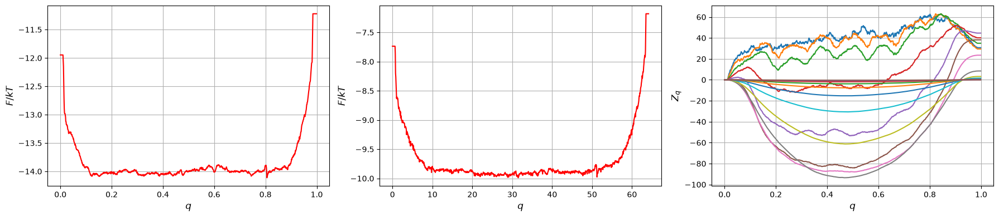

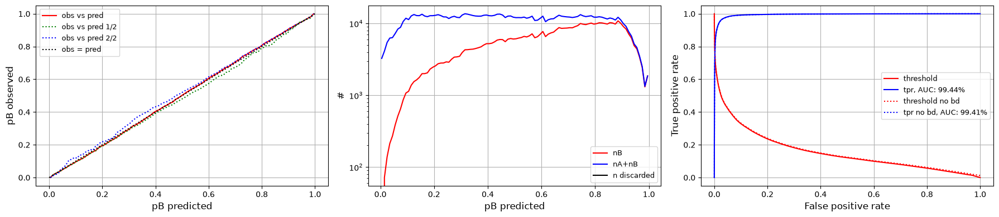

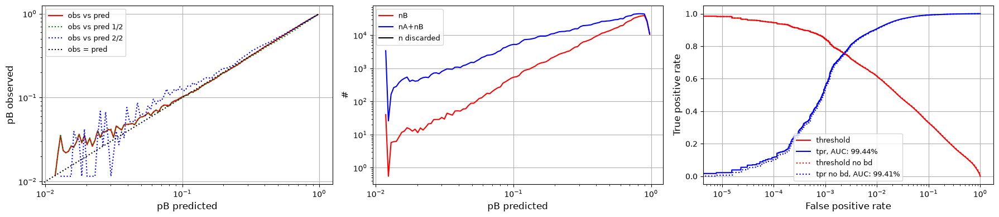

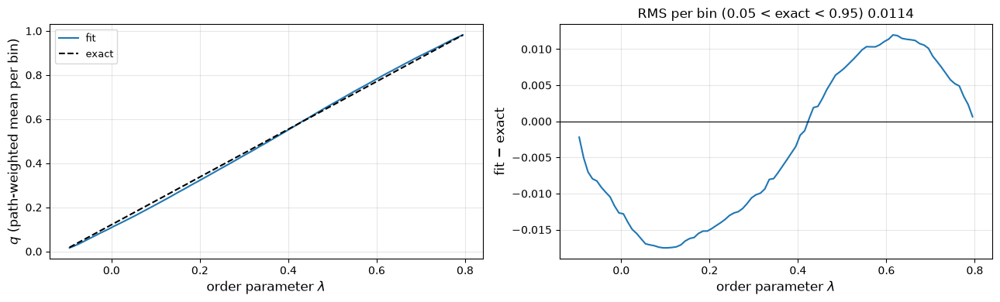

seed 0, 5000 iterations (main: envelope 0.01, gamma 0.0) | RMS(fit - exact) 0.0116
seed 0: | RMS(fit - exact) 0.0116
rev_rej_disc200: done in 0.01 h, zqs_z 2.62, RMS(fit - exact) 0.0116


In [9]:
summaries = {}
for cfg in CONFIGS:
    name = cfg['name']
    if name not in RUN:
        continue
    folder = f'{OUT}/{name}'
    path = f'{folder}/summary.npz'
    if os.path.exists(path) and not RERUN:
        summaries[name] = load_summary(path)
        if EDGES is None:   # keep the bins of the cached fits
            s = summaries[name]
            EDGES = (s['edges_lam'],) + ((s['edges_cv1'],) if 'edges_cv1' in s else ())
        print(f'{name}: loaded from {path}')
        continue
    print(f'\n=== {name}: {cfg} ===', flush=True)
    os.makedirs(folder, exist_ok=True)
    data = load_config(cfg)
    X_gpu = cp.asarray(data.X, dtype=cp.float64)
    t0 = time.time()
    _, q = seed_runs.run_seeds(
        optimalrcs, make_q_for(data),
        comp_y=lambda: X_gpu[:, np.random.randint(X_gpu.shape[1])],
        fit_kw=FIT_KW, seeds=[FIT_SEED], max_iter=MAX_ITER, chunk=CHUNK, out_dir=folder,
        envelope=ENVELOPE, gamma=GAMMA,
        warmup_iter=WARMUP_ITER, warmup_envelope=WARMUP_ENVELOPE, warmup_gamma=GAMMA,
        plots=PLOTS, plot_options=dict(metrics=METRICS_PLOTTED),
        extra_plot=make_extras(data), report=make_report(data),
    )
    s = summarize(q, data, cfg, time.time() - t0)
    np.savez(path, **s)
    summaries[name] = s
    print(f'{name}: done in {s["t_fit"] / 3600:.2f} h, zqs_z {s["hist_max_z_zq_stopped"][-1]:.2f}'
          + (f', RMS(fit - exact) {s["rms_frames"]:.4f}' if 'rms_frames' in s else ''), flush=True)
    del q, data, X_gpu
    cp.get_default_memory_pool().free_all_blocks()

## 5. Comparison

**Table.** Data size, the final and lowest `zqs_z` of the run (own data; about 2 or less is consistent), and with the exact committor the RMS of fit − exact over frames with 0.05 < q_exact < 0.95 (path-weighted), and over the bins in that range ((λ, CV 1) bins for 2D data, λ bins for 1D).

In [12]:
rows = []
for name, s in summaries.items():
    cfg = json.loads(str(s['cfg']))
    z = s['hist_max_z_zq_stopped']
    rows.append(dict(name=name, weights=cfg['weights'], reversed=cfg['reversed'], cut=cfg['cut'],
                     max_length=cfg['max_length'], long_pieces=cfg['long_pieces'] if cfg['max_length'] else '',
                     paths=int(s['n_paths']), pieces=int(s['n_pieces']), frames=int(s['n_frames']),
                     zqs_z_final=z[-1] if len(z) else np.nan, zqs_z_min=z[1:].min() if len(z) > 1 else np.nan,
                     rms_frames=s.get('rms_frames', np.nan), rms_bins=s.get('rms_bins', np.nan),
                     fit_hours=s['t_fit'] / 3600))
table = pd.DataFrame(rows).set_index('name')
os.makedirs(OUT, exist_ok=True)
table.to_csv(f'{OUT}/comparison.csv')
#table.style.format({'zqs_z_final': '{:.2f}', 'zqs_z_min': '{:.2f}', 'rms_frames': '{:.4f}', 'rms_bins': '{:.4f}', 'fit_hours': '{:.2f}', 'frames': '{:,}'})
# plain rounding (DataFrame.style needs jinja2, which this environment does not have)
table.round({'zqs_z_final': 2, 'zqs_z_min': 2, 'rms_frames': 4, 'rms_bins': 4, 'fit_hours': 2})

,weights,reversed,cut,max_length,long_pieces,paths,pieces,frames,zqs_z_final,zqs_z_min,rms_frames,rms_bins,fit_hours
name,,,,,,,,,,,,,
fwd_rej,rejections,False,True,NaN,,8822,8822,631092,1.14,1.02,0.0068,0.0066,0.01
rev_rej,rejections,True,True,NaN,,9000,17638,1268754,1.41,1.31,0.0022,0.0021,0.01
fwd_staple,staple,False,True,NaN,,8822,8822,631092,1.59,1.57,0.0149,0.0146,0.01
rev_staple,staple,True,True,NaN,,9000,17638,1268754,1.36,1.36,0.0098,0.0103,0.01
fwd_none,none,False,True,NaN,,8822,8822,631092,2.62,2.51,0.0176,0.0171,0.01
rev_none,none,True,True,NaN,,9000,17638,1268754,2.27,2.27,0.0113,0.0112,0.01
nocut_rej,rejections,False,False,NaN,,9000,9000,1071498,3.73,3.73,0.1062,0.1130,0.01
rev_rej_trunc200,rejections,True,True,200.0,truncate,9000,17638,1241665,1.46,1.23,0.0020,0.0020,0.01
rev_rej_disc200,rejections,True,True,200.0,discard,8951,17026,1119265,2.62,2.59,0.0116,0.0114,0.01


**Piece lengths and convergence.** Left: the distribution of piece lengths of every configuration, with `MAX_LENGTH`; a limit removes the tail to its right (truncated pieces pile up at the limit). Right: `zqs_z` over the iterations (warm-up included).

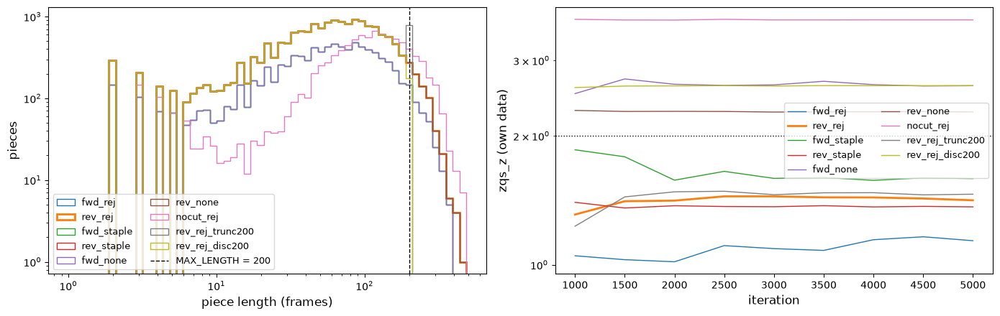

In [13]:
names = list(summaries)
colors = {n: plt.cm.tab10(i % 10) for i, n in enumerate(names)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
longest = max(s['piece_lengths'].max() for s in summaries.values())
bins = np.logspace(0, np.log10(longest + 1), 60)
for n, s in summaries.items():
    ax1.hist(s['piece_lengths'], bins=bins, histtype='step', color=colors[n], label=n,
             lw=2 if n == BASELINE else 1)
ax1.axvline(MAX_LENGTH, color='k', ls='--', lw=1, label=f'MAX_LENGTH = {MAX_LENGTH}')
ax1.set(xscale='log', yscale='log', xlabel='piece length (frames)', ylabel='pieces')
ax1.legend(ncol=2)

for n, s in summaries.items():
    it, z = s['hist_iter'], s['hist_max_z_zq_stopped']
    if len(z) > 1:
        ax2.plot(it[1:], z[1:], color=colors[n], label=n, lw=2 if n == BASELINE else 1)
ax2.axhline(2, color='k', ls=':', lw=1)
ax2.set(yscale='log', xlabel='iteration', ylabel='zqs_z (own data)')
ax2.legend(ncol=2)
fig.tight_layout()
fig.savefig(f'{OUT}/lengths_convergence.png', dpi=100)
plt.show()

**Committor along λ** (both systems). Top: the path-weighted mean q per λ bin (free frames) of every fit; dashed black: the exact committor averaged the same way over the `BASELINE` frames. Bottom: fit − exact, each on its own frames (so differences in which frames a configuration has do not show up as an error), or fit − `BASELINE` without the exact committor. For 1D data this is the full comparison; for 2D data the mean over CV 1 can hide errors of opposite sign, which the maps below show.

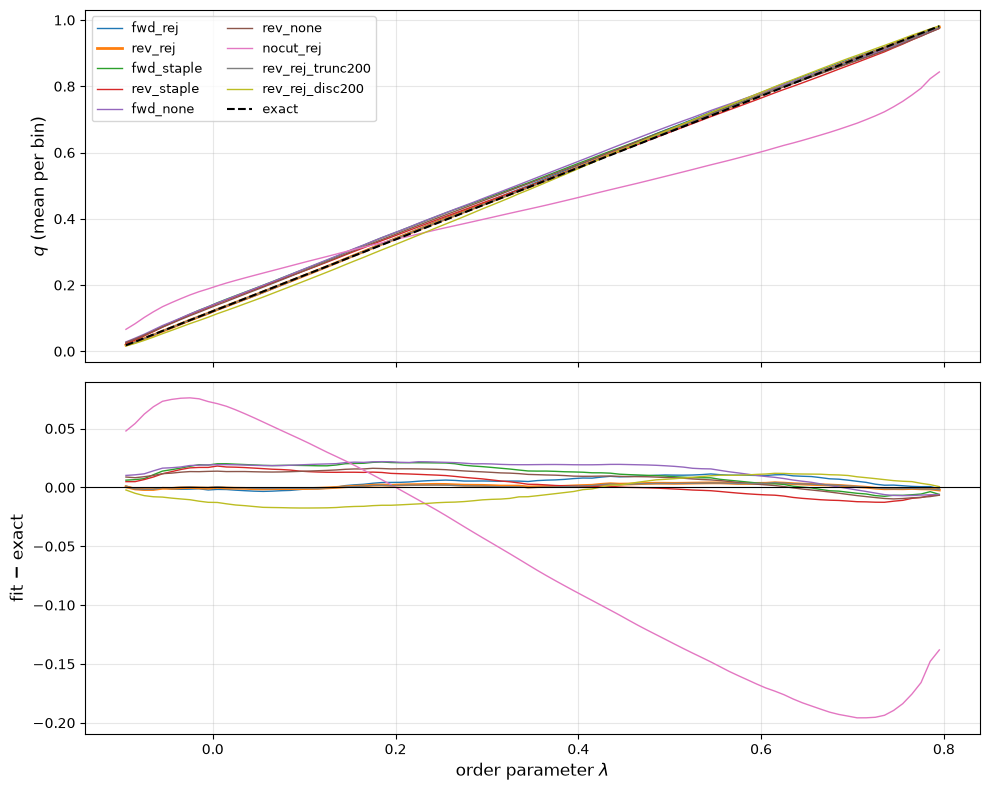

In [14]:
has_ref = all('prof_exact' in s for s in summaries.values())
base = summaries.get(BASELINE, next(iter(summaries.values())))
e = base['edges_lam']
mid = (e[1:] + e[:-1]) / 2

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for n, s in summaries.items():
    lw = 2 if n == BASELINE else 1
    ax1.plot(mid, s['prof_fit'], color=colors[n], lw=lw, label=n)
    diff = s['prof_fit'] - (s['prof_exact'] if has_ref else base['prof_fit'])
    ax2.plot(mid, diff, color=colors[n], lw=lw, label=n)
if has_ref:
    ax1.plot(mid, base['prof_exact'], 'k--', lw=1.5, label='exact')
ax1.set(ylabel='$q$ (mean per bin)')
ax1.legend(ncol=2)
ax1.grid(alpha=0.3)
ax2.axhline(0, color='k', lw=0.8)
ax2.set(xlabel=LABELS[0], ylabel='fit $-$ exact' if has_ref else f'fit $-$ {BASELINE}')
ax2.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(f'{OUT}/profiles.png', dpi=100)
plt.show()

**Maps** (2D data only: two entries in `EDGES`). One panel per configuration: fit − exact per (λ, CV 1) bin with its RMS over the bins where 0.05 < q_exact < 0.95 (or fit − `BASELINE` without the exact committor), plus the exact committor (or the `BASELINE` fit) in the first panel. Grey: `CONTOURS` of the potential; dashed: q = 0.1, 0.5, 0.9 of the exact committor.

In [15]:
DIFF_LIM = 0.15                    # colour range of the difference maps

if all('map_fit' in s for s in summaries.values()):
    e1, e2 = base['edges_lam'], base['edges_cv1']
    m1, m2 = (e1[1:] + e1[:-1]) / 2, (e2[1:] + e2[:-1]) / 2
    ref_map = base['map_exact'] if has_ref else base['map_fit']
    panels = [(ref_map, 'exact committor' if has_ref else f'{BASELINE} (fit)', 'coolwarm', (0, 1))]
    for n, s in summaries.items():
        if has_ref:
            panels.append((s['map_fit'] - s['map_exact'], f'{n} $-$ exact, RMS {s["rms_bins"]:.4f}',
                           'PuOr', (-DIFF_LIM, DIFF_LIM)))
        elif n != BASELINE:
            panels.append((s['map_fit'] - base['map_fit'], f'{n} $-$ {BASELINE}', 'PuOr', (-DIFF_LIM, DIFF_LIM)))

    n_cols = 3
    n_rows = -(-len(panels) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 3.8 * n_rows), squeeze=False)
    for ax, (M, title, cmap, (lo, hi)) in zip(axes.ravel(), panels):
        im = ax.pcolormesh(e1, e2, M.T, cmap=cmap, vmin=lo, vmax=hi)
        if CONTOURS is not None:
            g1, g2, V, lev = CONTOURS
            ax.contour(g1, g2, V.T, levels=lev, colors='0.45', linewidths=0.5)
        ax.contour(m1, m2, np.nan_to_num(ref_map, nan=0.5).T, levels=[0.1, 0.5, 0.9],
                   colors='k', linewidths=0.8, linestyles='--')
        ax.set(title=title, xlabel=LABELS[0], ylabel=LABELS[1] if len(LABELS) > 1 else 'CV 1',
               xlim=(e1[0], e1[-1]), ylim=(e2[0], e2[-1]))
        fig.colorbar(im, ax=ax)
    for ax in axes.ravel()[len(panels):]:
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(f'{OUT}/maps.png', dpi=100)
    plt.show()
else:
    print('Profile along lambda only (one bin axis in EDGES): no maps.')

Profile along lambda only (one bin axis in EDGES): no maps.


**Per-configuration plots.** Every fit's plots after the warm-up and after every chunk are in `<OUT>/<name>/seed<FIT_SEED>/it<N>_<plot>.png`: `metrics`, `tis` (stopped Z_q, short-lag Z_q and stopped observed-vs-predicted, on its own data), `feps`, `obs_pred`, `obs_pred_log`, `q_profile` and, for 2D data, `q_map`.

**What to look for.**
- *Weighting:* with the cut and the same pieces, only the path weights differ. The weighting that matches the staple sampling should give the smallest fit − exact; a wrong one shifts q where ensembles with different weights overlap.
- *Reversed:* the mirrored pieces recover the frames the cut drops, near the start of each ensemble's window. If the forward-only fits are off mainly close to the interfaces where the pieces start, that is the missing data.
- *No cut:* the frames before the first M crossing are conditioned on crossing M, which pushes q up in front of M. Expect a systematic error even when its own `zqs_z` looks fine (on `1d_flat`, earlier runs gave RMS 0.12–0.13 without the cut against 0.005–0.024 with it).
- *Truncate vs discard:* truncation should agree with its untruncated configuration within the seed-to-seed spread (run two `FIT_SEED`s to see that spread); discarding drops the slow pieces and should show a bias.